In [1]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LATITUDE_FORMATTER, LONGITUDE_FORMATTER
import copy
from matplotlib import pyplot
from matplotlib import colors
from matplotlib import font_manager
import matplotlib.ticker as mticker
import numpy
import pandas
import random
import xarray as xr

In [2]:
numpy.seterr(invalid="ignore")

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Build Game Board

In [3]:
# Define map bounds
Min_Lon = 98
Max_Lon = 160
Min_Lat = 0
Max_Lat = 44

In [4]:
# Create initial map
def Initial_Map(Axis, Min_Lon, Max_Lon, Min_Lat, Max_Lat):
    pyplot.xlim(Min_Lon, Max_Lon)
    pyplot.ylim(Min_Lat, Max_Lat)
    Axis.set_xticks(numpy.arange(100,170,10))
    Axis.set_yticks(numpy.arange(0,50,10))
    Gridline_Major = Axis.gridlines(crs=ccrs.PlateCarree(), linewidth=1.5, color='darkgrey', linestyle='-')
    Gridline_Major.xlocator = mticker.FixedLocator(numpy.arange(100,170,10))
    Gridline_Major.ylocator = mticker.FixedLocator(numpy.arange(0,50,10))
    Gridline_Minor = Axis.gridlines(crs=ccrs.PlateCarree(), linewidth=1, color='darkgrey', linestyle='-')
    Gridline_Minor.xlocator = mticker.FixedLocator(numpy.arange(Min_Lon,Max_Lon,2))
    Gridline_Minor.ylocator = mticker.FixedLocator(numpy.arange(Min_Lat,Max_Lat,2))

In [5]:
# Open map grid file
Map_DF = pandas.read_csv("Map_Pacific.csv", index_col=0)
Map_DF.index = Map_DF.index.astype(int)
Map_DF.columns = Map_DF.columns.astype(int)
Map_Grid = Map_DF.values.astype(int)
Lat_Vals = Map_DF.index.astype(float)
Lon_Vals = Map_DF.columns.astype(float)
Lon_Grid, Lat_Grid = numpy.meshgrid(Lon_Vals, Lat_Vals)

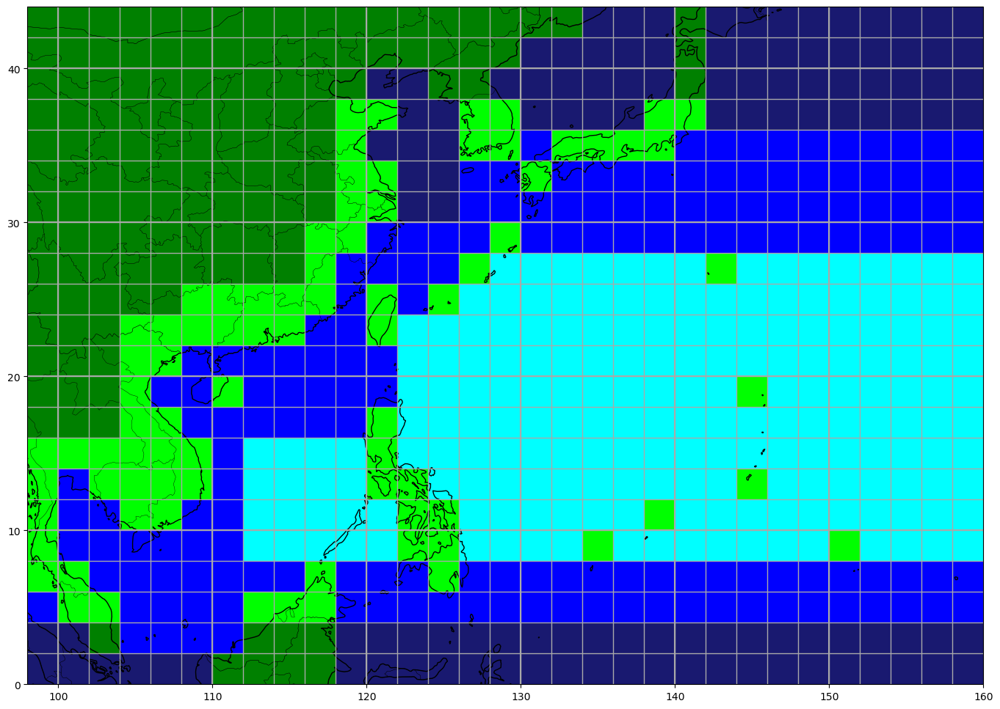

In [6]:
# Plot initial map
Fig = pyplot.figure(figsize=(25,12))
Axis = Fig.add_subplot(1,1,1, projection=ccrs.PlateCarree())
Initial_Map(Axis, Min_Lon, Max_Lon, Min_Lat, Max_Lat)
C_Map = colors.ListedColormap(['aqua', 'blue', 'midnightblue', 'lime', 'green'])
Axis.pcolormesh(Lon_Grid, Lat_Grid, Map_Grid, cmap=C_Map, shading='auto', vmin=1, vmax=5)
Axis.coastlines()
Axis.add_feature(cfeature.BORDERS, linewidth=0.3)
Axis.add_feature(cfeature.STATES, linewidth=0.2)

In [7]:
# Open cities file
Cities_DF = pandas.read_csv("Cities_Pacific.csv")

# Open genesis points file
Genesis_DF = pandas.read_csv("Genesis_Pacific.csv")

In [8]:
# City plotting
def City_Plot(Axis, Lon, Lat, Type):
    if Type == "Town":
        Marker, Size, Colour = 'o', 80, 'red'
    elif Type == "Regular":
        Marker, Size, Colour = '^', 160, 'red'
    elif Type == "Metro":
        Marker, Size, Colour = 'p', 320, 'red'
    elif Type == "Mega":
        Marker, Size, Colour = '*', 728, 'red'
    elif Type == "Genesis":
        Marker, Size, Colour = 's', 48, 'gold'
    Axis.scatter(Lon, Lat, marker=Marker, s=Size, c=Colour)

In [9]:
# City labels
def City_Label(Axis, City, Loc, Lon, Lat, Col, Genesis):
    if Genesis == False:
        Size = 14
    else:
        Size = 25
    if Loc == 0:
        Axis.text(Lon, Lat-0.08, City, ha='center', va='center', fontdict={'size':Size}, color=Col)
    elif Loc == 1:
        Axis.text(Lon+0.95, Lat, City, ha='left', va='center', fontdict={'size':Size}, color=Col)
    elif Loc == 2:
        Axis.text(Lon, Lat-1.45, City, ha='center', va='center', fontdict={'size':Size}, color=Col)
    elif Loc == 3:
        Axis.text(Lon-0.95, Lat, City, ha='right', va='center', fontdict={'size':Size}, color=Col)
    elif Loc == 4:
        Axis.text(Lon, Lat+1.38, City, ha='center', va='center', fontdict={'size':Size}, color=Col)

In [10]:
# Legend
def Plot_Legend(Axis):
    Axis.scatter(0,0, marker='s', s=320, c='aqua', label='Zone A (Water)')
    Axis.scatter(0,0, marker='s', s=320, c='blue', label='Zone B (Water)')
    Axis.scatter(0,0, marker='s', s=320, c='midnightblue', label='Zone C (Water)')
    Axis.scatter(0,0, marker='s', s=320, c='lime', label='Zone D (Land)')
    Axis.scatter(0,0, marker='s', s=320, c='green', label='Zone E (Land)')
    Axis.scatter(0,0, marker='*', s=518, c='red', label='Megacity')
    Axis.scatter(0,0, marker='p', s=218, c='red', label='Metropolis')
    Axis.scatter(0,0, marker='^', s=138, c='red', label='Regular City')
    Axis.scatter(0,0, marker='o', s=80, c='red', label='Township')
    Axis.scatter(0,0, marker='s', s=48, c='gold', label='Genesis Points')
    pyplot.legend(loc=2, fontsize=15)

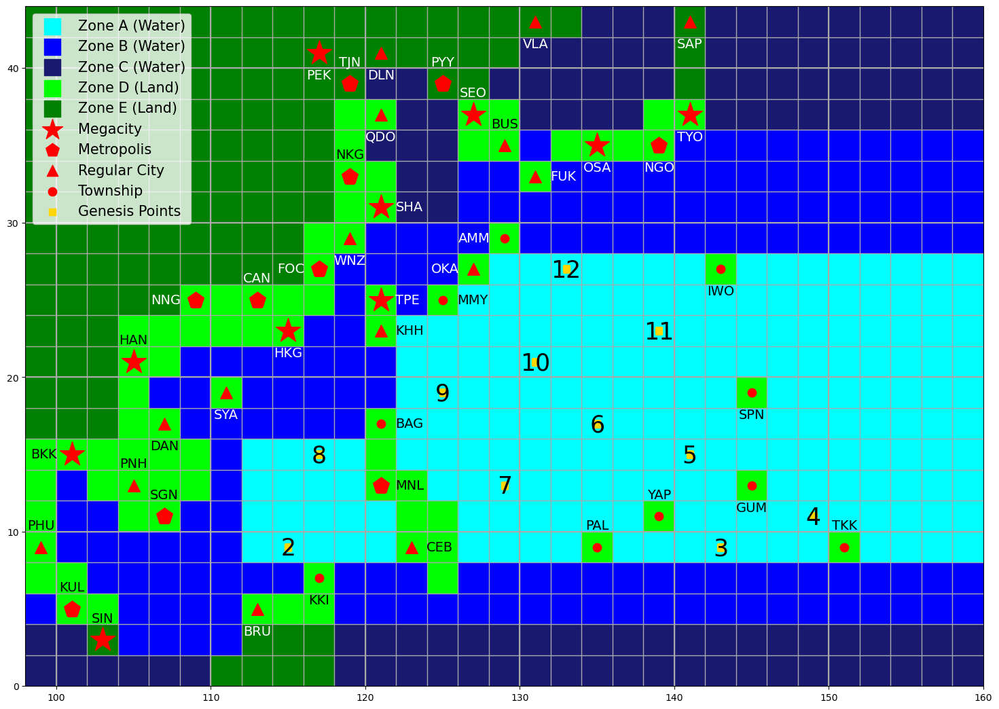

In [11]:
# Plot game board
def Plot_Board(Cities_DF, Genesis_DF, Lon_Grid, Lat_Grid, Map_Grid, C_Map):
    Fig = pyplot.figure(figsize=(25,13))
    Axis = Fig.add_subplot(1,1,1, projection=ccrs.PlateCarree())
    Initial_Map(Axis, Min_Lon, Max_Lon, Min_Lat, Max_Lat)
    Axis.pcolormesh(Lon_Grid, Lat_Grid, Map_Grid, cmap=C_Map, shading='auto', vmin=1, vmax=5)
    for i in range(len(Cities_DF)):
        City_Plot(Axis, Cities_DF["Lon"][i], Cities_DF["Lat"][i], Cities_DF["Type"][i])
        City_Label(Axis, Cities_DF["City"][i], Cities_DF["Label Loc"][i], Cities_DF["Lon"][i], Cities_DF["Lat"][i], Cities_DF["Label Colour"][i], False)
    for j in range(len(Genesis_DF)):
        City_Plot(Axis, Genesis_DF["Lon"][j], Genesis_DF["Lat"][j], "Genesis")
        City_Label(Axis, Genesis_DF["Point"][j], Genesis_DF["Label Loc"][j], Genesis_DF["Lon"][j], Genesis_DF["Lat"][j], Genesis_DF["Label Colour"][j], True)
    Plot_Legend(Axis)
Plot_Board(Cities_DF, Genesis_DF, Lon_Grid, Lat_Grid, Map_Grid, C_Map)
Fig.savefig('Game_Map_Pacific', bbox_inches='tight')

## Initializing Game

In [12]:
# Roll dice
def Dice(n):
    Rolls = [numpy.random.randint(1, 6) for _ in range(n)]
    Result = sum(Rolls)
    return (Result)

In [13]:
# Assign genesis points and create player data dictionary
def Assign_Genesis_Points(Player_Names, Player_Colours, Genesis_DF, Map_DF):
    Taken_Positions = set()
    Player_Data = {}
    for Player in Player_Names:
        while True:
            
            # Roll dice
            Roll = Dice(2)
            if Roll not in Taken_Positions:
                Taken_Positions.add(Roll)
                print (f"{Player} rolled {Roll} and is assigned genesis point {Roll}.")
                
                # Find lat lon coordinates of genesis point
                Genesis_Row = Genesis_DF[Genesis_DF["Point"] == Roll]
                Lon = int(Genesis_Row.iloc[0]["Lon"])
                Lat = int(Genesis_Row.iloc[0]["Lat"])
                Zone = Map_DF.loc[Lat, Lon]
                
                # Initialize player data
                Colour = Player_Colours[Player]
                Player_Data[Player] = {"Colour": Colour, "Order": 0, "Round": 0, "Status": "Initialize", \
                                       "Genesis Point": Roll, "Lon": Lon, "Lat": Lat, "Zone": Zone, \
                                       "Hand": [], "Cards Played This Round": [], "Max Cards": 3, 
                                       "Prev Wm2": 0, "Remainder Wm2": 0, "Prev Lon Change": 0, "Prev Lat Change": 0, \
                                       "Intensity": 25, "Peak Intensity": 25, "ACE": 0, "Landfall Costs": 0, "Landfall Cities": []}
                break
                
            # If roll result is already taken, roll again
            else:
                print (f"{Player} rolled {Roll}, but genesis point {Roll} is already taken. Rolling again...")
    
    # Decide play order based on roll result
    Play_Order = sorted(Player_Names, key=lambda Name: Player_Data[Name]["Genesis Point"], reverse=True)
    Player_Data_Sorted = {Name: Player_Data[Name] for Name in Play_Order}
    for Order, Name in enumerate(Play_Order, start=1):
        Player_Data[Name]["Order"] = Order
    return (Play_Order, Player_Data_Sorted)

In [14]:
# Place pawn on board
def Place_Pawn(Lon, Lat, Colour):
    pyplot.scatter(Lon, Lat, s=383, c=Colour, edgecolors='black', linewidths=2.8, zorder=5)
    # Add Halo Around Pawn
    pyplot.scatter(Lon, Lat, s=728, c='white', edgecolors='black', linewidths=2, zorder=4)

In [15]:
# Plot current board
def Plot_Current_Board(Player_Data):
    Plot_Board(Cities_DF, Genesis_DF, Lon_Grid, Lat_Grid, Map_Grid, C_Map)
    for Player in Player_Data:
        Place_Pawn(Player_Data[Player]["Lon"], Player_Data[Player]["Lat"], Player_Data[Player]["Colour"])
    pyplot.show()

In [16]:
# Shuffle cards
def Shuffle_Cards(Cards):
    # Build full deck
    Deck = []
    for _, Row in Cards.iterrows():
        Deck.extend([Row["Card"]] * int(Row["Count"]))
        
    # Shuffle deck
    random.shuffle(Deck)
    return (Deck)

In [17]:
# Deal cards
def Deal_Cards(Deck, Player_Data, Cards_Per_Player):
    for i in range(Cards_Per_Player):
        for Player in Player_Data:
            Player_Data[Player]["Hand"].append(Deck.pop())
    return (Deck)

## Setup Game State

In [18]:
# Setup game state
def Setup_Game_State(n_Players, Ocean_ACE, Movement_Deck, Intensity_Deck, Action_Deck, Cities_DF):
    # Create game state dictionary
    Game_State = {"Round": 1, "Player Position": 1, "Status": "Initialize", \
    "Movement Deck": Movement_Deck, "Intensity Deck": Intensity_Deck, "Action Deck": Action_Deck, \
    "Movement Discard": [], "Intensity Discard": [], "Action Discard": [], \
    "Ocean ACE": Ocean_ACE, "Cities Budget": {}, "Effects": [], "Game End": False}

    # Define cities budget
    for i in range(len(Cities_DF)):
        Game_State["Cities Budget"][Cities_DF.iloc[i]["City"]] = Cities_DF.iloc[i]["Initial Budget"]
    return (Game_State)

In [19]:
# Save player data and game state history
def Save_State(Player_Data, Game_State, Player_Data_History, Game_State_History):
    Player_Data_History.append(copy.deepcopy(Player_Data))
    Game_State_History.append(copy.deepcopy(Game_State))

In [20]:
# Undo round
def Undo(Player_Data_History, Game_State_History):
    if len(Player_Data_History) > 1:
        Player_Data = copy.deepcopy(Player_Data_History[-1])
        Game_State = copy.deepcopy(Game_State_History[-1])
    else:
        Player_Data = copy.deepcopy(Player_Data_History[0])
        Game_State = copy.deepcopy(Game_State_History[0])
    return (Player_Data, Game_State)

## Running Each Round

In [21]:
# Function for each round of a player
def Run_Round(Round, Player_Pos, Player_Data, Game_State, Player_Data_History, Game_State_History):
    Game_State["Round"] = Round
    Game_State["Player Position"] = Player_Pos
    Game_State["Status"] = "Begin Round"
    Player_Name = Play_Order[Player_Pos-1]
    Player_Data[Player_Name]["Round"] = Round
    Player_Data[Player_Name]["Status"] = "Begin Round"

    # Print initial info
    print (f"\n--- Round {Round}: {Player_Name}'s turn ---")
    Plot_Current_Board(Player_Data)
    print (f"Intensity: {Player_Data[Player_Name]["Intensity"]} knots")
    print (f"Accumulated Cyclone Energy: {Player_Data[Player_Name]["ACE"]} kJ")
    print (f"Landfall Costs: ${Player_Data[Player_Name]["Landfall Costs"]} M")
    print (f"Landfall Cities: {Player_Data[Player_Name]["Landfall Cities"]}")
    print ("Hand:")
    for i, Card in enumerate(Player_Data[Player_Name]["Hand"]):
        print (f"{Card}")

    # Draw cards
    if Round > 1:
        Draw_Cards(Player_Name, Player_Data, Game_State)
        Game_State["Status"] = "Drew Cards"
        Player_Data[Player_Name]["Status"] = "Drew Cards"

    # Play cards
    Play_Cards(Player_Name, Player_Data, Game_State)
    Game_State["Status"] = "Played Cards"
    Player_Data[Player_Name]["Status"] = "Played Cards"

    # End round
    End_Round(Player_Name, Player_Data, Game_State)
    Game_State["Status"] = "End Round"
    Player_Data[Player_Name]["Status"] = "End Round"
    Save_State(Player_Data, Game_State, Player_Data_History, Game_State_History)

    # Plot current board
    Plot_Current_Board(Player_Data)

In [88]:
# Function to run each player's turn
def Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History):
    Round = Game_State["Round"]
    Player_Pos = Game_State["Player Position"]

    # If all players have finished, move to next round
    if Player_Pos >= n_Players:
        Round += 1
        Player_Pos = 0

    # Run current player's turn
    Player_Pos += 1
    Run_Round(Round, Player_Pos, Player_Data, Game_State, Player_Data_History, Game_State_History)

        # Store updated position
    Game_State["Round"] = Round
    Game_State["Player Position"] = Player_Pos

## Drawing Cards

In [23]:
# Function for players to draw cards
def Draw_Cards(Player_Name, Player_Data, Game_State):
    Hand = Player_Data[Player_Name]["Hand"]
    Round = Game_State["Round"]
    print (f"\n--- Round {Round}: {Player_Name}'s draw phase ---")

    # If player starts the draw phase with no cards, give a new 10 card hand
    if len(Hand) == 0:
        print(f"{Player_Name} has no cards left and draws a new 10 card hand.")
        New_Hand = [("Movement Deck", 4), ("Intensity Deck", 4), ("Action Deck", 2)]
        for Deck, Num_Cards in New_Hand:
            for i in range(Num_Cards):
                Drawn_Card = Draw_From_Deck(Deck, Game_State)
                Hand.append(Drawn_Card)
                print(f"{Player_Name} drew: {Drawn_Card} from {Deck}.")
        return

    # Normal draw phase
    Cards_Drawn = 0
    Action_Chosen = False
    while Cards_Drawn < 2:
        if Action_Chosen == False:
            Decks = ["Movement Deck", "Intensity Deck", "Action Deck"]
        else:
            Decks = ["Movement Deck", "Intensity Deck"]
        for i, Deck in enumerate(Decks):
            print(f"{i}: {Deck} ({len(Game_State[Deck])} cards left)")
            
        # Ask for input
        Index = Request_Index_Input("Choose a deck by index:", 0, len(Decks)-1)

        # Draw card
        Chosen_Deck = Decks[Index]
        Drawn_Card = Draw_From_Deck(Chosen_Deck, Game_State)
        Hand.append(Drawn_Card)
        print (f"{Player_Name} drew: {Drawn_Card} from {Chosen_Deck}.")
        print ("")
        if Chosen_Deck == "Action Deck":
            Action_Chosen = True
        Cards_Drawn += 1

In [24]:
# Function for drawing card from deck
def Draw_From_Deck(Deck, Game_State):
    Discard = Deck.replace("Deck", "Discard")

    # If deck is empty, reshuffle discard pile
    if len(Game_State[Deck]) == 0:
        Game_State[Deck] = Game_State[Discard]
        Game_State[Discard] = []
        random.shuffle(Game_State[Deck])
        print(f"{Deck} is empty. The discard pile has been reshuffled.")

    # Draw top card
    Drawn_Card = Game_State[Deck].pop(0)
    return (Drawn_Card)

In [25]:
# Function for requesting index input
def Request_Index_Input(Input_Message, Min_Index, Max_Index):
    while True:
        Choice = input(Input_Message)
        try:
            Index = int(Choice)
        except ValueError:
            print ("Invalid input. Please enter a number.")
            continue
        if Index < Min_Index or Index > Max_Index:
            print ("Invalid index. Please try again.")
            continue
        return (Index)

## Playing Cards

In [26]:
# Function for players to play cards
def Play_Cards(Player_Name, Player_Data, Game_State):
    # Initialize
    Hand = Player_Data[Player_Name]["Hand"]
    Round = Game_State["Round"]
    Played_This_Round = []
    Player_Data[Player_Name]["Cards Played This Round"] = Played_This_Round
    Player_Data[Player_Name]["Max Cards"] = 3

    # Print current info
    while len(Played_This_Round) < Player_Data[Player_Name]["Max Cards"]:
        print (f"\n--- Round {Round}: {Player_Name}'s playing phase ---")
        print (f"Cards played this round: {len(Played_This_Round)} / {Player_Data[Player_Name]["Max Cards"]}")

        # If no cards left
        if len(Hand) == 0:
            print ("No cards left in hand.")
            break

        # Get playable indices
        Playable_Indices = [i for i, Card in enumerate(Hand) if Is_Card_Playable(Card, Player_Name, Player_Data, Game_State)]
        if len(Playable_Indices) == 0 and len(Played_This_Round) > 0:
            print("No playable cards available.")
            break

        # Print hand
        print ("Hand:")
        for i, Card in enumerate(Hand):
            if i in Playable_Indices:
                print (f"{i}: {Card}")
            else:
                print (f"{i}: {Card} (cannot play)")

        # Discarding is only allowed before any cards played
        if len(Played_This_Round) == 0:
            print ("Enter 'd' to discard a card and get a replacement from the same deck.")
        
        # Passing is only allowed after at least 1 card played
        else:
            print ("Enter 'p' to pass.")

        # Ask for input
        Choice = input(f"Choose a card by index to play: ")
        
        # Discarding
        if Choice.lower() == "d":
            if len(Played_This_Round) == 0:
                while True:
                    Discard_Choice = input("Choose a card by index to discard: ")
                    try:
                        Discard_Index = int(Discard_Choice)
                    except ValueError:
                        print("Invalid input. Please enter a number.")
                        continue
                    if Discard_Index < 0 or Discard_Index >= len(Hand):
                        print("Invalid index. Please try again.")
                        continue
                    break
                Discarding(Discard_Index, Player_Name, Player_Data, Game_State)
                break
            else:
                print ("You cannot discard after playing any cards.")
                continue
                
        # Passing
        if Choice.lower() == "p":
            if len(Played_This_Round) >= 1:
                print (f"{Player_Name} passes.")
                break
            else:
                print ("You must play at least 1 card before passing.")
                continue

        # Detect invalid input
        try:
            Index = int(Choice)
        except ValueError:
            if len(Played_This_Round) == 0:
                print ("Invalid input. Please enter a number or 'd'.")
            else:
                print ("Invalid input. Please enter a number or 'p'.")
            continue
        if Index < 0 or Index >= len(Hand):
            print ("Invalid index. Please try again.")
            continue
        Card = Hand[Index]
        if not Is_Card_Playable(Card, Player_Name, Player_Data, Game_State):
            print (f"{Card} cannot currently be played. Please try again.")
            continue

        # Play card
        Played_Card = Hand.pop(Index)
        Played_This_Round.append(Played_Card)
        print (f"{Player_Name} played: {Played_Card}")
        print ("")
        Find_Card_Type(Played_Card, Player_Name, Player_Data, Game_State, True)

In [27]:
# Function to find card type
def Find_Card_Type(Card_Name, Player_Name, Player_Data, Game_State, Play_Card):
    Card_Type, Card_Info = Card_Lookup[Card_Name]
    
    # Play movement card
    if Card_Type == "Movement":
        if Play_Card == True:
            Play_Movement_Cards(Card_Name, Card_Info, Player_Name, Player_Data)
        Game_State["Movement Discard"].append(Card_Name)
        
    # Play intensity card
    elif Card_Type == "Intensity":
        if Play_Card == True:
            Play_Intensity_Cards(Card_Name, Card_Info, Player_Name, Player_Data)
        Game_State["Intensity Discard"].append(Card_Name)
        
    # Play action card
    elif Card_Type == "Action":
        if Play_Card == True:
            Play_Action_Cards(Card_Name, Card_Info, Player_Name, Player_Data, Game_State)
        Game_State["Action Discard"].append(Card_Name)

In [28]:
# Function for discarding card
def Discarding(Discard_Index, Player_Name, Player_Data, Game_State):
    Hand = Player_Data[Player_Name]["Hand"]
    
    # Remove card from hand and put into discard pile
    Discarded_Card = Hand.pop(Discard_Index)
    Find_Card_Type(Discarded_Card, Player_Name, Player_Data, Game_State, False)
    
    # Draw replacement from same deck
    Card_Type = Card_Lookup[Discarded_Card][0]
    if Card_Type == "Movement":
        Replacement_Card = Draw_From_Deck("Movement Deck", Game_State)
    elif Card_Type == "Intensity":
        Replacement_Card = Draw_From_Deck("Intensity Deck", Game_State)
    elif Card_Type == "Action":
        Replacement_Card = Draw_From_Deck("Action Deck", Game_State)
    Hand.append(Replacement_Card)
    
    # Print message
    print(f"{Player_Name} discarded: {Discarded_Card}.")
    print(f"{Player_Name} drew replacement card: {Replacement_Card}.")

### Playing Movement Cards

In [29]:
# Function for playing movement cards
def Play_Movement_Cards(Card_Name, Card_Info, Player_Name, Player_Data):
    # Find movement velocity
    if Card_Info.iloc[0]["Roll"] == False and Card_Info.iloc[0]["Option"] == False:
        Lon_Change = (Card_Info.iloc[0]["E"] - Card_Info.iloc[0]["W"]) * 2
        Lat_Change = (Card_Info.iloc[0]["N"] - Card_Info.iloc[0]["S"]) * 2
        
    # Roll dice to find movement velocity
    elif Card_Info.iloc[0]["Roll"] == True:
        Roll = Dice(1)
        Lon_Change = (Card_Info.iloc[0]["E"] - Card_Info.iloc[0]["W"]) * 2 * Roll
        Lat_Change = (Card_Info.iloc[0]["N"] - Card_Info.iloc[0]["S"]) * 2 * Roll
        print (f"{Player_Name} rolled {Roll}: {Card_Name[0]} {Roll}")
        
    # Movement wildcards: ask player to choose movement direction
    elif Card_Info.iloc[0]["Option"] == True:
        if Card_Name == "W/E 1":
            Lon_Change, Lat_Change = Request_Wildcard_Input("Choose W or E: ", ["W", "E"])
        elif Card_Name == "N/S 1":
            Lon_Change, Lat_Change = Request_Wildcard_Input("Choose N or S: ", ["N", "S"])
        elif Card_Name == "W/E/N/S 1":
            Lon_Change, Lat_Change = Request_Wildcard_Input("Choose W, E, N or S: ", ["W", "E", "N", "S"])

    # Apply storm movement
    Apply_Movement(Lon_Change, Lat_Change, Player_Name, Player_Data)

In [30]:
# Function for applying storm movement
def Apply_Movement(Lon_Change, Lat_Change, Player_Name, Player_Data):
    # Calculate new position
    New_Lon = Player_Data[Player_Name]["Lon"] + Lon_Change
    New_Lat = Player_Data[Player_Name]["Lat"] + Lat_Change

    # Keep within board boundaries
    New_Lon = max(99, min(159, New_Lon))
    New_Lat = max(1, min(43, New_Lat))
    
    # Move storm
    Player_Data[Player_Name]["Lon"] = New_Lon
    Player_Data[Player_Name]["Lat"] = New_Lat
    Player_Data[Player_Name]["Zone"] = Map_DF.loc[Player_Data[Player_Name]["Lat"], Player_Data[Player_Name]["Lon"]]
    Player_Data[Player_Name]["Prev Lon Change"] = Lon_Change
    Player_Data[Player_Name]["Prev Lat Change"] = Lat_Change

    # Plot current board
    Plot_Current_Board(Player_Data)

    # Detect landfall
    Landfall_Row = Cities_DF[(Cities_DF["Lon"] == Player_Data[Player_Name]["Lon"]) & (Cities_DF["Lat"] == Player_Data[Player_Name]["Lat"])]
    if len(Landfall_Row) > 0:
        Landfall(Player_Name, Player_Data, Game_State, Landfall_Row)

In [31]:
# Movement wildcards choice
def Movement_Choice(Choice):
    if Choice == "W":
        Lon_Change, Lat_Change = -2, 0
    elif Choice == "E":
        Lon_Change, Lat_Change = 2, 0
    elif Choice == "N":
        Lon_Change, Lat_Change = 0, 2
    elif Choice == "S":
        Lon_Change, Lat_Change = 0, -2
    return (Lon_Change, Lat_Change)

In [32]:
# Function for requesting movement wildcard input
def Request_Wildcard_Input(Input_Message, Options):
    while True:
        Choice = input(Input_Message)
        if Choice in Options:
            Lon_Change, Lat_Change = Movement_Choice(Choice)
            return (Lon_Change, Lat_Change)
        else:
            print ("Invalid choice. Please try again.")

In [33]:
# Function for landfall
def Landfall(Player_Name, Player_Data, Game_State, Landfall_Row):
    Landfall_City = Landfall_Row.iloc[0]["City"]

    # Check for City Fortress
    Fortress_Active = any(Effect["Effect"] == "City Fortress" and Effect["Player"] == Player_Name and Effect["City"] == Landfall_City 
                          and Effect["Rounds Left"] > 0 for Effect in Game_State["Effects"])
    if Fortress_Active:
        print(f"{Player_Name} has made landfall at {Landfall_City} ({City_Name}), but the city is protected by City Fortress. $0M gained.")
    
    else:
        # Calculate landfall cost
        Landfall_Cost = Player_Data[Player_Name]["Intensity"] * Landfall_Row.iloc[0]["Landfall Cost per kt"]
    
        # If player has never made landfall at this city yet
        if Landfall_City not in Player_Data[Player_Name]["Landfall Cities"]:
            
            # If remaining city budget less than landfall cost
            if Game_State["Cities Budget"][Landfall_City] < Landfall_Cost:
                Landfall_Cost = Game_State["Cities Budget"][Landfall_City]
                
            # Deduct landfall cost from city budget
            Game_State["Cities Budget"][Landfall_City] -= Landfall_Cost
            
            # Add landfall cost to player
            Player_Data[Player_Name]["Landfall Costs"] += Landfall_Cost
            Player_Data[Player_Name]["Landfall Cities"].append(Landfall_City)
            
            # Print message
            City_Name = Landfall_Row.iloc[0]["City Name"]
            if Landfall_Cost > 0:
                print (f"{Player_Name} has made landfall at {Landfall_City} ({City_Name}) and gains ${Landfall_Cost}M!")
                print (f"Remaining budget of {Landfall_City} ({City_Name}): ${Game_State["Cities Budget"][Landfall_City]}M.")
            else:
                print (f"{Player_Name} has made landfall at {Landfall_City} ({City_Name}), but {Landfall_City} is already bankrupt. $0M gained.")
    
        # If player has already made landfall at this city
        else:
            City_Name = Landfall_Row.iloc[0]["City Name"]
            print (f"{Player_Name} has already made landfall at {Landfall_City} ({City_Name}) previously. $0M gained.")

### Playing Intensity Cards

In [34]:
# Function for playing intensity cards
def Play_Intensity_Cards(Card_Name, Card_Info, Player_Name, Player_Data):
    # Find W/m^2 amount
    if Card_Info.iloc[0]["Roll"] == False:
        Wm2 = Card_Info.iloc[0]["W/m^2"]
    # Roll dice to find W/m^2 amount
    else:
        Roll = Dice(1)
        Wm2 = Roll * 5
        print (f"{Player_Name} rolled {Roll}: + {Wm2} W/m^2")

    # Apply intensification
    Apply_Intensification(Wm2, Player_Name, Player_Data)

In [35]:
# Function for applying intensification
def Apply_Intensification(Wm2, Player_Name, Player_Data):
    # Get current intensity and zone
    Current_Intensity = Player_Data[Player_Name]["Intensity"]
    Rem = Player_Data[Player_Name]["Remainder Wm2"]
    Zone = Player_Data[Player_Name]["Zone"]

    # Calculate intensification amount
    Intensity, Remainder = Intensify(Current_Intensity, Wm2, Rem, Zone)

    # Intensify storm
    Player_Data[Player_Name]["Intensity"] = Intensity
    if Intensity > Player_Data[Player_Name]["Peak Intensity"]:
        Player_Data[Player_Name]["Peak Intensity"] = Intensity
    Player_Data[Player_Name]["Prev Wm2"] = Wm2
    Player_Data[Player_Name]["Remainder Wm2"] = Remainder

    # Print message
    if Intensity > Current_Intensity:
        print (f"{Player_Name} has intensified to {Intensity} knots!")
    else:
        print (f"{Player_Name} remains at {Intensity} knots.")

In [36]:
# Calculate intensification amount
def Intensify(Intensity, Wm2_New, Rem, Zone):
    Wm2 = Wm2_New + Rem
    while True:
        if Intensity < 65:
            if Zone <= 2:
                Cost = 5
            elif Zone == 3:
                Cost = 10
        elif Intensity < 100:
            Cost = 5 * Zone
        elif Intensity < 140:
            Cost = 5 * Zone + 5
        else:
            if Zone <= 2:
                Cost = 5 * Zone + 10
            elif Zone == 3:
                Cost = 30
        if Wm2 < Cost:
            break
        Intensity += 5
        Wm2 -= Cost
    return (Intensity, Wm2)

### Playing Action Cards

In [83]:
# Function for playing action cards
def Play_Action_Cards(Card_Name, Card_Info, Player_Name, Player_Data, Game_State):
    if len (Player_Data[Player_Name]["Cards Played This Round"]) > 1:
        Prev_Card = Player_Data[Player_Name]["Cards Played This Round"][-2]
    Opponents = [Name for Name in Player_Data if Name != Player_Name]

    # Rapid Intensification: Doubles the effect of an intensity card
    if Card_Name == "Rapid Intensification":
        Wm2 = Player_Data[Player_Name]["Prev Wm2"]
        Apply_Intensification(Wm2, Player_Name, Player_Data)

    # Cyclone Express: Doubles the effect of a movement card
    elif Card_Name == "Cyclone Express":
        Lon_Change = Player_Data[Player_Name]["Prev Lon Change"]
        Lat_Change = Player_Data[Player_Name]["Prev Lat Change"]
        Apply_Movement(Lon_Change, Lat_Change, Player_Name, Player_Data)

    # Wrong Way Round: Move in the opposite direction of a movement card
    elif Card_Name == "Wrong Way Round":
        Lon_Change = Player_Data[Player_Name]["Prev Lon Change"] * -2
        Lat_Change = Player_Data[Player_Name]["Prev Lat Change"] * -2
        Apply_Movement(Lon_Change, Lat_Change, Player_Name, Player_Data)

    # Instant Teleportation: Teleport to a genesis point of your choice
    elif Card_Name == "Instant Teleportation":
        Index = Request_Index_Input("Select a genesis point between 2 and 12:", 2, 12)
        Genesis_Row = Genesis_DF[Genesis_DF["Point"] == Index]
        Player_Data[Player_Name]["Lon"] = int(Genesis_Row.iloc[0]["Lon"])
        Player_Data[Player_Name]["Lat"] = int(Genesis_Row.iloc[0]["Lat"])
        Player_Data[Player_Name]["Zone"] = Map_DF.loc[Player_Data[Player_Name]["Lat"], Player_Data[Player_Name]["Lon"]]
        print (f"{Player_Name} has teleported to genesis point {Index}.")
        Plot_Current_Board(Player_Data)

# Survival of the Fittest: Become immune from any weakening for the next 3 rounds
    elif Card_Name == "Survival of the Fittest":
        Game_State["Effects"].append({"Effect": Card_Name, "Type": "Positive", "Player": Player_Name, "Rounds Left": 3})
        print (f"{Player_Name} is immune from any weakening for the next 3 rounds.")

    # Eyewall Replacement: Stop one opponent of your choice from intensifying for 2 rounds
    elif Card_Name == "Eyewall Replacement":
        for i, Opponent in enumerate(Opponents):
            print(f"{i}: {Opponent}")
        Index = Request_Index_Input("Select an opponent:", 0, len(Opponents)-1)
        Opponent = Opponents[Index]
        Game_State["Effects"].append({"Effect": Card_Name, "Type": "Negative", "Player": Opponent, "Rounds Left": 2})
        print (f"{Opponent} will not be able to intensify for the next 2 rounds.")

    # Vertical Wind Shear: Weaken every opponent by 10 knots
    elif Card_Name == "Vertical Wind Shear":
        for Opponent in Opponents:
            if Has_Effect(Opponent, "Survival of the Fittest", Game_State) == False:
                Player_Data[Opponent]["Intensity"] -= 10
                if Player_Data[Opponent]["Intensity"] < 25:
                    Player_Data[Opponent]["Intensity"] = 25
                print (f"{Opponent} has weakened to {Player_Data[Opponent]["Intensity"]} knots.")

    # City Fortress: Protect one city of your choice from being impacted by any opponent for 3 rounds
    elif Card_Name == "City Fortress":
        while True:
            Choice = input(f"Select a city by inputting its three letter code:")
            if Choice in list(Cities_DF["City"]):
                Chosen_City = Choice
                break
            else:
                print ("Invalid input. Please input the three letter code of a city on the map.")
                continue
        for Opponent in Opponents:
            Game_State["Effects"].append({"Effect": Card_Name, "Type": "Negative", "Player": Opponent, "City": Chosen_City, "Rounds Left": 3})
        print (f"{Choice} is protected from being impacted by any opponent for the next 3 rounds.")

    # Expand Circulation: Impact one city of your choice at an adjacent grid box
    elif Card_Name == "Expand Circulation":
        # Find adjacent cities
        Adj_Cities = Find_Adj_Cities(Player_Data[Player_Name]["Lon"], Player_Data[Player_Name]["Lat"], Player_Name, Game_State)
        # If more than one adjacent city, ask for input
        if len(Adj_Cities) > 1:
            Index = Request_Index_Input("Select a city by index:", 0, len(Adj_Cities)-1)
            Chosen_City = Adj_Cities[Index]
        else:
            Chosen_City = Adj_Cities[0]
        Landfall_Row = Cities_DF[Cities_DF["City"] == Chosen_City]
        Landfall(Player_Name, Player_Data, Game_State, Landfall_Row)

    # Breaking Free: Remove all negative effects affecting yourself
    elif Card_Name == "Breaking Free":
        Game_State["Effects"] = [Effect for Effect in Game_State["Effects"] \
                                 if not (Effect["Player"] == Player_Name and Effect["Type"] == "Negative")]
        print (f"All negative effects removed from {Player_Name}.")
        
    # Extra Time: Be able to use 6 cards within this round
    elif Card_Name == "Extra Time":
        Player_Data[Player_Name]["Max Cards"] = 6
        print (f"{Player_Name} is able to use 6 cards within this round.")

    # Factory Reset: Discard all your current cards and take 10 new cards from the deck
    elif Card_Name == "Factory Reset":
        # Discard old hand
        Hand = Player_Data[Player_Name]["Hand"]
        for Old_Card in Hand:
            Find_Card_Type(Old_Card, Player_Name, Player_Data, Game_State, False)
        # Get new hand
        Hand.clear()
        New_Hand = [("Movement Deck", 4), ("Intensity Deck", 4), ("Action Deck", 2)]
        for Deck, Num_Cards in New_Hand:
            for i in range(Num_Cards):
                Drawn_Card = Draw_From_Deck(Deck, Game_State)
                Hand.append(Drawn_Card)
                print(f"{Player_Name} drew: {Drawn_Card} from {Deck}.")
        Player_Data[Player_Name]["Hand"] = Hand
        print (f"{Player_Name} has discarded all current cards and received a new hand.")

In [38]:
# Find if a player has a effect
def Has_Effect(Player_Name, Effect_Name, Game_State):
    for Effect in Game_State["Effects"]:
        if Effect["Effect"] == Effect_Name and Effect["Player"] == Player_Name:
            return (True)
    return (False)

In [39]:
# Find adjacent cities
def Find_Adj_Cities(Player_Lon, Player_Lat, Player_Name, Game_State):
    Adj_Lons = [Player_Lon + 2, Player_Lon, Player_Lon - 2, Player_Lon]
    Adj_Lats = [Player_Lat, Player_Lat - 2, Player_Lat, Player_Lat + 2]
    Adj_Cities = []
    for i in range(4):
        Adj_DF = Cities_DF[(Cities_DF["Lon"] == Adj_Lons[i]) & (Cities_DF["Lat"] == Adj_Lats[i])]
        if len(Adj_DF) > 0:
            City = Adj_DF.iloc[0]["City"]
            # Skip city if protected by City Fortress against this player
            if Player_Name is not None and Game_State is not None:
                Fortress_Active = any(Effect["Effect"] == "City Fortress" and Effect["Player"] == Player_Name and Effect["City"] == Landfall_City 
                                      and Effect["Rounds Left"] > 0 for Effect in Game_State["Effects"])
                if Fortress_Active:
                    continue
            Adj_Cities.append(Adj_DF.iloc[0]["City"])
    return (Adj_Cities)

In [40]:
# Function for deciding if a card is playable
def Is_Card_Playable(Card_Name, Player_Name, Player_Data, Game_State):
    # Find previous card
    if len(Player_Data[Player_Name]["Cards Played This Round"]) > 0:
        Prev_Card = Player_Data[Player_Name]["Cards Played This Round"][-1]
    else:
        Prev_Card = None

    if Card_Lookup[Card_Name][0] == "Intensity":
        # Intensity cards cannot be used on land
        if Player_Data[Player_Name]["Zone"] >= 4:
            return (False)

        # Intensity cards cannot be used when eyewall replacement in effect
        if Has_Effect(Player_Name, "Eyewall Replacement", Game_State) == True:
            return (False)

    elif Card_Lookup[Card_Name][0] == "Action":
        # Rapid intensification can only be used when previous card is an intensity card
        if Card_Name == "Rapid Intensification":
            if Prev_Card == None or Card_Lookup[Prev_Card][0] != "Intensity":
                return (False)

        # Cyclone express can only be used when previous card is a movement card
        elif Card_Name == "Cyclone Express":
            if Prev_Card == None or Card_Lookup[Prev_Card][0] != "Movement":
                return (False)

        # Wrong way round can only be used when previous card is a movement card
        elif Card_Name == "Wrong Way Round":
            if Prev_Card == None or Card_Lookup[Prev_Card][0] != "Movement":
                return (False)

        # Expand circulation can only be used when there is at least one adjacent city
        elif Card_Name == "Expand Circulation":
            if len(Find_Adj_Cities(Player_Data[Player_Name]["Lon"], Player_Data[Player_Name]["Lat"], Player_Name, Game_State)) == 0:
                return (False)

    # Else return true
    return (True)

## Ending Round

In [41]:
# End round
def End_Round(Player_Name, Player_Data, Game_State):
    # Reset round data
    Player_Data[Player_Name]["Cards Played This Round"] = []
    Player_Data[Player_Name]["Prev Wm2"] = 0
    Player_Data[Player_Name]["Remainder Wm2"] = 0
    Player_Data[Player_Name]["Prev Lon Change"] = 0
    Player_Data[Player_Name]["Prev Lat Change"] = 0
    Player_Data[Player_Name]["Max Cards"] = 3

    # Calculate ACE
    Intensity = Player_Data[Player_Name]["Intensity"]
    ACE = Calc_ACE(Intensity)
    Player_Data[Player_Name]["ACE"] += ACE
    Game_State["Ocean ACE"] -= ACE
    Game_State["Ocean ACE"] = max(0, Game_State["Ocean ACE"])
    print ("")
    print (f"--- End of {Player_Name}'s turn ---")
    print (f"{Player_Name}'s current intensity: {Intensity} knots. {Player_Name} has gained {ACE} kJ.")
    print (f"{Player_Name}'s Accumulated Cyclone Energy: {Player_Data[Player_Name]["ACE"]} kJ.")
    print (f"{Player_Name}'s total landfall costs: ${Player_Data[Player_Name]["Landfall Costs"]}M.")
    print (f"The ocean has {Game_State["Ocean ACE"]} kJ of energy remaining.")

    # End game if ocean OCE is depleted
    if Game_State["Ocean ACE"] == 0:
        Game_State["End Game"] = True
        print("\nOcean ACE has been depleted!")
        print("All remaining players will complete their turns this round.")

    # Weaken storm if in zones of unfavourable environment (Zones C, D, E)
    Zone = Map_DF.loc[Player_Data[Player_Name]["Lat"], Player_Data[Player_Name]["Lon"]]
    if Zone >= 3:
        if Has_Effect(Player_Name, "Survival of the Fittest", Game_State) == False:
            if Zone == 3 or Zone == 4:
                Player_Data[Player_Name]["Intensity"] -= 5
            elif Zone == 5:
                Player_Data[Player_Name]["Intensity"] -= 10
            Player_Data[Player_Name]["Intensity"] = max(25, Player_Data[Player_Name]["Intensity"])
            print (f"{Player_Name} has weakened to {Player_Data[Player_Name]["Intensity"]} knots.")

    # Update effects
    for Effect in Game_State["Effects"]:
        if Effect["Player"] == Player_Name:
            Effect["Rounds Left"] -= 1
    # Remove expired effects
    Game_State["Effects"] = [Effect for Effect in Game_State["Effects"] if Effect["Rounds Left"] > 0]

In [42]:
# Function to calculate ACE
def Calc_ACE(Intensity):
    Intensity_Bins = numpy.array([35, 65, 85, 100, 120, 140])
    ACE_Bins = numpy.array([0, 10, 20, 30, 50, 70, 100])
    Bin = numpy.digitize(Intensity, bins=Intensity_Bins, right=False)
    ACE = ACE_Bins[Bin]
    return (ACE)

## Ending Game

In [99]:
# End game
def End_Game(Player_Data, Game_State):
    Final_Results = Points_Tally(Player_Data, Game_State)
    Print_Points_Tally(Final_Results)

In [44]:
# Calculate final points tally
def Points_Tally(Player_Data, Game_State):
    # Peak intensity ranking
    Intensity_Results = Bonus_Ranking(Player_Data, Primary_Key=lambda Player: Player["Peak Intensity"], 
                                                Secondary_Key=lambda Player: Player["ACE"])

    # Landfall cities count ranking
    Landfall_Results = Bonus_Ranking(Player_Data, Primary_Key=lambda Player: len(Player["Landfall Cities"]), 
                                               Secondary_Key=lambda Player: Player["Landfall Costs"])

    # Final results
    Final_Results = {}
    for Player_Name in Player_Data:
        # Final Score = ACE + Landfall Costs + Peak Intensity Bonus + Landfall Cities Bonus
        ACE = Player_Data[Player_Name]["ACE"]
        Landfall_Costs = Player_Data[Player_Name]["Landfall Costs"]
        Landfall_Cities = Player_Data[Player_Name]["Landfall Cities"]
        Landfall_Bonus = Landfall_Results[Player_Name]["Bonus"]
        Intensity_Bonus = Intensity_Results[Player_Name]["Bonus"]
        Final_Score = ACE + Landfall_Costs + Intensity_Bonus + Landfall_Bonus
        Final_Results[Player_Name] = {"ACE": ACE, "Landfall Costs": Landfall_Costs, 
                                      "Landfall Cities": Landfall_Cities, 
                                      "Landfall Cities Count": len(Player_Data[Player_Name]["Landfall Cities"]),
                                      "Landfall Cities Rank": Landfall_Results[Player_Name]["Rank"], "Landfall Cities Bonus": Landfall_Bonus,
                                      "Peak Intensity": Player_Data[Player_Name]["Peak Intensity"], 
                                      "Peak Intensity Rank": Intensity_Results[Player_Name]["Rank"], "Peak Intensity Bonus": Intensity_Bonus,
                                      "Final Score": Final_Score}
    return (Final_Results)

In [45]:
# Calculate bonus ranking
def Bonus_Ranking(Player_Data, Primary_Key, Secondary_Key):
    Bonus_Points = {1: 250, 2: 100, 3: 50}

    # Create ranking data
    Ranking = []
    for Player_Name in Player_Data:
        Primary_Value = Primary_Key(Player_Data[Player_Name])
        Secondary_Value = Secondary_Key(Player_Data[Player_Name])
        Ranking.append({"Player": Player_Name, "Primary": Primary_Value, "Secondary": Secondary_Value})

    # Sort by primary criterion, then secondary criterion
    Ranking = sorted(Ranking, key=lambda x: (x["Primary"], x["Secondary"]), reverse=True)

    # Assign ranks and bonus points
    Results = {}
    Previous_Values = None
    Previous_Rank = None
    for i, Entry in enumerate(Ranking):
        Current_Values = (Entry["Primary"], Entry["Secondary"])
        # Same rank if same primary and secondary
        if Current_Values == Previous_Values:
            Rank = Previous_Rank
        else:
            Rank = i + 1
        Bonus = Bonus_Points.get(Rank, 0)
        Results[Entry["Player"]] = {"Rank": Rank, "Bonus": Bonus}
        Previous_Values = Current_Values
        Previous_Rank = Rank
    return (Results)

In [46]:
# Print final points tally
def Print_Points_Tally(Final_Results):
    # Sort by final score
    Sorted_Players = sorted(Final_Results, key=lambda Player: Final_Results[Player]["Final Score"], reverse=True)

    # Print final points tally
    print("\n========== FINAL RESULTS ==========")
    for i, Player_Name in enumerate(Sorted_Players, start=1):
        Result = Final_Results[Player_Name]
        print(f"\n{i}. {Player_Name}")
        print(f"Accumulated Cyclone Energy: {Result['ACE']} kJ")
        print(f"Landfall Costs: ${Result['Landfall Costs']}M")
        print(f"Landfall Cities: {Result['Landfall Cities']}")
        print(f"Landfall Cities Count: {Result['Landfall Cities Count']} (Rank {Result['Landfall Cities Rank']}, +{Result['Landfall Cities Bonus']} points)")
        print(f"Peak Intensity: {Result['Peak Intensity']} kt (Rank {Result['Peak Intensity Rank']}, + {Result['Peak Intensity Bonus']} points)")
        print(f"Final Score: {Result['Final Score']}")

## Run Entire Game

In [93]:
# Function to run entire game
def Run_Game(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History):
    Round = 0
    
    while Game_State["End Game"] == False:
        Round += 1
        Player_Pos = 0
        Game_State["Round"] = Round
        Game_State["Player Position"] = Player_Pos

        # Run each player's turn
        while Player_Pos < n_Players:
            Player_Pos += 1
            Run_Round(Round, Player_Pos, Player_Data, Game_State, Player_Data_History, Game_State_History)

        # If the end-game condition was triggered during this round, finish after all players have completed their turns
        if Game_State["End Game"] == True:
            break

    # End game
    End_Game(Player_Data, Game_State)

## Game Setup

In [48]:
# Define players
n_Players = 2
Player_Names = ["Kinen", "Demi"]
Player_Colours = {"Kinen": "limegreen", "Demi": "magenta"}
Ocean_ACE = (n_Players + 1) * 500

In [53]:
# Assign genesis points and decide play order
Play_Order, Player_Data = Assign_Genesis_Points(Player_Names, Player_Colours, Genesis_DF, Map_DF)
Play_Order

Kinen rolled 10 and is assigned genesis point 10.
Demi rolled 5 and is assigned genesis point 5.


['Kinen', 'Demi']

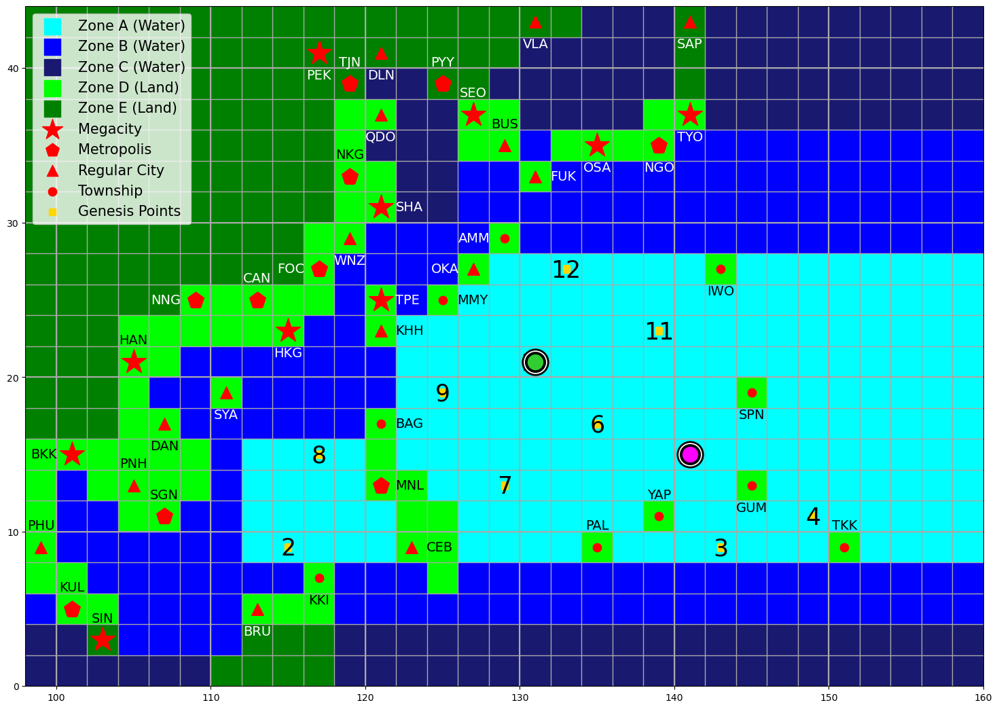

In [54]:
# Plot initial board
Plot_Current_Board(Player_Data)

In [55]:
# Open cards files
Movement_Cards = pandas.read_csv("Cards_Movement.csv")
Intensity_Cards = pandas.read_csv("Cards_Intensity.csv")
Action_Cards = pandas.read_csv("Cards_Action.csv")

# Create card lookup dictionary
Card_Lookup = {}
for Card in Movement_Cards["Card"]:
    Card_Lookup[Card] = ("Movement", Movement_Cards[Movement_Cards["Card"] == Card])
for Card in Intensity_Cards["Card"]:
    Card_Lookup[Card] = ("Intensity", Intensity_Cards[Intensity_Cards["Card"] == Card])
for Card in Action_Cards["Card"]:
    Card_Lookup[Card] = ("Action", Action_Cards[Action_Cards["Card"] == Card])

# Shuffle cards
Movement_Deck = Shuffle_Cards(Movement_Cards)
Intensity_Deck = Shuffle_Cards(Intensity_Cards)
Action_Deck = Shuffle_Cards(Action_Cards)

# Deal cards
Movement_Deck = Deal_Cards(Movement_Deck, Player_Data, 4)
Intensity_Deck = Deal_Cards(Intensity_Deck, Player_Data, 4)
Action_Deck = Deal_Cards(Action_Deck, Player_Data, 2)

In [56]:
# Setup game state
Game_State = Setup_Game_State(n_Players, Ocean_ACE, Movement_Deck, Intensity_Deck, Action_Deck, Cities_DF)

# Save player data and game state history
Player_Data_History = []
Game_State_History = []
Save_State(Player_Data, Game_State, Player_Data_History, Game_State_History)

### Backup Material

In [91]:
Game_State

{'Round': 12,
 'Player Position': 1,
 'Status': 'End Round',
 'Movement Deck': ['E 1',
  'W 2 N 1',
  'N 3',
  'S 2',
  'W 1 S 1',
  'N 5',
  'S ?',
  'N 1',
  'N/S 1',
  'N 3',
  'S 2',
  'N/S 1',
  'E 1 N 1',
  'W 3',
  'N/S 1',
  'S 1',
  'W ?',
  'N 1',
  'E 2 N 2',
  'W 2',
  'W/E/N/S 1',
  'E ?',
  'E 2 N 1',
  'E 2',
  'W 2 S 1',
  'W 1 N 1',
  'W/E 1',
  'E 3',
  'N 4',
  'W 1 N 2',
  'N 4',
  'S 3',
  'W 1 S 2',
  'W 1 N 3',
  'W 2',
  'S 1',
  'W 1',
  'W 2',
  'W 2 N 2',
  'W 1',
  'E 1',
  'W ?',
  'E 1 N 2',
  'E 1 S 1',
  'E 2',
  'N 2',
  'E 2 N 1',
  'N 2',
  'W 4',
  'W 1 N 1',
  'N 1',
  'W 3',
  'W 3 N 1',
  'W/E 1',
  'N 1'],
 'Intensity Deck': ['+5 W/m^2',
  '+5 W/m^2',
  '+15 W/m^2',
  '+5 W/m^2',
  '+5 W/m^2',
  '+10 W/m^2',
  '+25 W/m^2',
  '+ ? W/m^2',
  '+15 W/m^2',
  '+5 W/m^2',
  '+30 W/m^2',
  '+15 W/m^2',
  '+10 W/m^2',
  '+5 W/m^2',
  '+10 W/m^2',
  '+25 W/m^2',
  '+5 W/m^2',
  '+15 W/m^2',
  '+10 W/m^2',
  '+ ? W/m^2',
  '+ ? W/m^2',
  '+ ? W/m^2',
  '+5

In [92]:
Player_Data

{'Kinen': {'Colour': 'limegreen',
  'Order': 1,
  'Round': 12,
  'Status': 'End Round',
  'Genesis Point': 10,
  'Lon': np.int64(109),
  'Lat': np.int64(25),
  'Zone': np.int64(4),
  'Hand': ['N 1',
   'S 1',
   'S 2',
   'W 2',
   '+15 W/m^2',
   '+ ? W/m^2',
   '+25 W/m^2',
   '+15 W/m^2',
   'Rapid Intensification',
   'Breaking Free'],
  'Cards Played This Round': [],
  'Max Cards': 3,
  'Prev Wm2': 0,
  'Remainder Wm2': 0,
  'Prev Lon Change': 0,
  'Prev Lat Change': 0,
  'Intensity': 105,
  'Peak Intensity': 125,
  'ACE': np.int64(550),
  'Landfall Costs': np.int64(2920),
  'Landfall Cities': ['KHH', 'TPE', 'NKG', 'SHA', 'HKG', 'CAN', 'NNG']},
 'Demi': {'Colour': 'magenta',
  'Order': 2,
  'Round': 11,
  'Status': 'End Round',
  'Genesis Point': 5,
  'Lon': np.int64(127),
  'Lat': np.int64(25),
  'Zone': np.int64(1),
  'Hand': ['E 2', 'S 1', '+5 W/m^2', '+10 W/m^2', 'Factory Reset', 'W/E 1'],
  'Cards Played This Round': [],
  'Max Cards': 3,
  'Prev Wm2': 0,
  'Remainder Wm2': 0

In [90]:
Player_Data, Game_State = Undo(Player_Data_History, Game_State_History)

In [ ]:
#Player_Data_History.pop()
#Game_State_History.pop()

## Play Game


--- Round 1: Kinen's turn ---


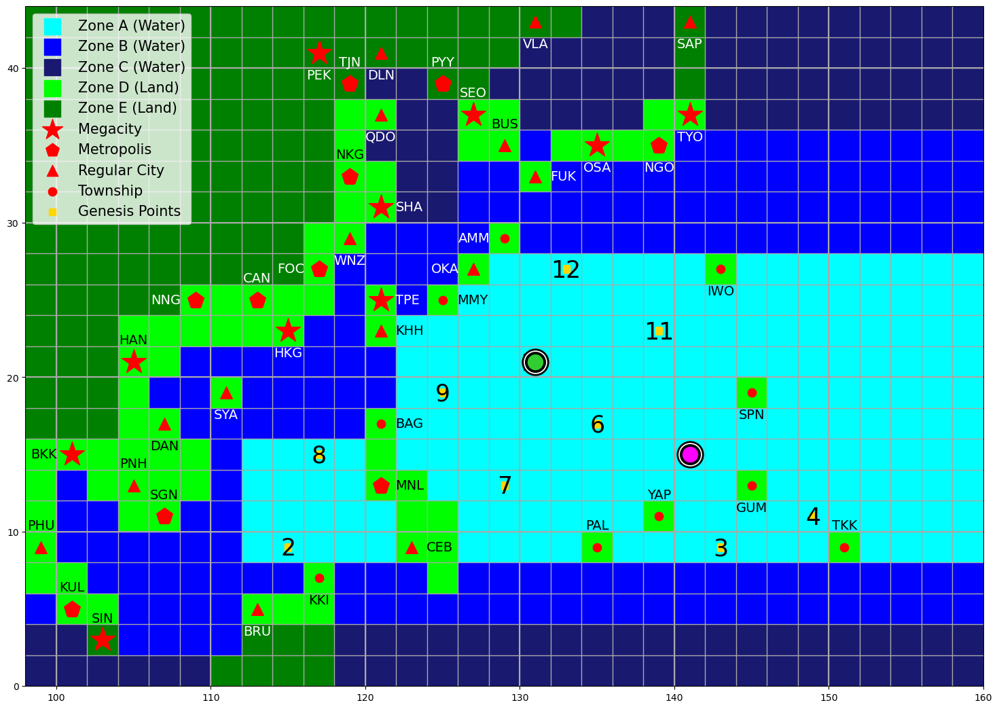

Intensity: 25 knots
Accumulated Cyclone Energy: 0 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
E ?
W 1
W 1 S 1
W 2 S 2
+20 W/m^2
+10 W/m^2
+15 W/m^2
+ ? W/m^2
Breaking Free
City Fortress

--- Round 1: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E ?
1: W 1
2: W 1 S 1
3: W 2 S 2
4: +20 W/m^2
5: +10 W/m^2
6: +15 W/m^2
7: + ? W/m^2
8: Breaking Free
9: City Fortress
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  7


Kinen played: + ? W/m^2

Kinen rolled 1: + 5 W/m^2
Kinen has intensified to 30 knots!

--- Round 1: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E ?
1: W 1
2: W 1 S 1
3: W 2 S 2
4: +20 W/m^2
5: +10 W/m^2
6: +15 W/m^2
7: Breaking Free
8: City Fortress
Enter 'p' to pass.


Choose a card by index to play:  4


Kinen played: +20 W/m^2

Kinen has intensified to 50 knots!

--- Round 1: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E ?
1: W 1
2: W 1 S 1
3: W 2 S 2
4: +10 W/m^2
5: +15 W/m^2
6: Breaking Free
7: City Fortress
Enter 'p' to pass.


Choose a card by index to play:  5


Kinen played: +15 W/m^2

Kinen has intensified to 65 knots!

--- End of Kinen's turn ---
Kinen's current intensity: 65 knots. Kinen has gained 20 kJ.
Kinen's Accumulated Cyclone Energy: 20 kJ.
Kinen's total landfall costs: $0M.
The ocean has 1480 kJ of energy remaining.


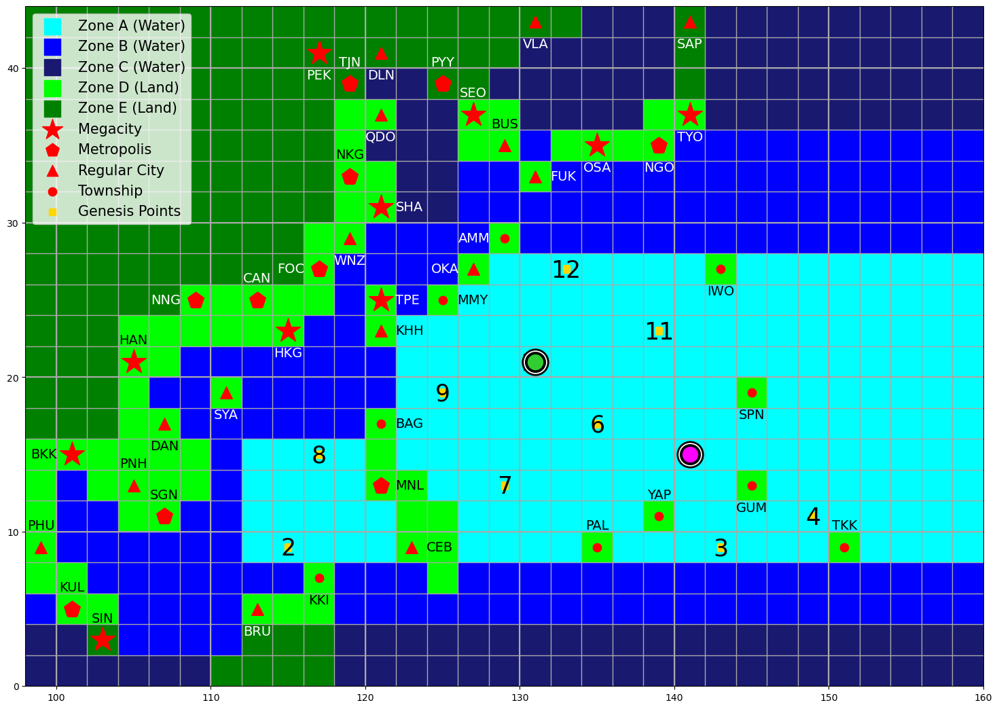

In [57]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 1: Demi's turn ---


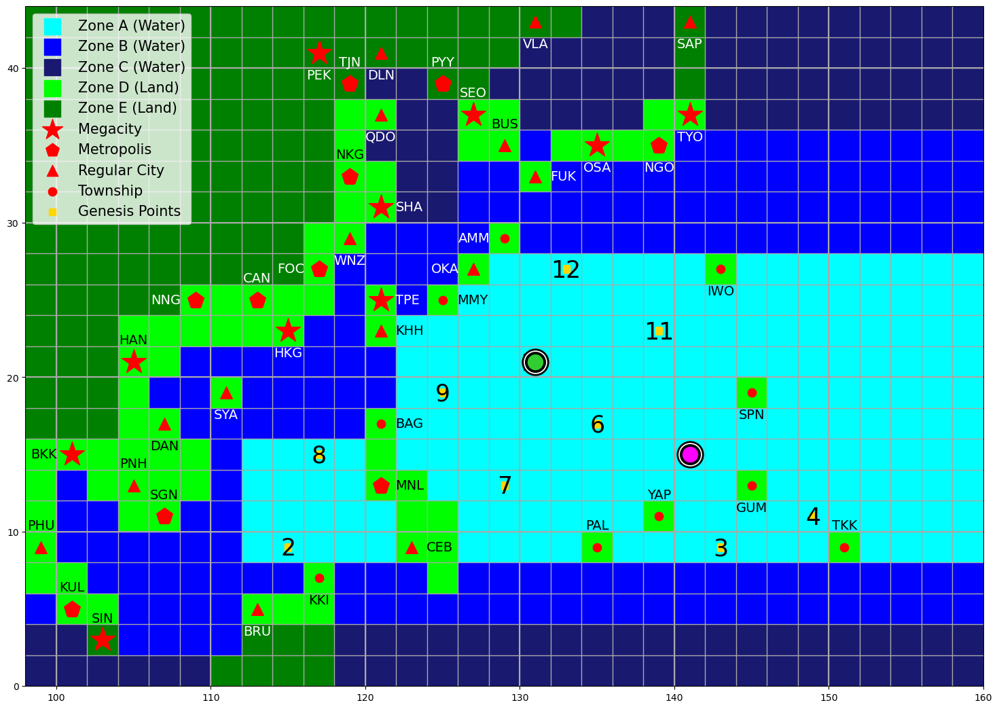

Intensity: 25 knots
Accumulated Cyclone Energy: 0 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
W 1
W 3
W 1 N 1
W 1
+25 W/m^2
+ ? W/m^2
+ ? W/m^2
+25 W/m^2
Rapid Intensification
Cyclone Express

--- Round 1: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: W 1
1: W 3
2: W 1 N 1
3: W 1
4: +25 W/m^2
5: + ? W/m^2
6: + ? W/m^2
7: +25 W/m^2
8: Rapid Intensification (cannot play)
9: Cyclone Express (cannot play)
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  5


Demi played: + ? W/m^2

Demi rolled 3: + 15 W/m^2
Demi has intensified to 40 knots!

--- Round 1: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: W 1
1: W 3
2: W 1 N 1
3: W 1
4: +25 W/m^2
5: + ? W/m^2
6: +25 W/m^2
7: Rapid Intensification
8: Cyclone Express (cannot play)
Enter 'p' to pass.


Choose a card by index to play:  4


Demi played: +25 W/m^2

Demi has intensified to 65 knots!

--- Round 1: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: W 1
1: W 3
2: W 1 N 1
3: W 1
4: + ? W/m^2
5: +25 W/m^2
6: Rapid Intensification
7: Cyclone Express (cannot play)
Enter 'p' to pass.


Choose a card by index to play:  6


Demi played: Rapid Intensification

Demi has intensified to 90 knots!

--- End of Demi's turn ---
Demi's current intensity: 90 knots. Demi has gained 30 kJ.
Demi's Accumulated Cyclone Energy: 30 kJ.
Demi's total landfall costs: $0M.
The ocean has 1450 kJ of energy remaining.


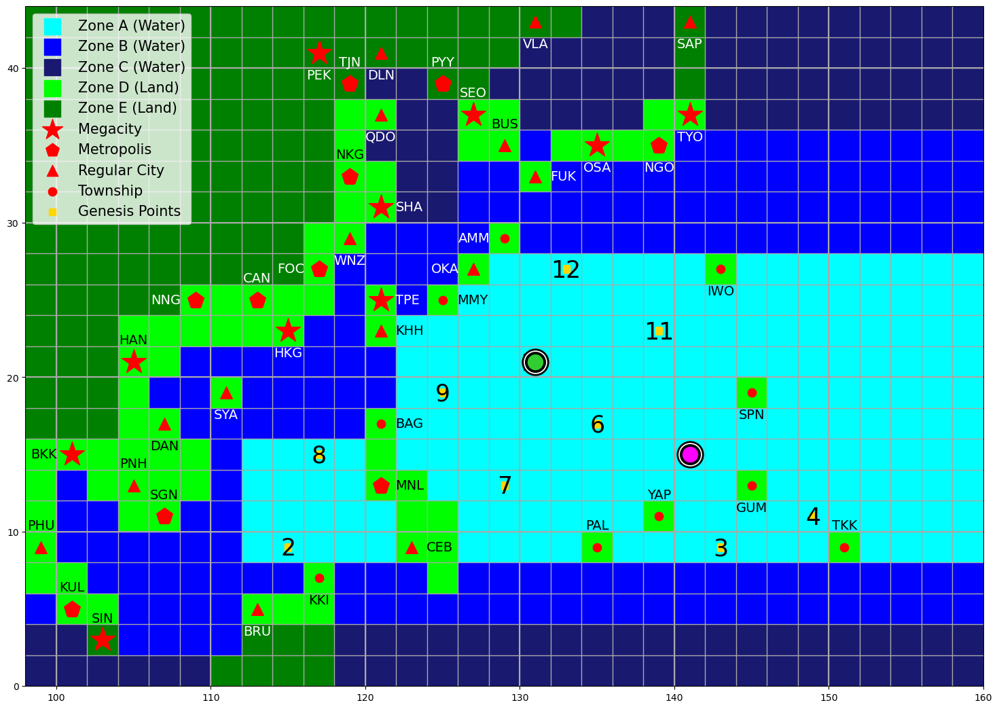

In [60]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 2: Kinen's turn ---


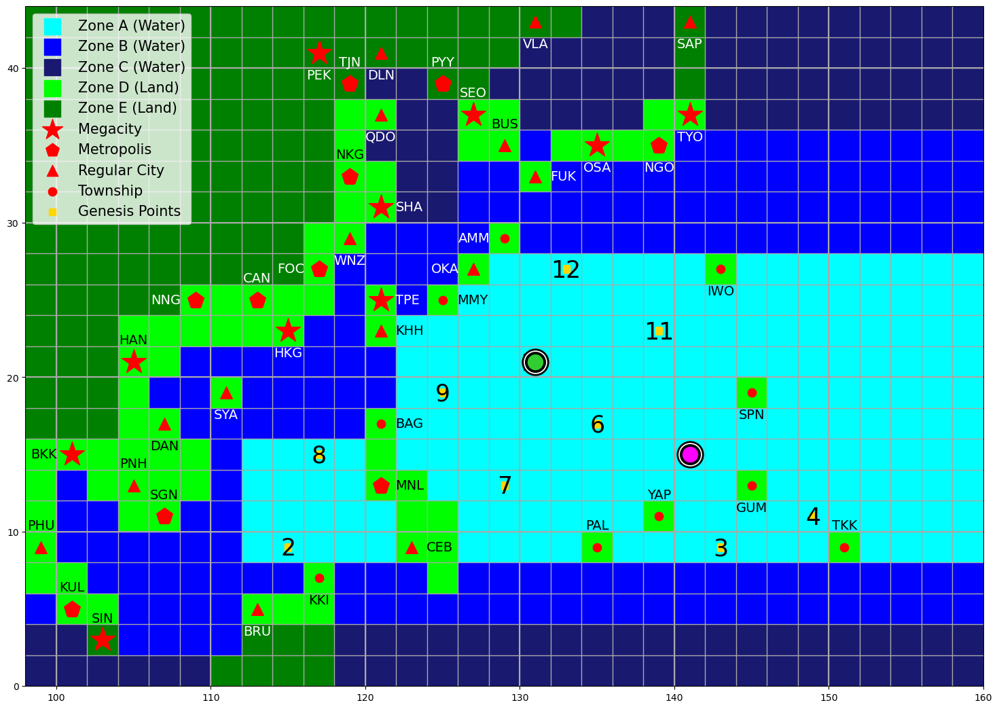

Intensity: 65 knots
Accumulated Cyclone Energy: 20 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
E ?
W 1
W 1 S 1
W 2 S 2
+10 W/m^2
Breaking Free
City Fortress

--- Round 2: Kinen's draw phase ---
0: Movement Deck (92 cards left)
1: Intensity Deck (92 cards left)
2: Action Deck (46 cards left)


Choose a deck by index: 1


Kinen drew: +5 W/m^2 from Intensity Deck.

0: Movement Deck (92 cards left)
1: Intensity Deck (91 cards left)
2: Action Deck (46 cards left)


Choose a deck by index: 1


Kinen drew: +10 W/m^2 from Intensity Deck.


--- Round 2: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E ?
1: W 1
2: W 1 S 1
3: W 2 S 2
4: +10 W/m^2
5: Breaking Free
6: City Fortress
7: +5 W/m^2
8: +10 W/m^2
Enter 'd' to discard a card and get a replacement from the same deck.


...

Kinen played: +10 W/m^2

Kinen has intensified to 75 knots!

--- Round 2: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E ?
1: W 1
2: W 1 S 1
3: W 2 S 2
4: Breaking Free
5: City Fortress
6: +5 W/m^2
7: +10 W/m^2
Enter 'p' to pass.


Choose a card by index to play:  7


Kinen played: +10 W/m^2

Kinen has intensified to 85 knots!

--- Round 2: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E ?
1: W 1
2: W 1 S 1
3: W 2 S 2
4: Breaking Free
5: City Fortress
6: +5 W/m^2
Enter 'p' to pass.


Choose a card by index to play:  6


Kinen played: +5 W/m^2

Kinen has intensified to 90 knots!

--- End of Kinen's turn ---
Kinen's current intensity: 90 knots. Kinen has gained 30 kJ.
Kinen's Accumulated Cyclone Energy: 50 kJ.
Kinen's total landfall costs: $0M.
The ocean has 1420 kJ of energy remaining.


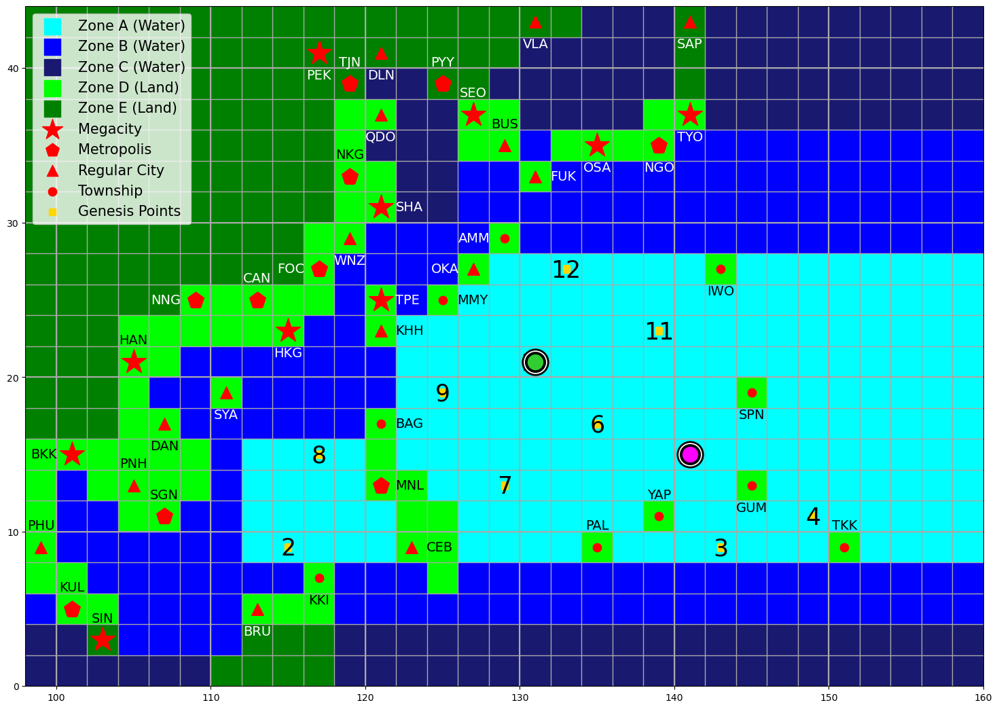

In [61]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 2: Demi's turn ---


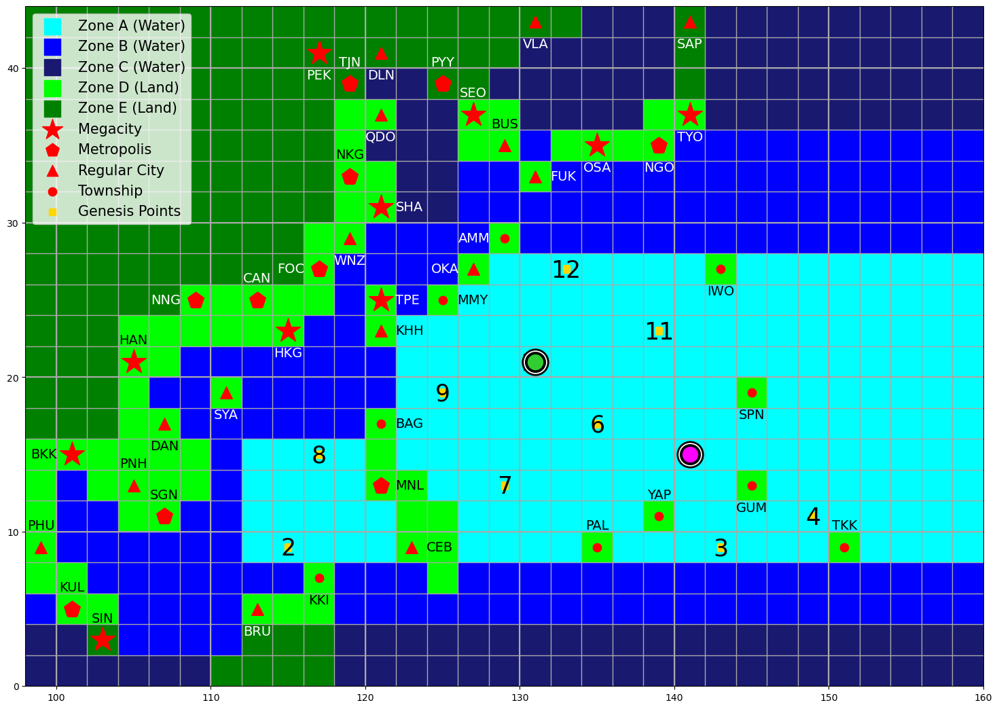

Intensity: 90 knots
Accumulated Cyclone Energy: 30 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
W 1
W 3
W 1 N 1
W 1
+ ? W/m^2
+25 W/m^2
Cyclone Express

--- Round 2: Demi's draw phase ---
0: Movement Deck (92 cards left)
1: Intensity Deck (90 cards left)
2: Action Deck (46 cards left)


Choose a deck by index: 1


Demi drew: +20 W/m^2 from Intensity Deck.

0: Movement Deck (92 cards left)
1: Intensity Deck (89 cards left)
2: Action Deck (46 cards left)


Choose a deck by index: 2


Demi drew: Eyewall Replacement from Action Deck.


--- Round 2: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: W 1
1: W 3
2: W 1 N 1
3: W 1
4: + ? W/m^2
5: +25 W/m^2
6: Cyclone Express (cannot play)
7: +20 W/m^2
8: Eyewall Replacement
Enter 'd' to discard a card and get a replacement from the same deck.


...

Demi played: +25 W/m^2

Demi has intensified to 115 knots!

--- Round 2: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: W 1
1: W 3
2: W 1 N 1
3: W 1
4: Cyclone Express (cannot play)
5: +20 W/m^2
6: Eyewall Replacement
Enter 'p' to pass.


Choose a card by index to play:  6


Demi played: Eyewall Replacement

0: Kinen


Select an opponent: 0


Kinen will not be able to intensify for the next 2 rounds.

--- End of Demi's turn ---
Demi's current intensity: 115 knots. Demi has gained 50 kJ.
Demi's Accumulated Cyclone Energy: 80 kJ.
Demi's total landfall costs: $0M.
The ocean has 1370 kJ of energy remaining.


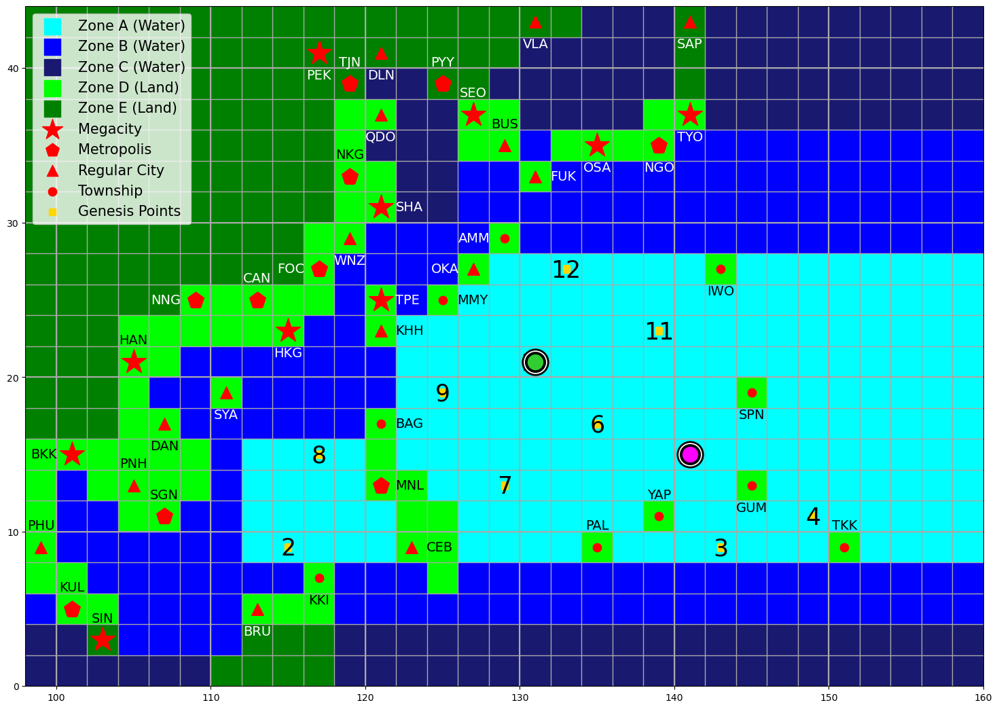

In [62]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 3: Kinen's turn ---


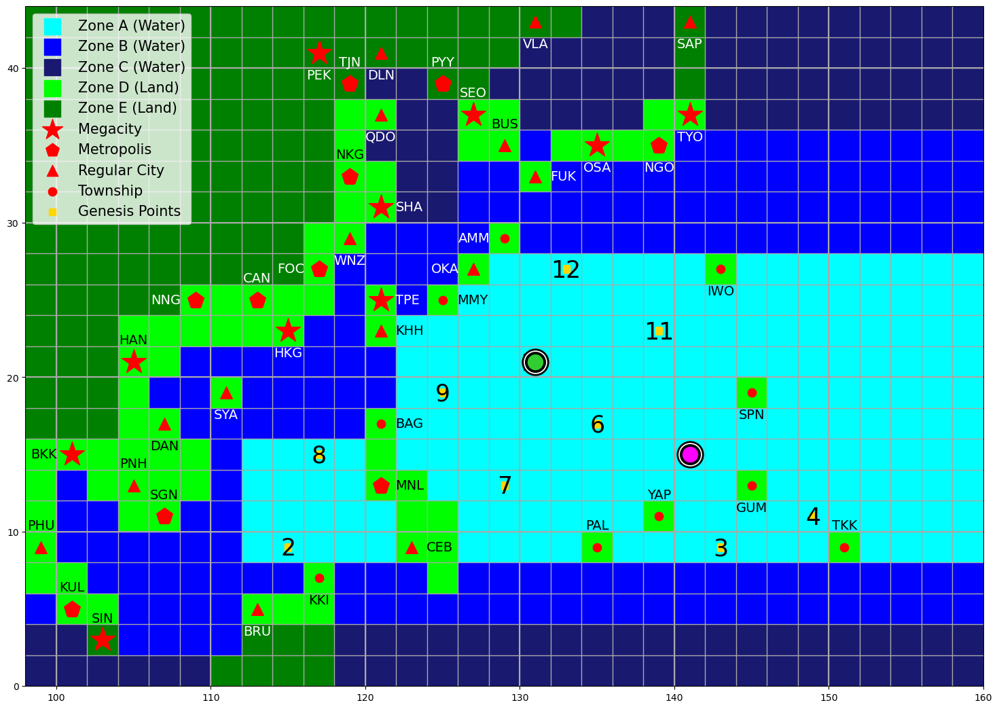

Intensity: 90 knots
Accumulated Cyclone Energy: 50 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
E ?
W 1
W 1 S 1
W 2 S 2
Breaking Free
City Fortress

--- Round 3: Kinen's draw phase ---
0: Movement Deck (92 cards left)
1: Intensity Deck (89 cards left)
2: Action Deck (45 cards left)


Choose a deck by index: 2


Kinen drew: Rapid Intensification from Action Deck.

0: Movement Deck (92 cards left)
1: Intensity Deck (89 cards left)


Choose a deck by index: 0


Kinen drew: W 1 N 2 from Movement Deck.


--- Round 3: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E ?
1: W 1
2: W 1 S 1
3: W 2 S 2
4: Breaking Free
5: City Fortress
6: Rapid Intensification (cannot play)
7: W 1 N 2
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  7


Kinen played: W 1 N 2



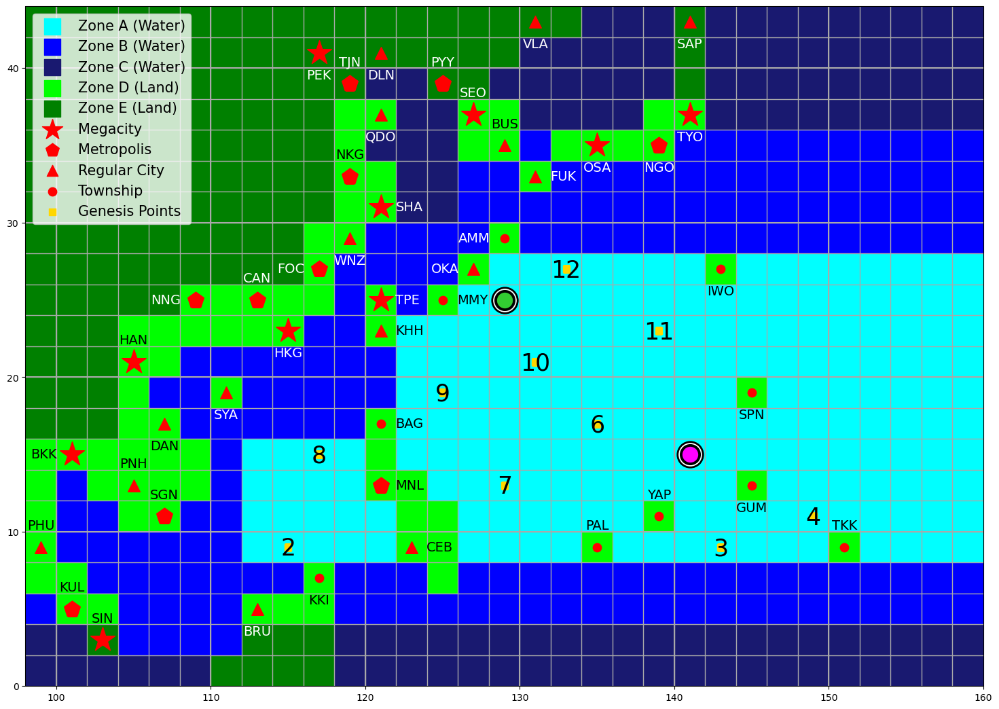


--- Round 3: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E ?
1: W 1
2: W 1 S 1
3: W 2 S 2
4: Breaking Free
5: City Fortress
6: Rapid Intensification (cannot play)
Enter 'p' to pass.


Choose a card by index to play:  1


Kinen played: W 1



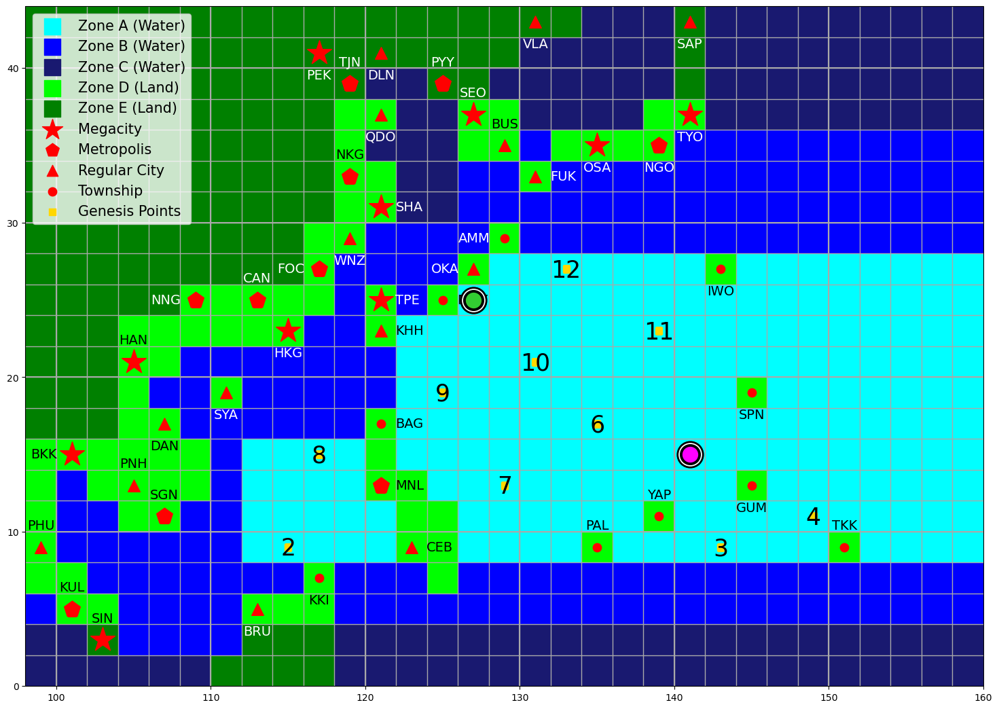


--- Round 3: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E ?
1: W 1 S 1
2: W 2 S 2
3: Breaking Free
4: City Fortress
5: Rapid Intensification (cannot play)
Enter 'p' to pass.


Choose a card by index to play:  3


Kinen played: Breaking Free

All negative effects removed from Kinen.

--- End of Kinen's turn ---
Kinen's current intensity: 90 knots. Kinen has gained 30 kJ.
Kinen's Accumulated Cyclone Energy: 80 kJ.
Kinen's total landfall costs: $0M.
The ocean has 1340 kJ of energy remaining.


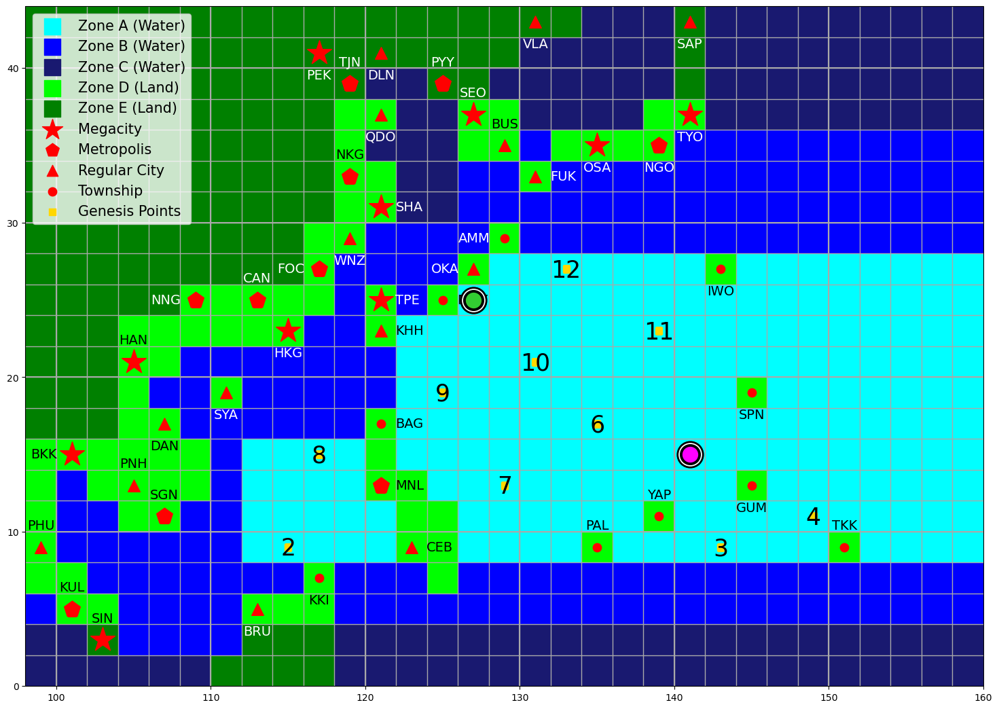

In [63]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 3: Demi's turn ---


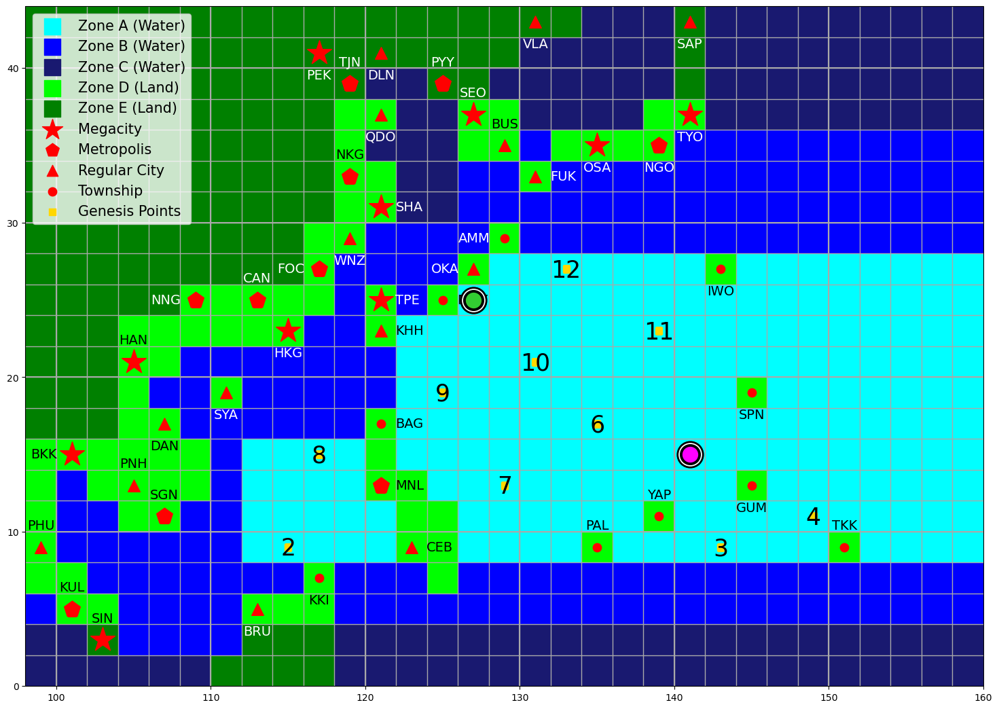

Intensity: 115 knots
Accumulated Cyclone Energy: 80 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
W 1
W 3
W 1 N 1
W 1
Cyclone Express
+20 W/m^2

--- Round 3: Demi's draw phase ---
0: Movement Deck (91 cards left)
1: Intensity Deck (89 cards left)
2: Action Deck (44 cards left)


Choose a deck by index: 2


Demi drew: Survival of the Fittest from Action Deck.

0: Movement Deck (91 cards left)
1: Intensity Deck (89 cards left)


Choose a deck by index: 1


Demi drew: +5 W/m^2 from Intensity Deck.


--- Round 3: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: W 1
1: W 3
2: W 1 N 1
3: W 1
4: Cyclone Express (cannot play)
5: +20 W/m^2
6: Survival of the Fittest
7: +5 W/m^2
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  5


Demi played: +20 W/m^2

Demi has intensified to 125 knots!

--- Round 3: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: W 1
1: W 3
2: W 1 N 1
3: W 1
4: Cyclone Express (cannot play)
5: Survival of the Fittest
6: +5 W/m^2
Enter 'p' to pass.


Choose a card by index to play:  1


Demi played: W 3



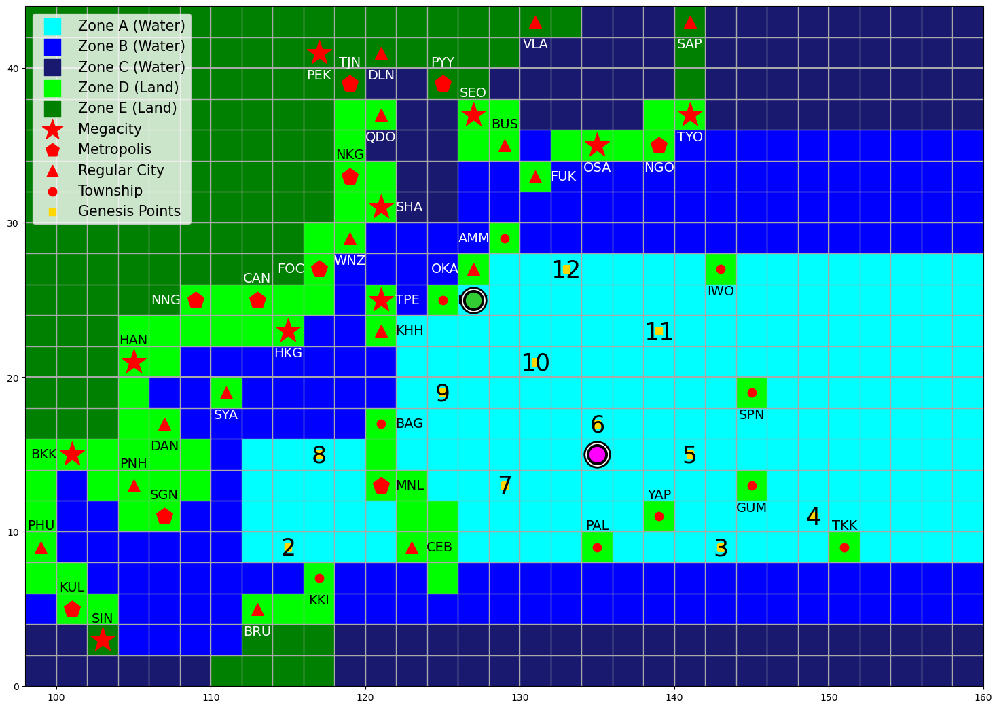


--- Round 3: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: W 1
1: W 1 N 1
2: W 1
3: Cyclone Express
4: Survival of the Fittest
5: +5 W/m^2
Enter 'p' to pass.


Choose a card by index to play:  3


Demi played: Cyclone Express



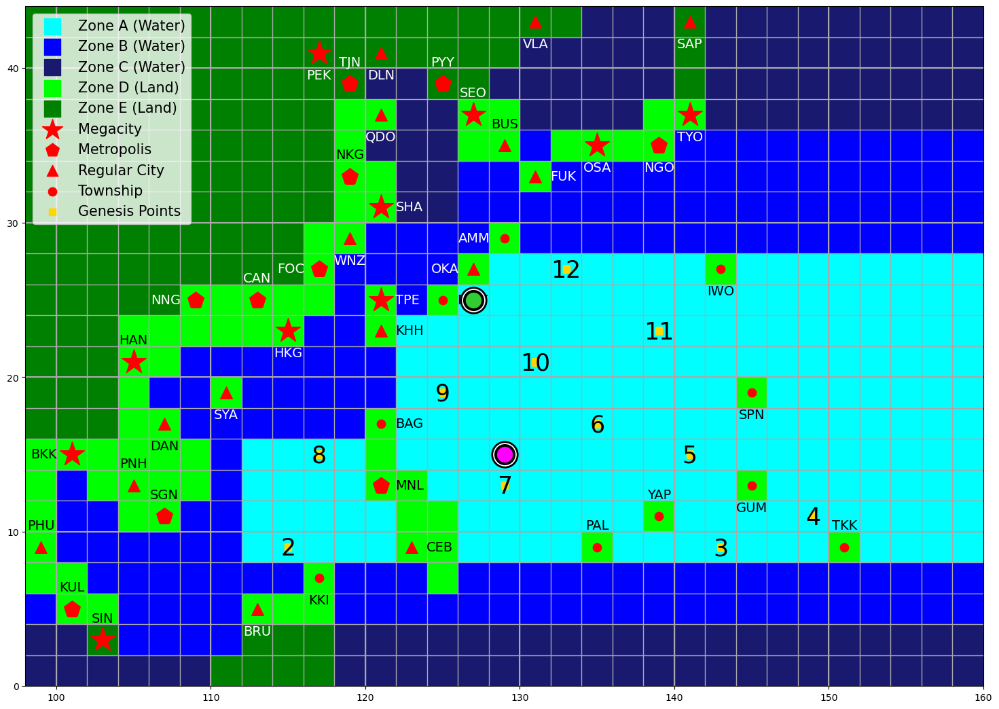


--- End of Demi's turn ---
Demi's current intensity: 125 knots. Demi has gained 70 kJ.
Demi's Accumulated Cyclone Energy: 150 kJ.
Demi's total landfall costs: $0M.
The ocean has 1270 kJ of energy remaining.


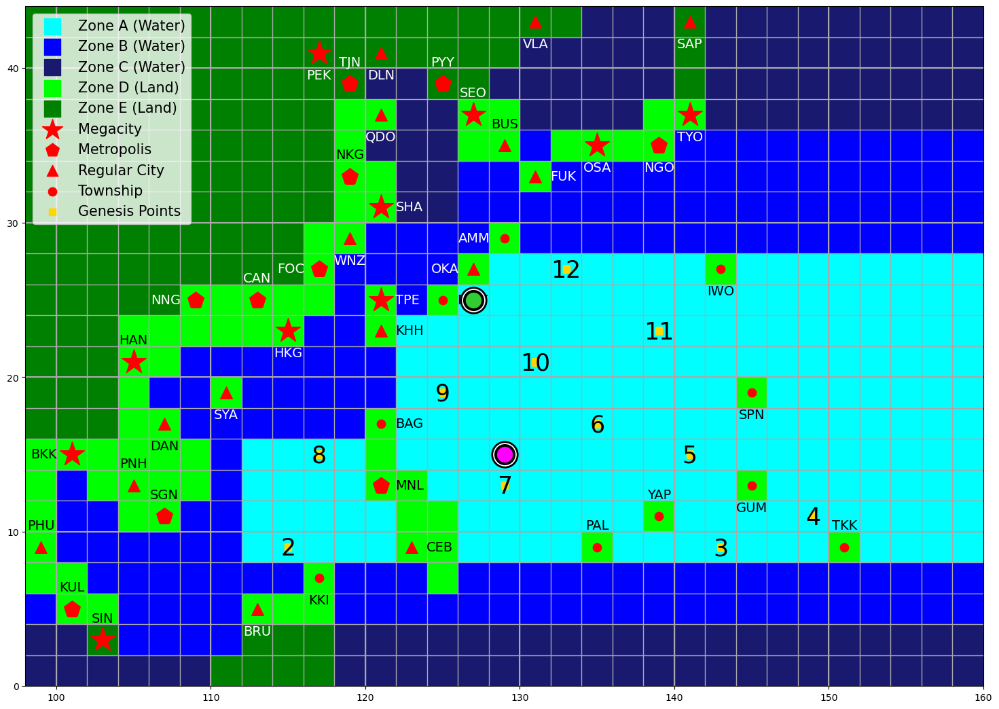

In [64]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 4: Kinen's turn ---


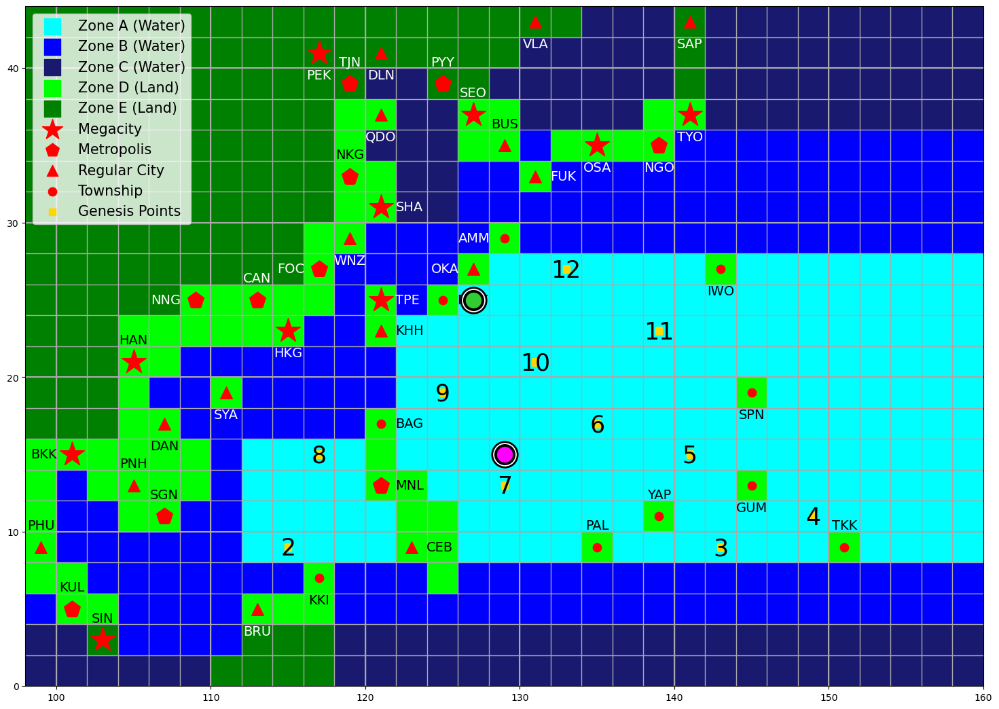

Intensity: 90 knots
Accumulated Cyclone Energy: 80 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
E ?
W 1 S 1
W 2 S 2
City Fortress
Rapid Intensification

--- Round 4: Kinen's draw phase ---
0: Movement Deck (91 cards left)
1: Intensity Deck (88 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 1


Kinen drew: +20 W/m^2 from Intensity Deck.

0: Movement Deck (91 cards left)
1: Intensity Deck (87 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 0


Kinen drew: N ? from Movement Deck.


--- Round 4: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E ?
1: W 1 S 1
2: W 2 S 2
3: City Fortress
4: Rapid Intensification (cannot play)
5: +20 W/m^2
6: N ?
Enter 'd' to discard a card and get a replacement from the same deck.


...

Kinen played: +20 W/m^2

Kinen has intensified to 105 knots!

--- Round 4: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E ?
1: W 1 S 1
2: W 2 S 2
3: City Fortress
4: Rapid Intensification
5: N ?
Enter 'p' to pass.


Choose a card by index to play:  4


Kinen played: Rapid Intensification

Kinen has intensified to 115 knots!

--- Round 4: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E ?
1: W 1 S 1
2: W 2 S 2
3: City Fortress
4: N ?
Enter 'p' to pass.


Choose a card by index to play:  2


Kinen played: W 2 S 2



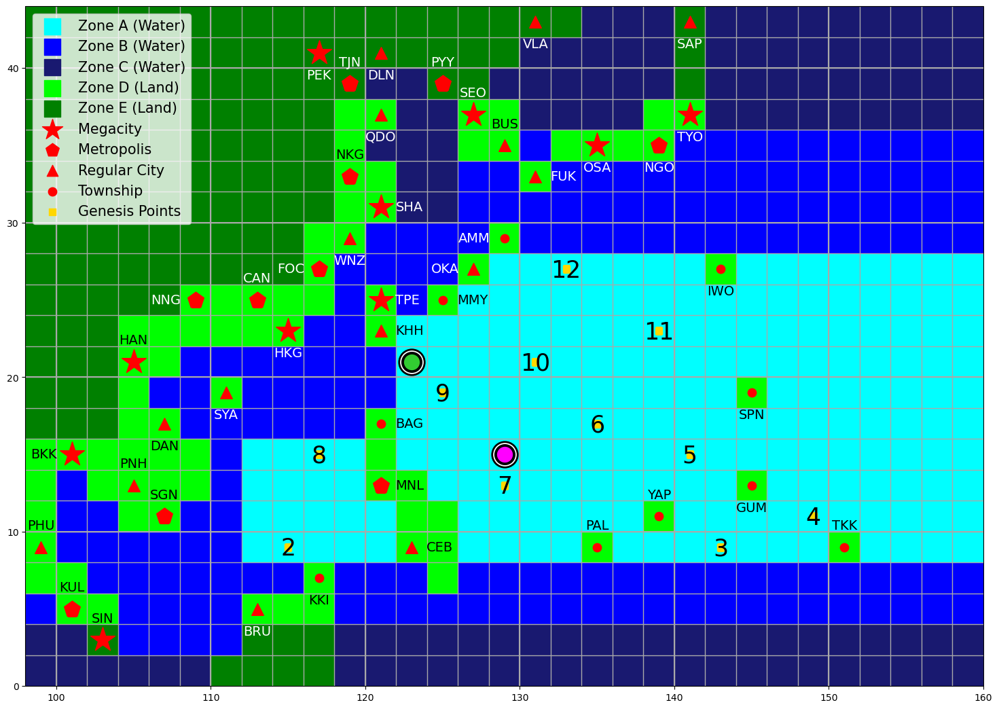


--- End of Kinen's turn ---
Kinen's current intensity: 115 knots. Kinen has gained 50 kJ.
Kinen's Accumulated Cyclone Energy: 130 kJ.
Kinen's total landfall costs: $0M.
The ocean has 1220 kJ of energy remaining.


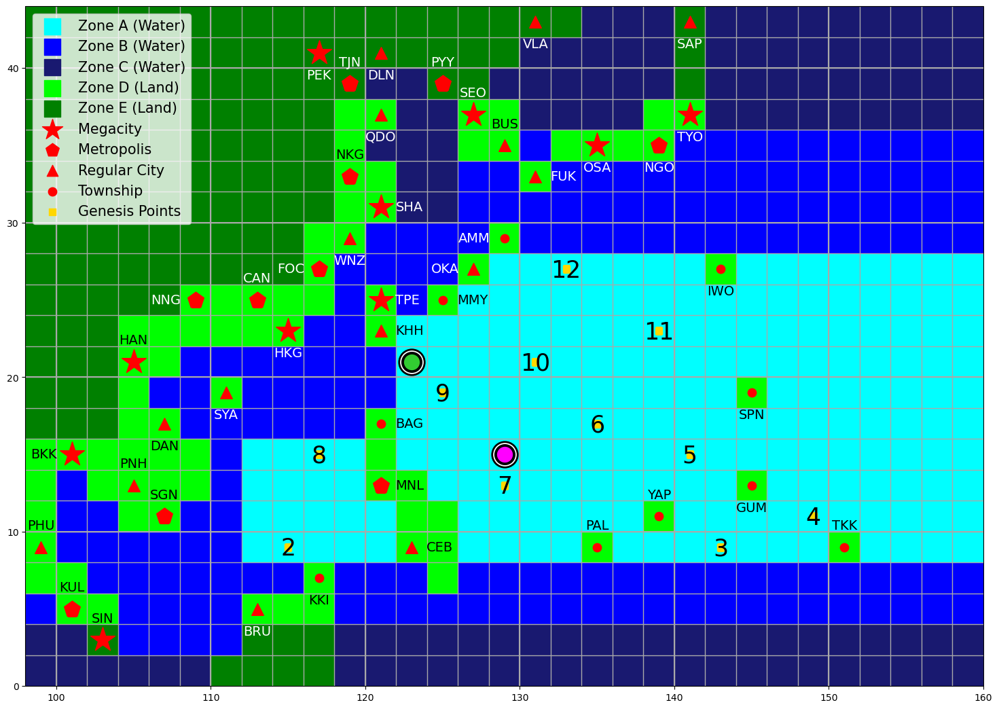

In [65]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 4: Demi's turn ---


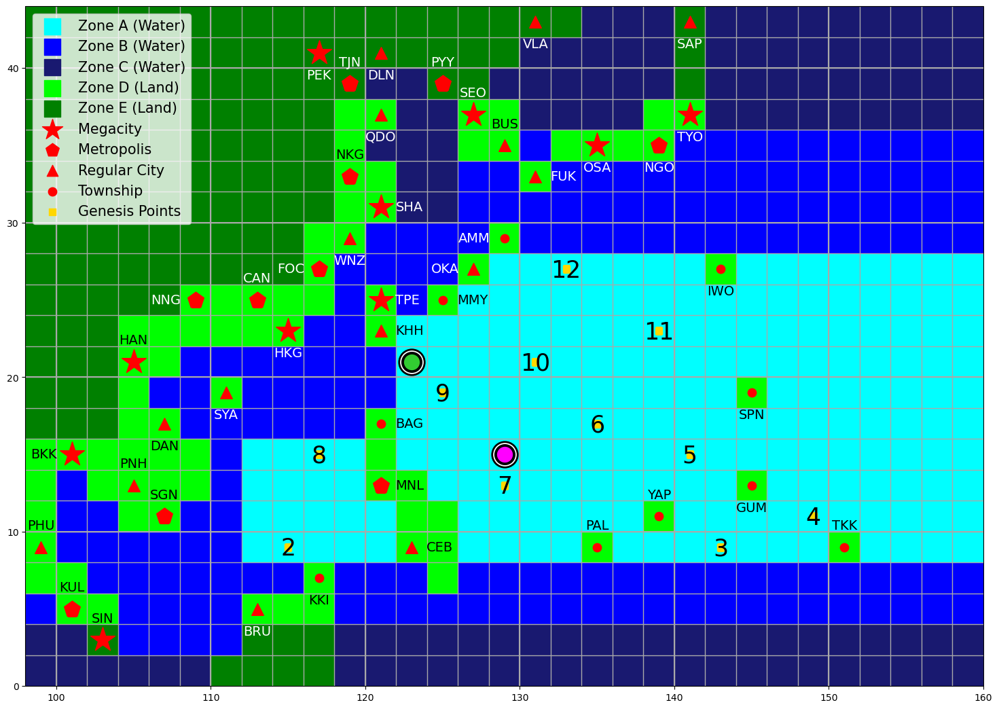

Intensity: 125 knots
Accumulated Cyclone Energy: 150 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
W 1
W 1 N 1
W 1
Survival of the Fittest
+5 W/m^2

--- Round 4: Demi's draw phase ---
0: Movement Deck (90 cards left)
1: Intensity Deck (87 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 0


Demi drew: S ? from Movement Deck.

0: Movement Deck (89 cards left)
1: Intensity Deck (87 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 1


Demi drew: +5 W/m^2 from Intensity Deck.


--- Round 4: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: W 1
1: W 1 N 1
2: W 1
3: Survival of the Fittest
4: +5 W/m^2
5: S ?
6: +5 W/m^2
Enter 'd' to discard a card and get a replacement from the same deck.


...

Demi played: +5 W/m^2

Demi remains at 125 knots.

--- Round 4: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: W 1
1: W 1 N 1
2: W 1
3: Survival of the Fittest
4: S ?
5: +5 W/m^2
Enter 'p' to pass.


Choose a card by index to play:  5


Demi played: +5 W/m^2

Demi has intensified to 130 knots!

--- Round 4: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: W 1
1: W 1 N 1
2: W 1
3: Survival of the Fittest
4: S ?
Enter 'p' to pass.


Choose a card by index to play:  0


Demi played: W 1



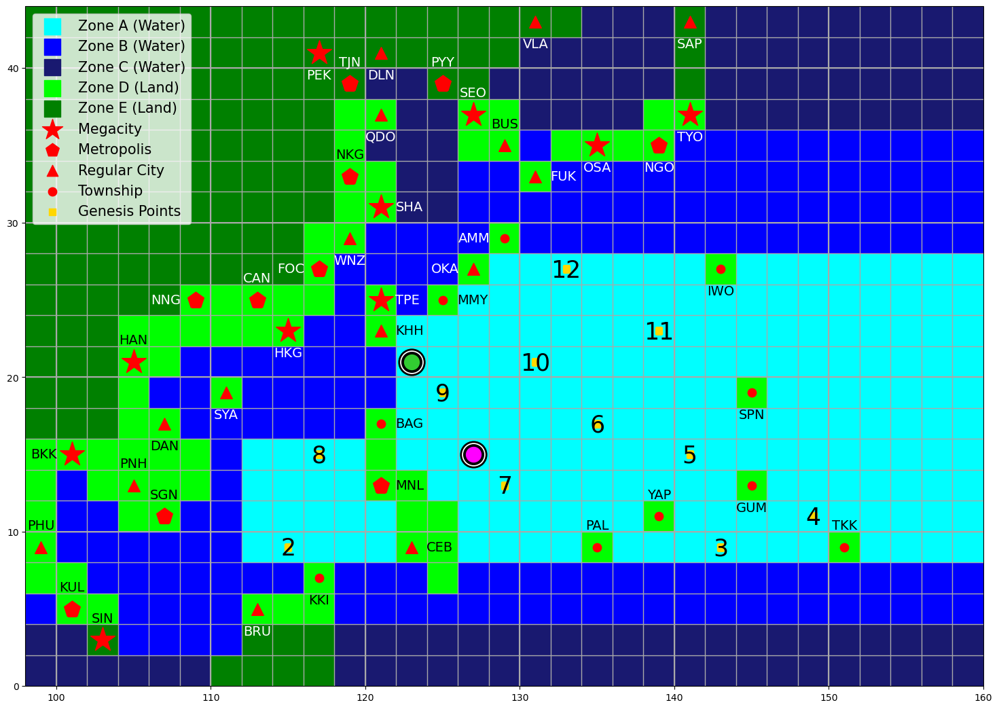


--- End of Demi's turn ---
Demi's current intensity: 130 knots. Demi has gained 70 kJ.
Demi's Accumulated Cyclone Energy: 220 kJ.
Demi's total landfall costs: $0M.
The ocean has 1150 kJ of energy remaining.


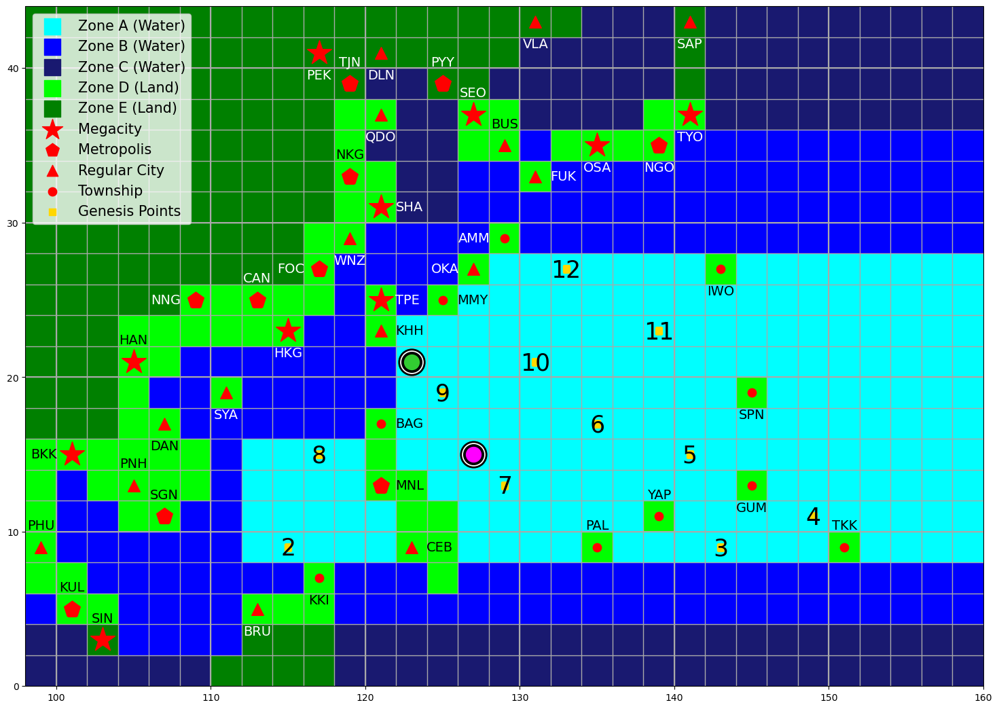

In [66]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 5: Kinen's turn ---


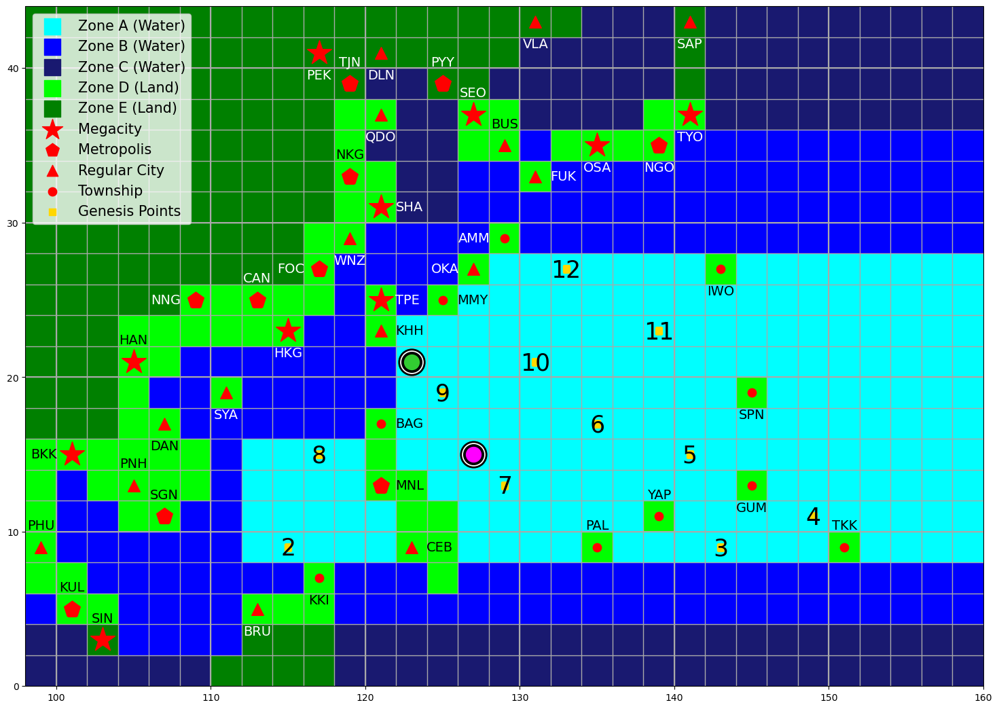

Intensity: 115 knots
Accumulated Cyclone Energy: 130 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
E ?
W 1 S 1
City Fortress
N ?

--- Round 5: Kinen's draw phase ---
0: Movement Deck (89 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 0


Kinen drew: W ? from Movement Deck.

0: Movement Deck (88 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 0


Kinen drew: E 1 N 1 from Movement Deck.


--- Round 5: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E ?
1: W 1 S 1
2: City Fortress
3: N ?
4: W ?
5: E 1 N 1
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  1


Kinen played: W 1 S 1



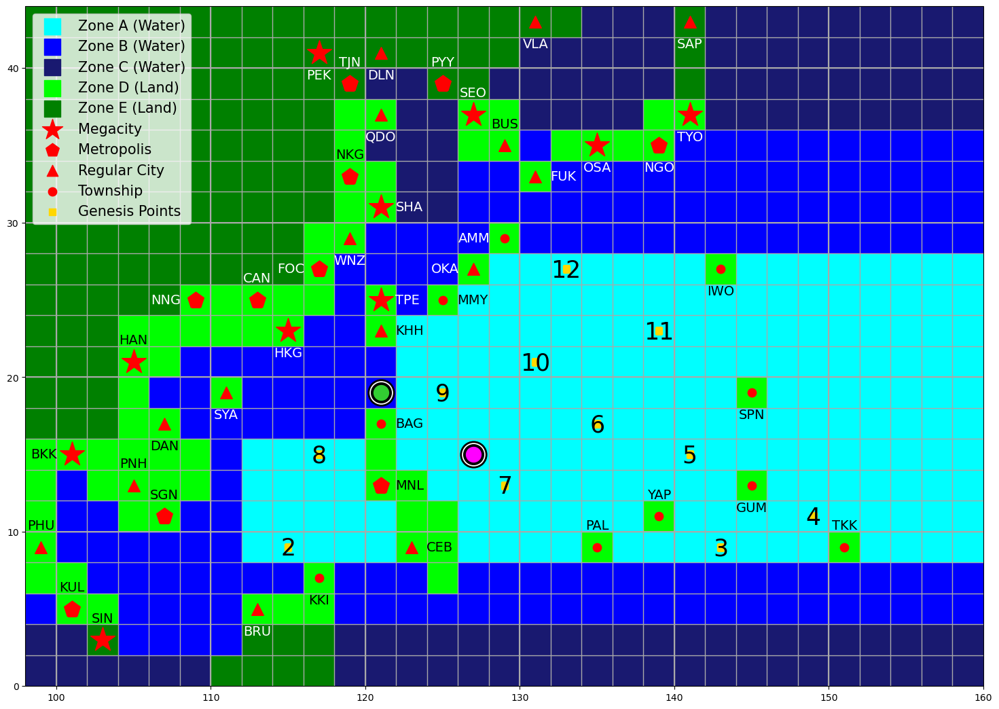


--- Round 5: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E ?
1: City Fortress
2: N ?
3: W ?
4: E 1 N 1
Enter 'p' to pass.


Choose a card by index to play:  2


Kinen played: N ?

Kinen rolled 1: N 1


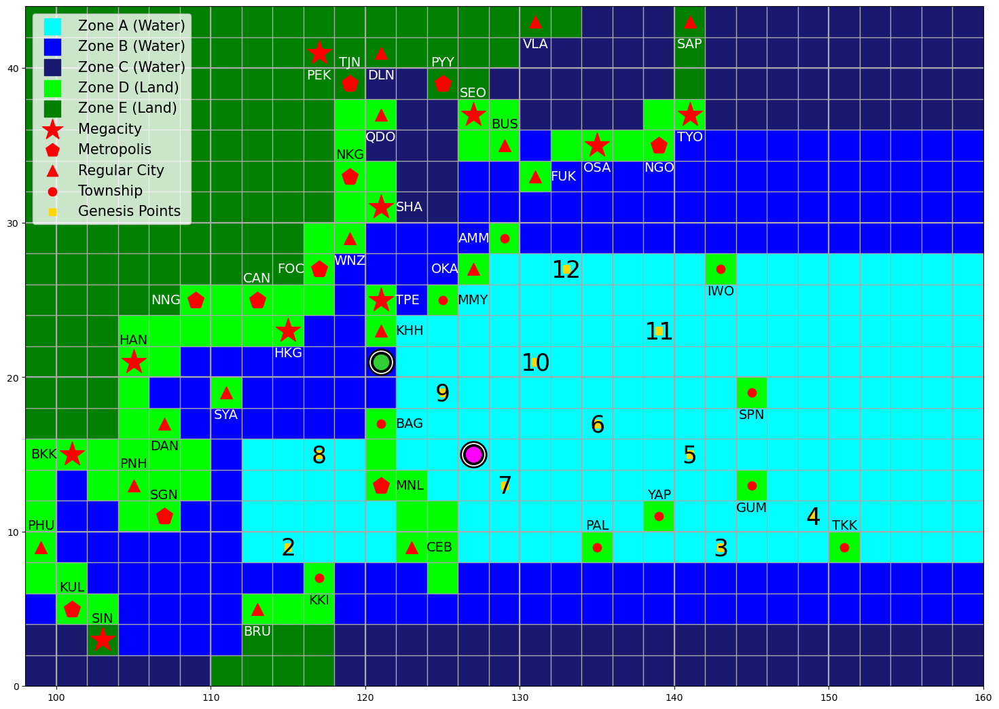


--- Round 5: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E ?
1: City Fortress
2: W ?
3: E 1 N 1
Enter 'p' to pass.


Choose a card by index to play:  3


Kinen played: E 1 N 1



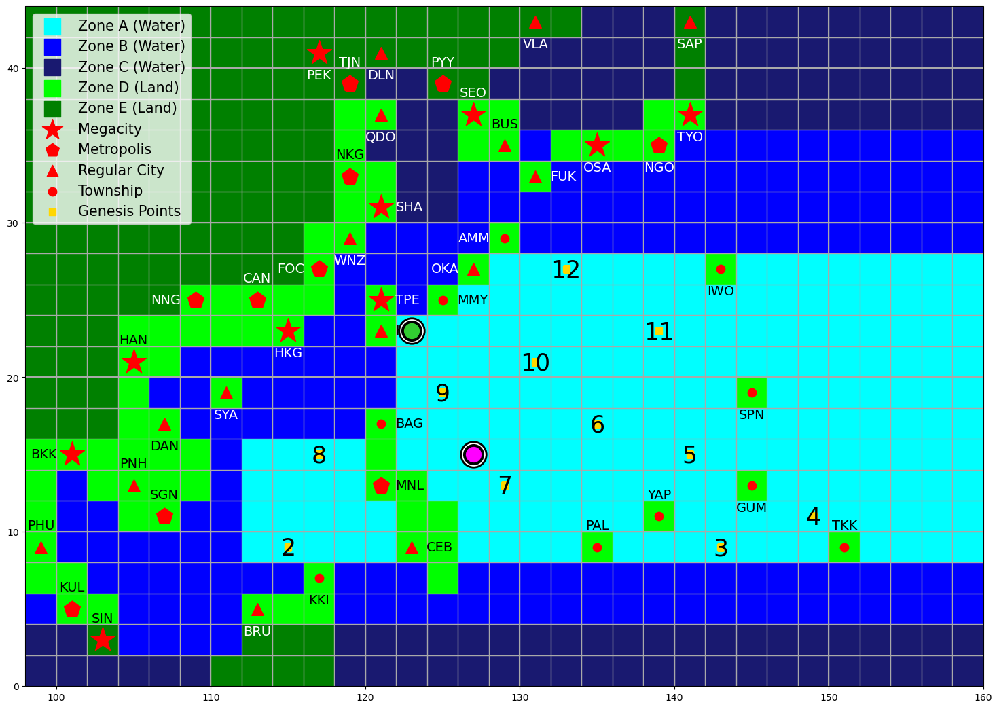


--- End of Kinen's turn ---
Kinen's current intensity: 115 knots. Kinen has gained 50 kJ.
Kinen's Accumulated Cyclone Energy: 180 kJ.
Kinen's total landfall costs: $0M.
The ocean has 1100 kJ of energy remaining.


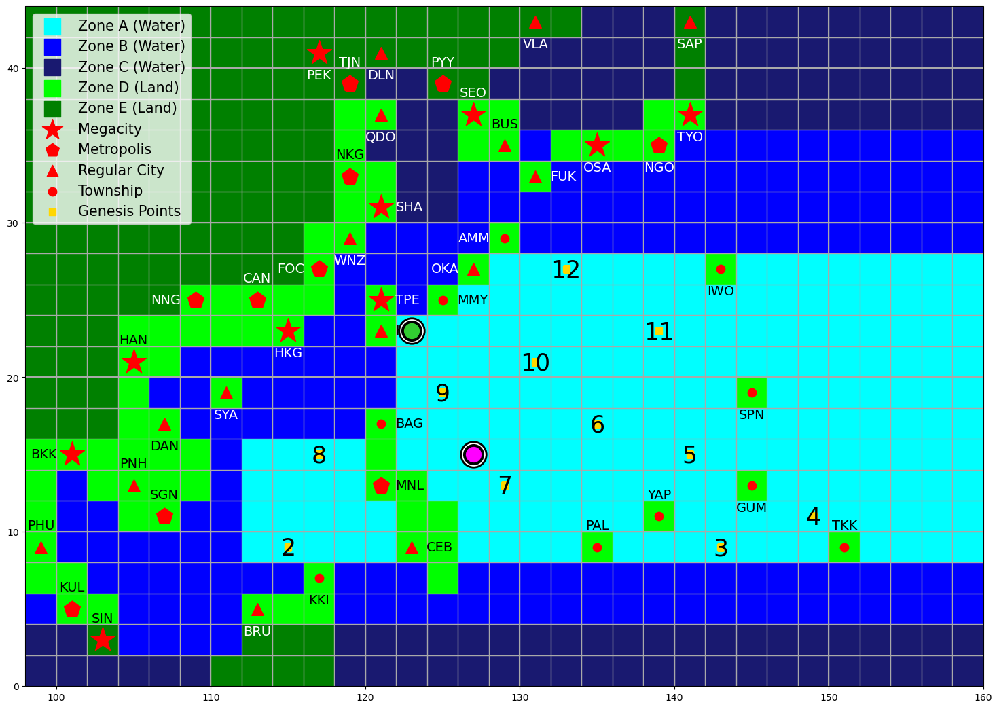

In [67]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 5: Demi's turn ---


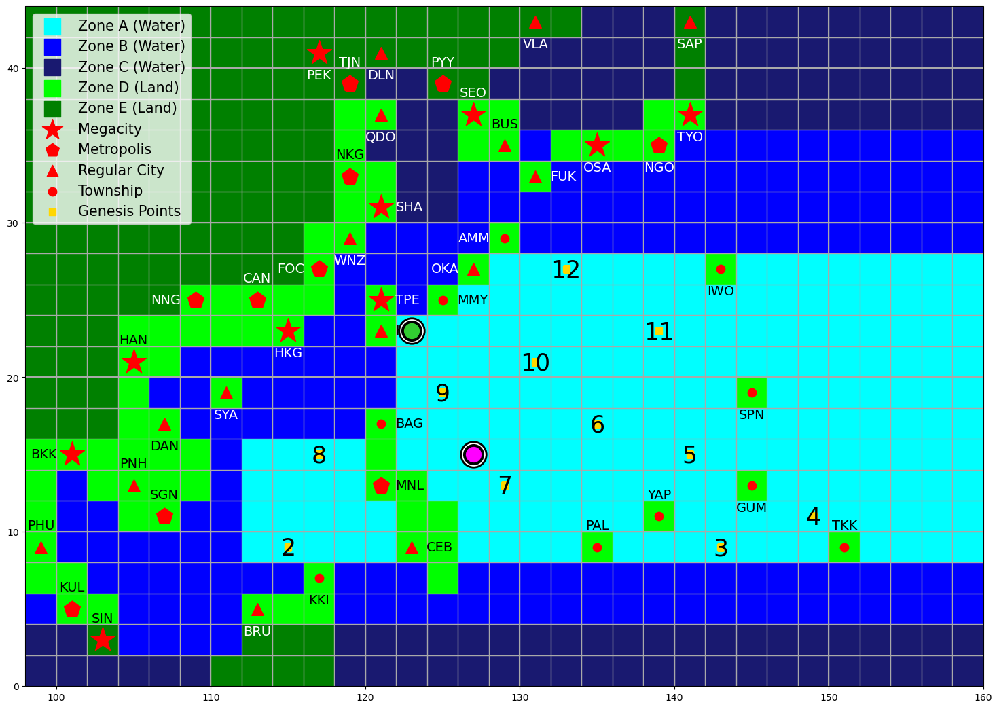

Intensity: 130 knots
Accumulated Cyclone Energy: 220 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
W 1 N 1
W 1
Survival of the Fittest
S ?

--- Round 5: Demi's draw phase ---
0: Movement Deck (87 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 0


Demi drew: W 1 N 1 from Movement Deck.

0: Movement Deck (86 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 0


Demi drew: W 2 N 2 from Movement Deck.


--- Round 5: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: W 1 N 1
1: W 1
2: Survival of the Fittest
3: S ?
4: W 1 N 1
5: W 2 N 2
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  5


Demi played: W 2 N 2



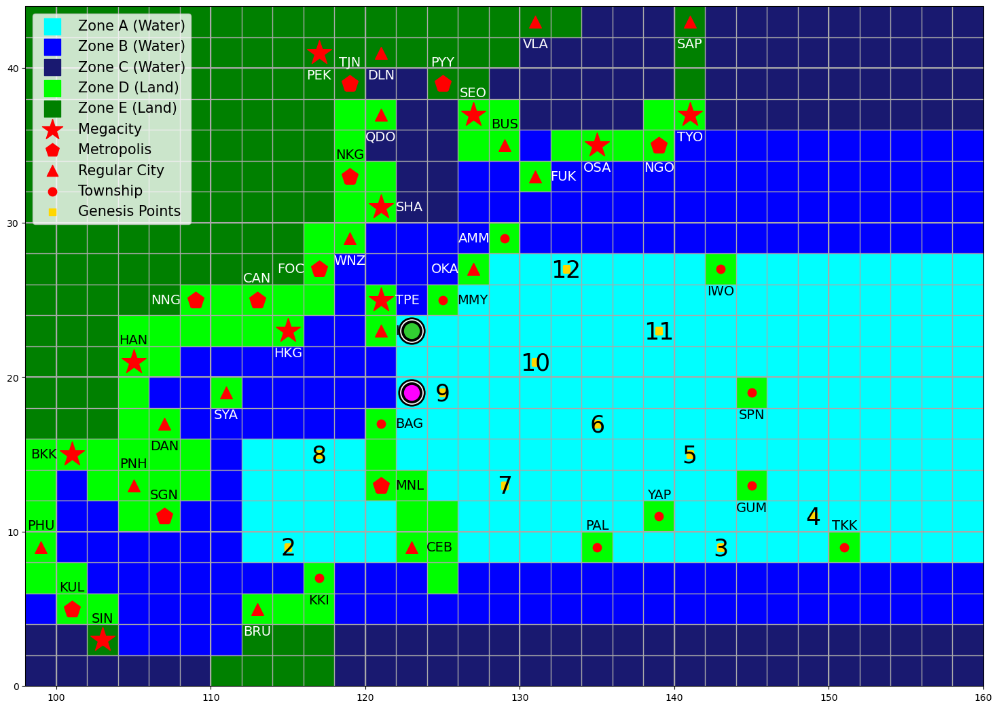


--- Round 5: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: W 1 N 1
1: W 1
2: Survival of the Fittest
3: S ?
4: W 1 N 1
Enter 'p' to pass.


Choose a card by index to play:  4


Demi played: W 1 N 1



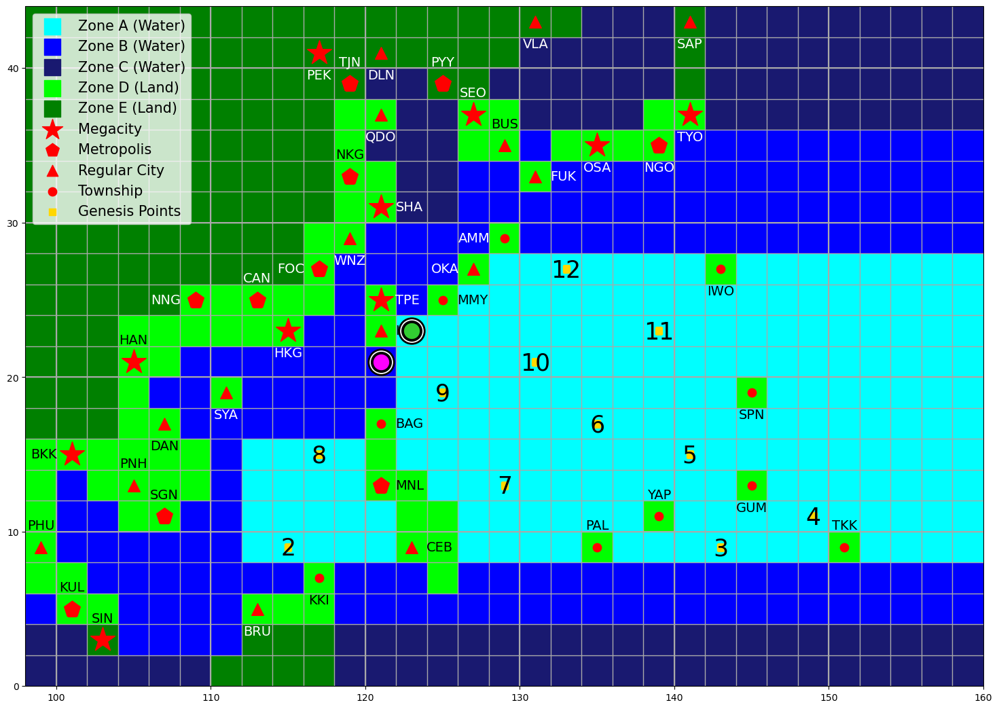


--- Round 5: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: W 1 N 1
1: W 1
2: Survival of the Fittest
3: S ?
Enter 'p' to pass.


Choose a card by index to play:  2


Demi played: Survival of the Fittest

Demi is immune from any weakening for the next 3 rounds.

--- End of Demi's turn ---
Demi's current intensity: 130 knots. Demi has gained 70 kJ.
Demi's Accumulated Cyclone Energy: 290 kJ.
Demi's total landfall costs: $0M.
The ocean has 1030 kJ of energy remaining.


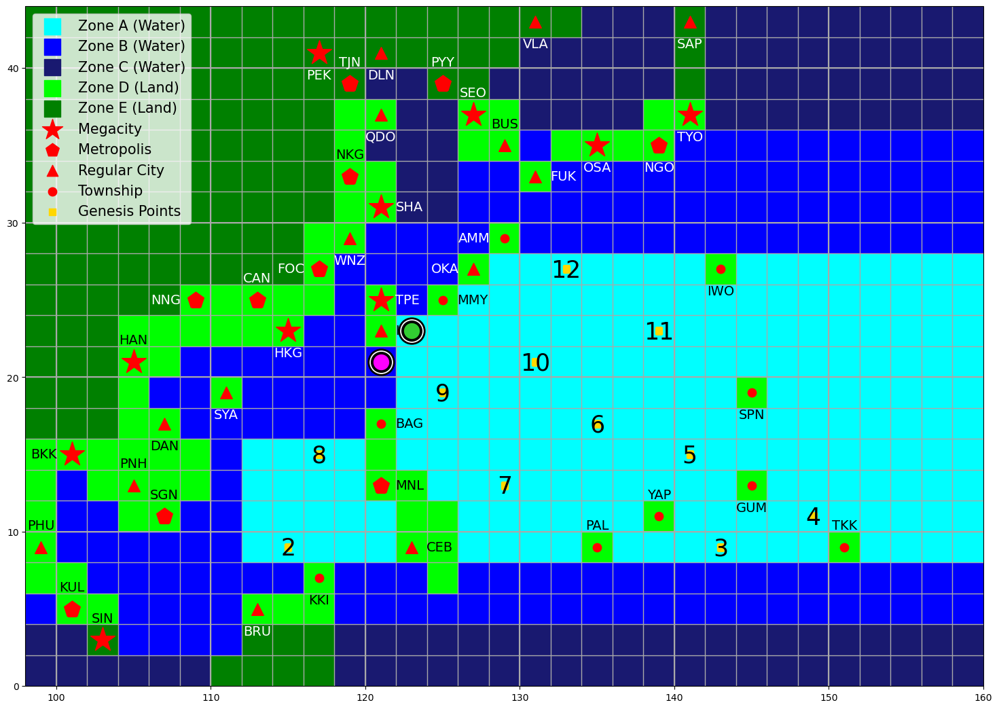

In [68]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 6: Kinen's turn ---


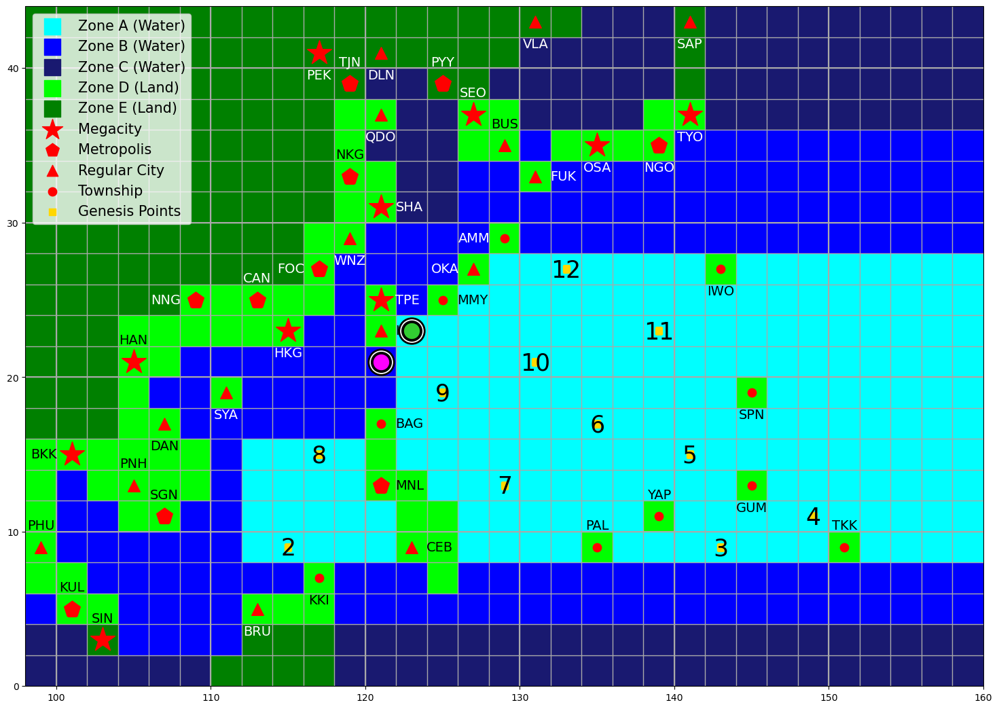

Intensity: 115 knots
Accumulated Cyclone Energy: 180 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
E ?
City Fortress
W ?

--- Round 6: Kinen's draw phase ---
0: Movement Deck (85 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 0


Kinen drew: N 1 from Movement Deck.

0: Movement Deck (84 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 0


Kinen drew: W/E 1 from Movement Deck.


--- Round 6: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E ?
1: City Fortress
2: W ?
3: N 1
4: W/E 1
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  4


Kinen played: W/E 1



Choose W or E:  W


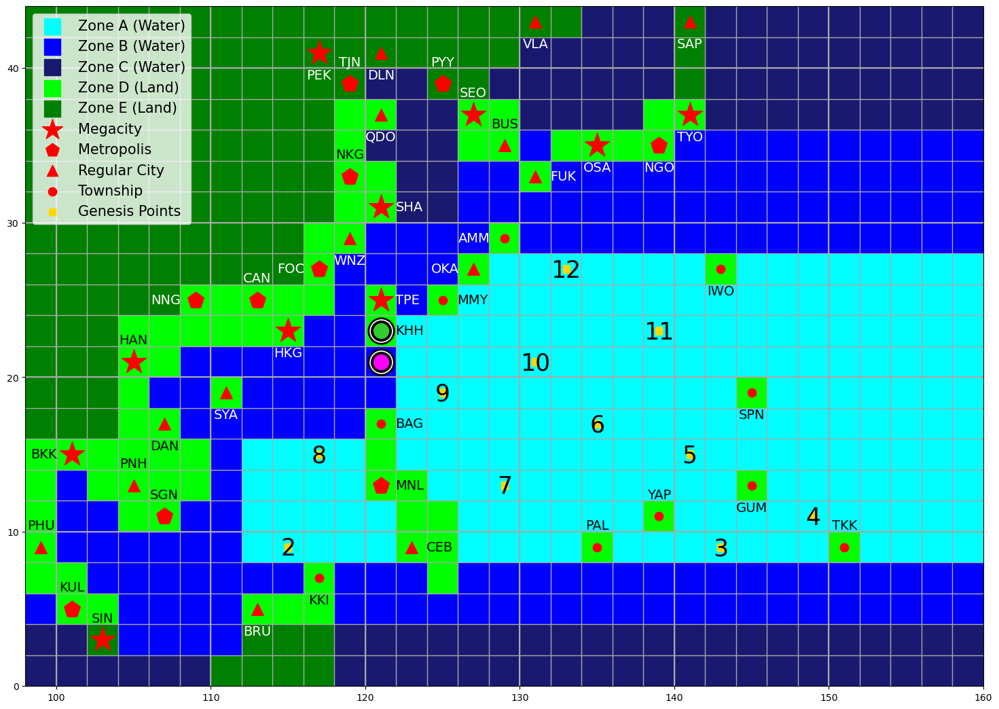

Kinen has made landfall at KHH (Kaohsiung) and gains $230M!
Remaining budget of KHH (Kaohsiung): $170M.

--- Round 6: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E ?
1: City Fortress
2: W ?
3: N 1
Enter 'p' to pass.


Choose a card by index to play:  3


Kinen played: N 1



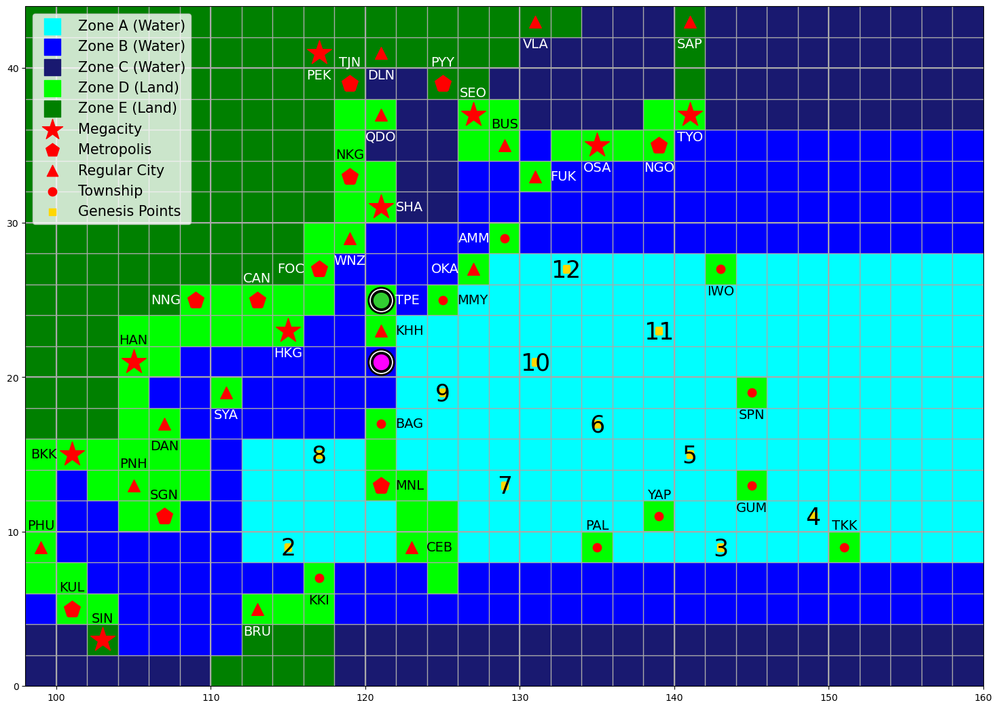

Kinen has made landfall at TPE (Taipei) and gains $575M!
Remaining budget of TPE (Taipei): $925M.

--- Round 6: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E ?
1: City Fortress
2: W ?
Enter 'p' to pass.


Choose a card by index to play:  0


Kinen played: E ?

Kinen rolled 4: E 4


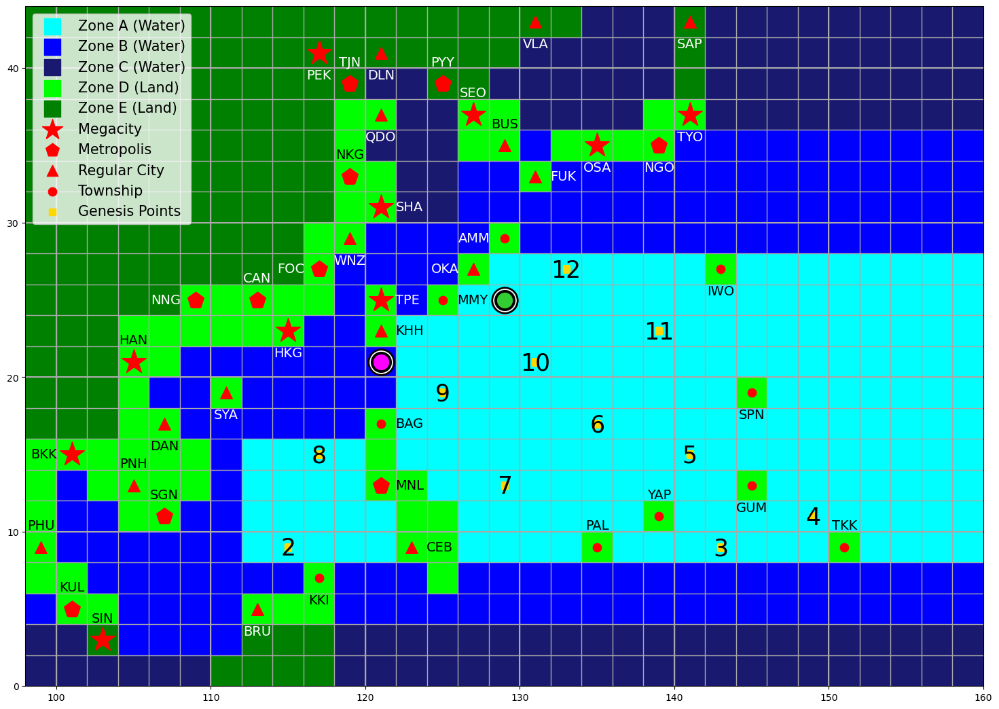


--- End of Kinen's turn ---
Kinen's current intensity: 115 knots. Kinen has gained 50 kJ.
Kinen's Accumulated Cyclone Energy: 230 kJ.
Kinen's total landfall costs: $805M.
The ocean has 980 kJ of energy remaining.


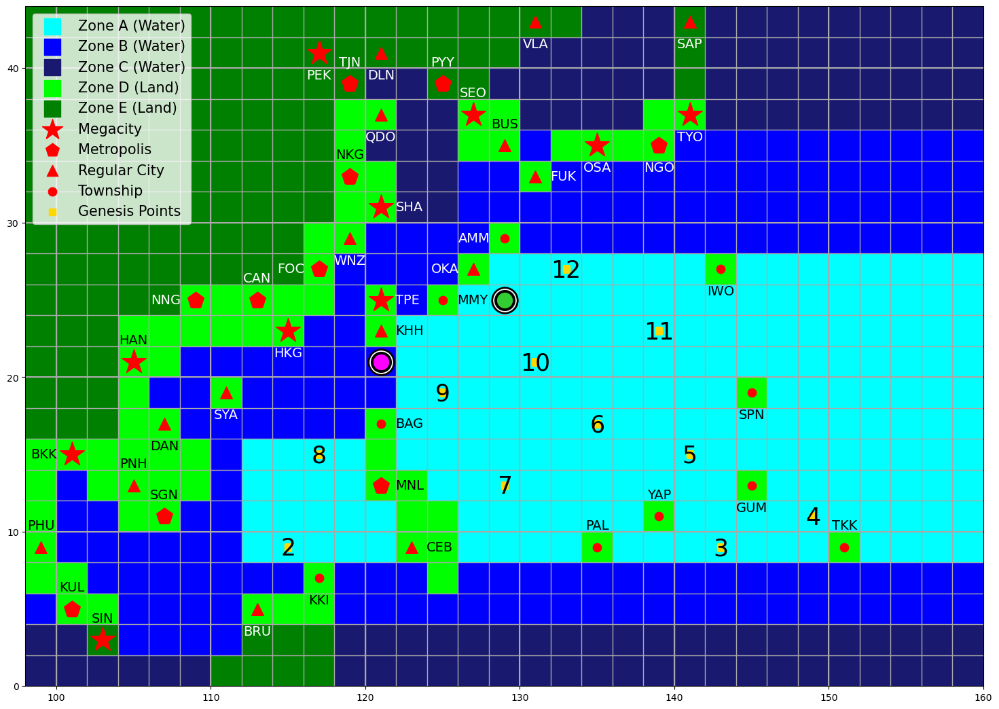

In [69]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 6: Demi's turn ---


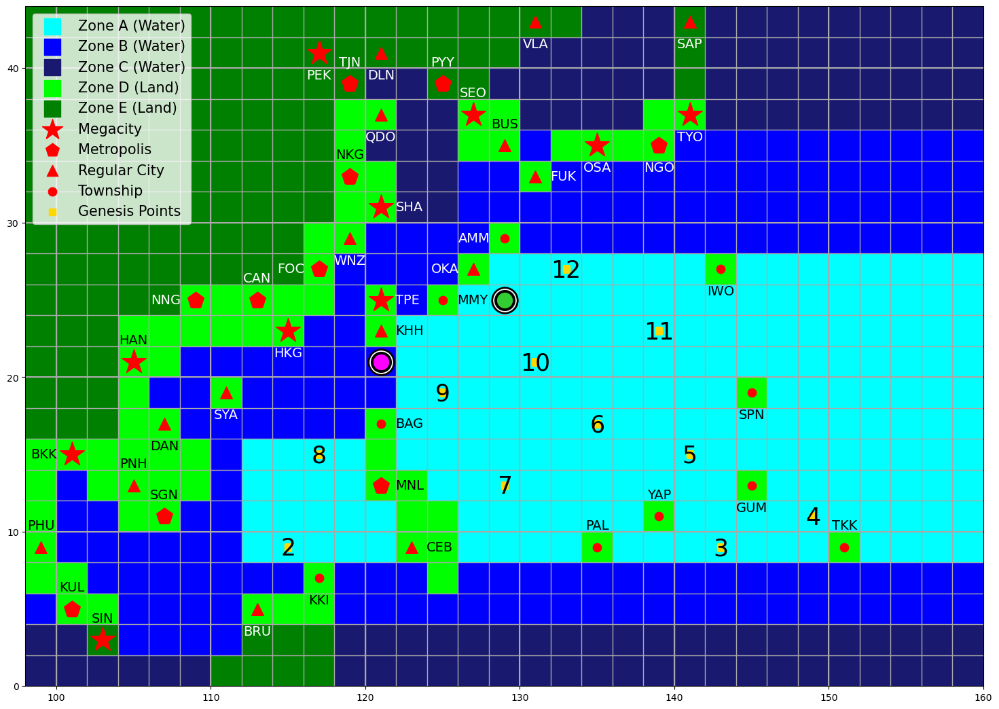

Intensity: 130 knots
Accumulated Cyclone Energy: 290 kJ
Landfall Costs: $0 M
Landfall Cities: []
Hand:
W 1 N 1
W 1
S ?

--- Round 6: Demi's draw phase ---
0: Movement Deck (83 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 0


Demi drew: N/S 1 from Movement Deck.

0: Movement Deck (82 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (43 cards left)


Choose a deck by index: 2


Demi drew: Instant Teleportation from Action Deck.


--- Round 6: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: W 1 N 1
1: W 1
2: S ?
3: N/S 1
4: Instant Teleportation
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  3


Demi played: N/S 1



Choose N or S:  N


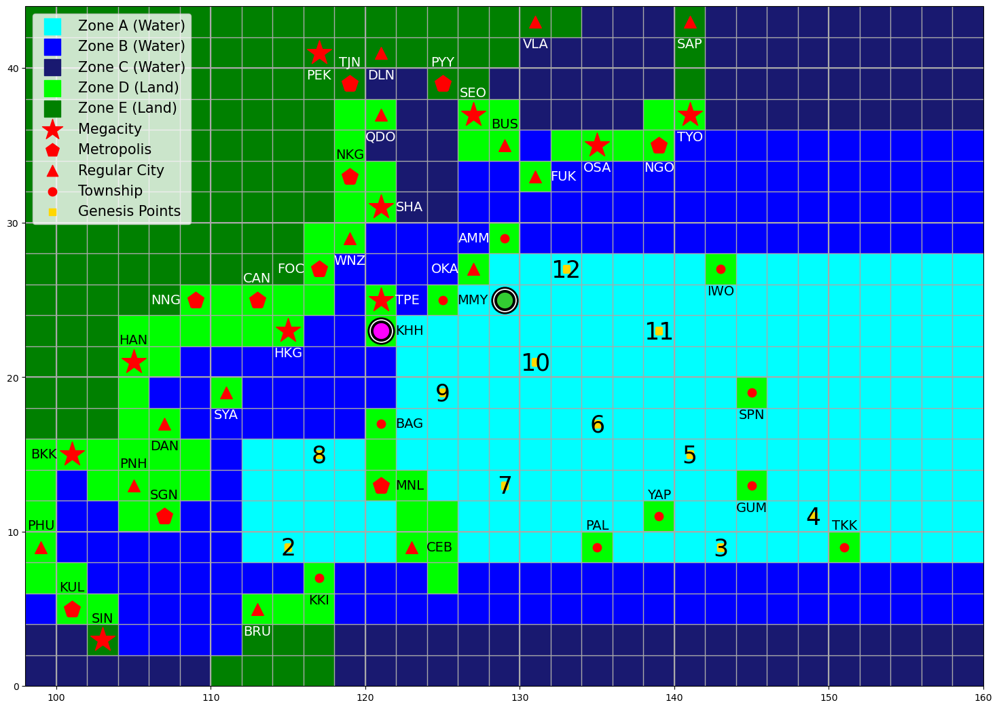

Demi has made landfall at KHH (Kaohsiung) and gains $170M!
Remaining budget of KHH (Kaohsiung): $0M.

--- Round 6: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: W 1 N 1
1: W 1
2: S ?
3: Instant Teleportation
Enter 'p' to pass.


Choose a card by index to play:  2


Demi played: S ?

Demi rolled 3: S 3


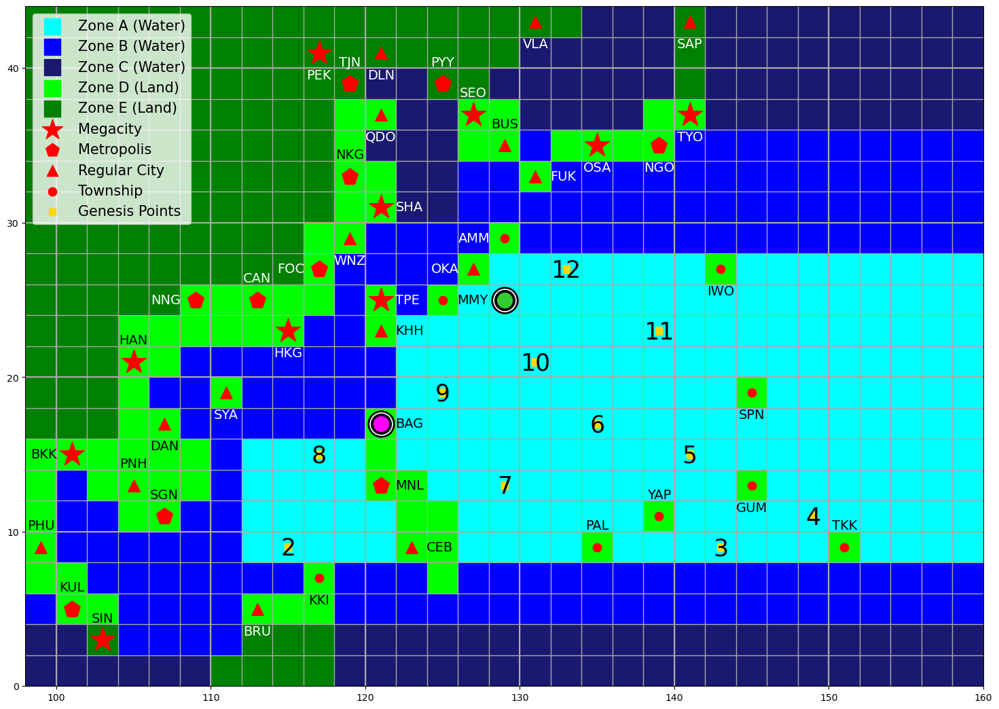

Demi has made landfall at BAG (Baguio) and gains $100M!
Remaining budget of BAG (Baguio): $0M.

--- Round 6: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: W 1 N 1
1: W 1
2: Instant Teleportation
Enter 'p' to pass.


Choose a card by index to play:  0


Demi played: W 1 N 1



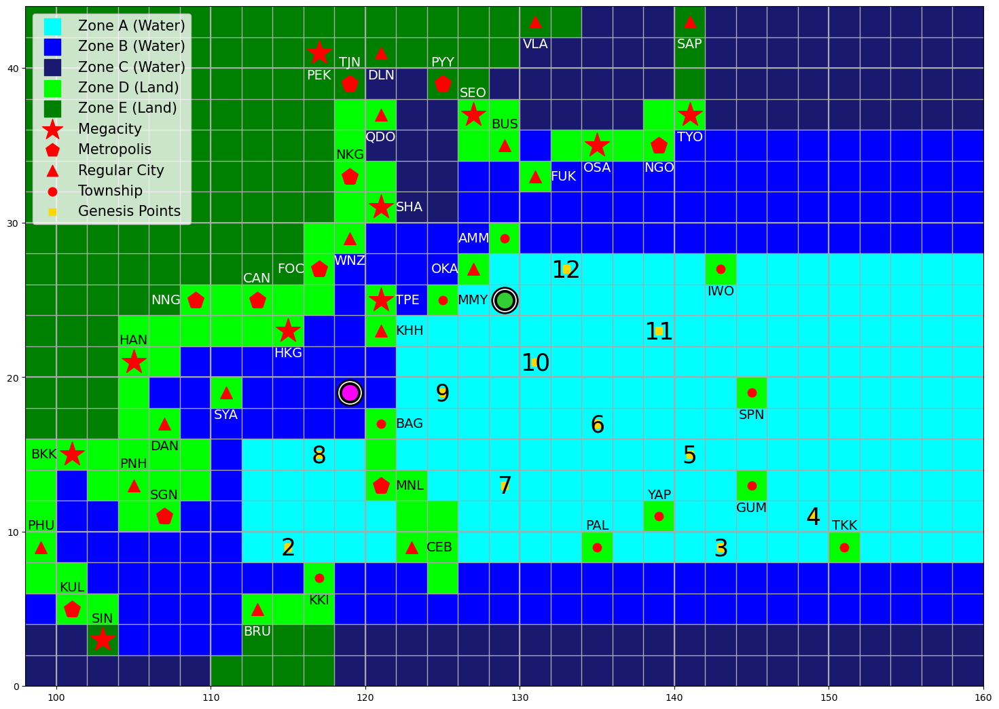


--- End of Demi's turn ---
Demi's current intensity: 130 knots. Demi has gained 70 kJ.
Demi's Accumulated Cyclone Energy: 360 kJ.
Demi's total landfall costs: $270M.
The ocean has 910 kJ of energy remaining.


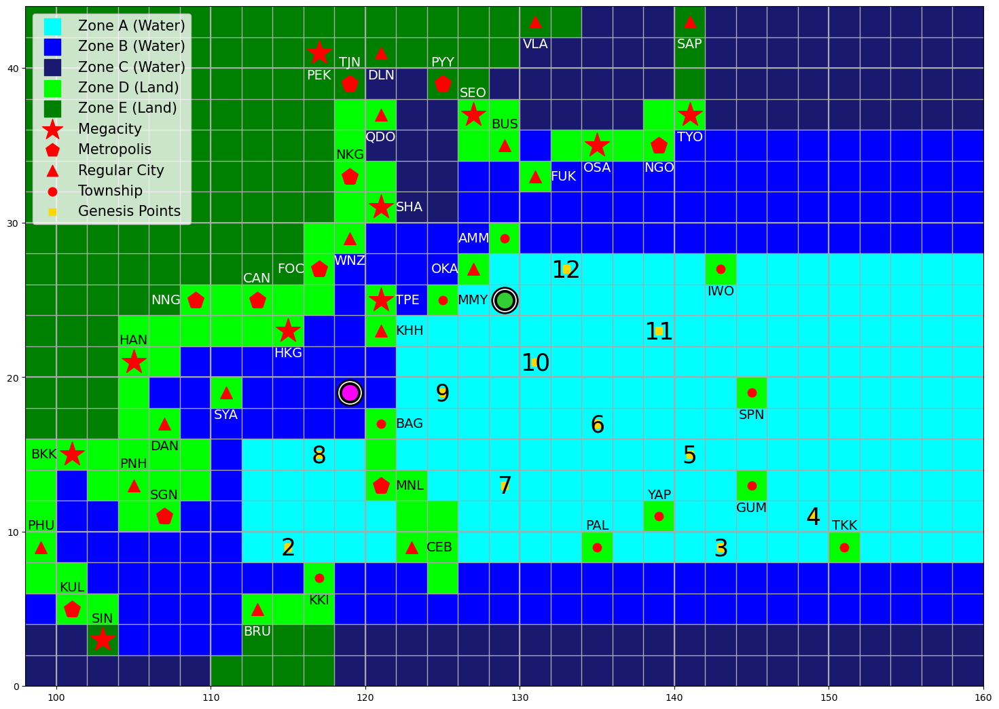

In [70]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 7: Kinen's turn ---


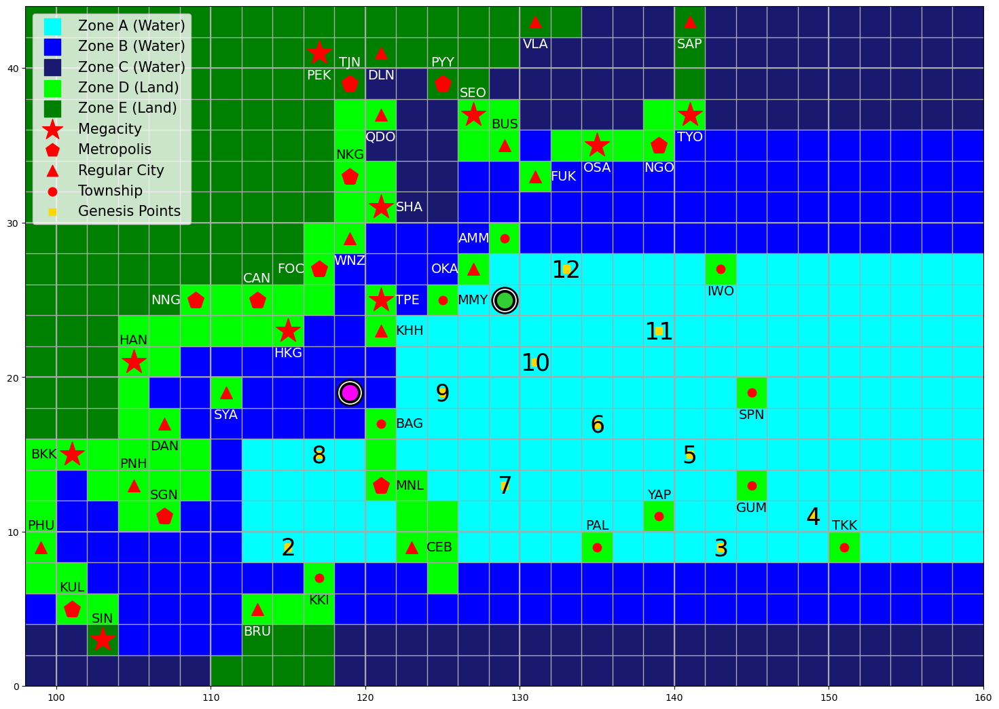

Intensity: 115 knots
Accumulated Cyclone Energy: 230 kJ
Landfall Costs: $805 M
Landfall Cities: ['KHH', 'TPE']
Hand:
City Fortress
W ?

--- Round 7: Kinen's draw phase ---
0: Movement Deck (82 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (42 cards left)


Choose a deck by index: 0


Kinen drew: N 3 from Movement Deck.

0: Movement Deck (81 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (42 cards left)


Choose a deck by index: 0


Kinen drew: E 1 S 1 from Movement Deck.


--- Round 7: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: City Fortress
1: W ?
2: N 3
3: E 1 S 1
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  2


Kinen played: N 3



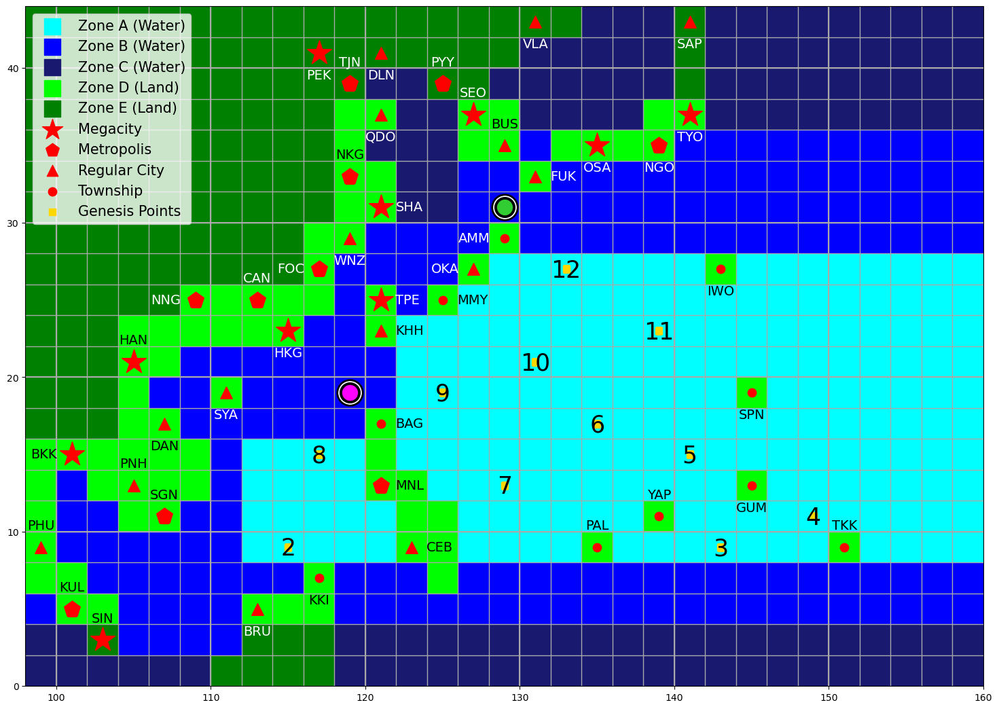


--- Round 7: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: City Fortress
1: W ?
2: E 1 S 1
Enter 'p' to pass.


Choose a card by index to play:  1


Kinen played: W ?

Kinen rolled 3: W 3


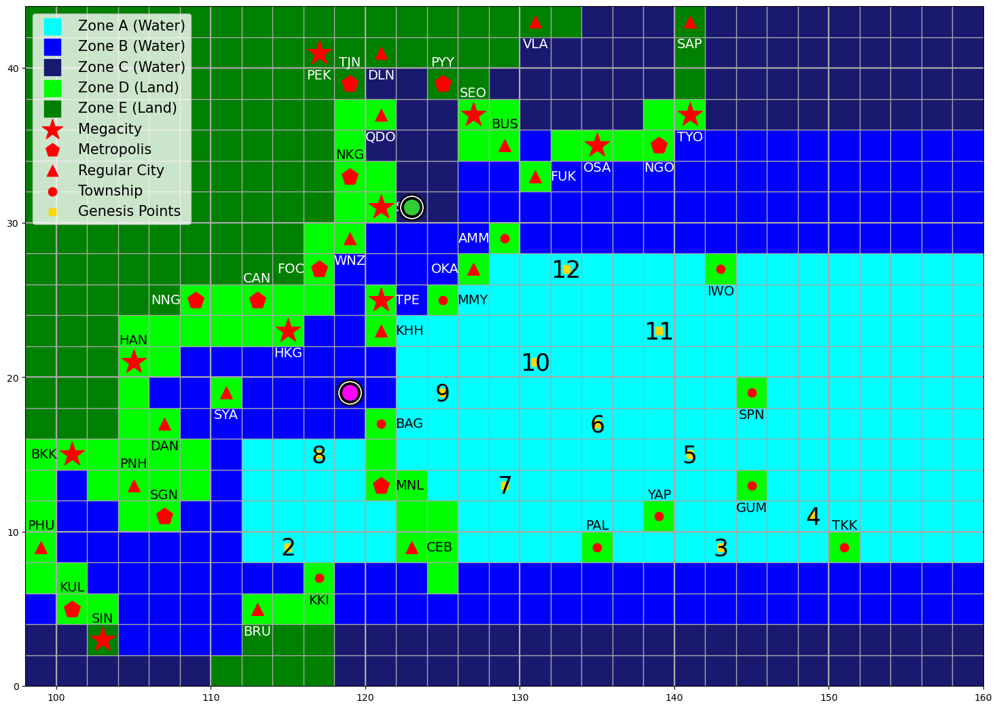


--- Round 7: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: City Fortress
1: E 1 S 1
Enter 'p' to pass.


Choose a card by index to play:  0


Kinen played: City Fortress



Select a city by inputting its three letter code: HKG


HKG is protected from being impacted by any opponent for the next 3 rounds.

--- End of Kinen's turn ---
Kinen's current intensity: 115 knots. Kinen has gained 50 kJ.
Kinen's Accumulated Cyclone Energy: 280 kJ.
Kinen's total landfall costs: $805M.
The ocean has 860 kJ of energy remaining.
Kinen has weakened to 110 knots.


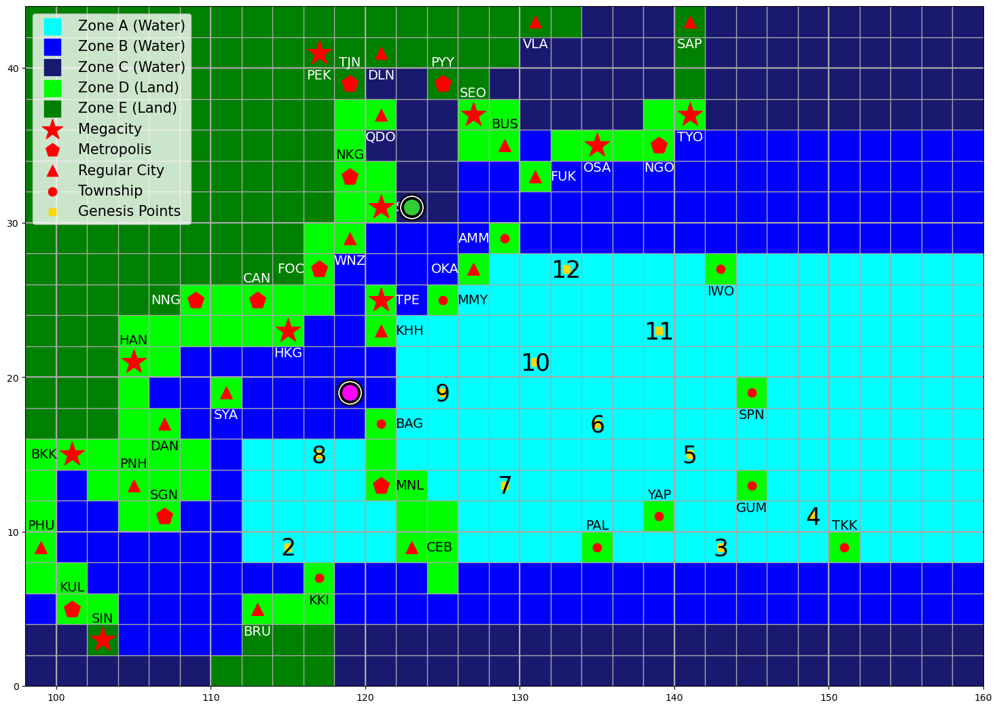

In [71]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 7: Demi's turn ---


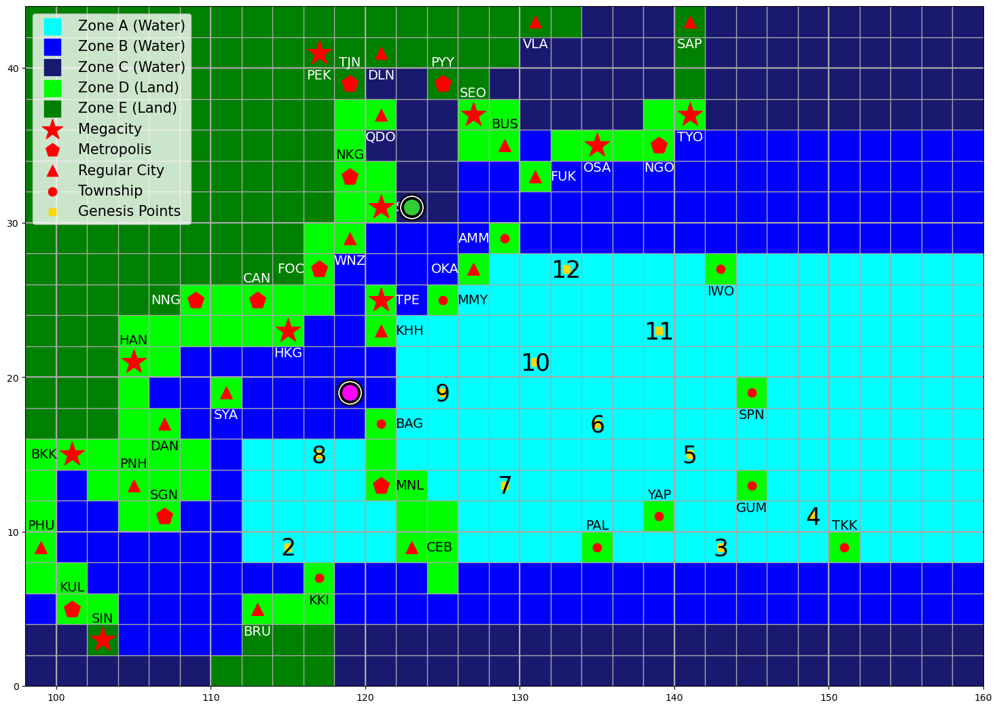

Intensity: 130 knots
Accumulated Cyclone Energy: 360 kJ
Landfall Costs: $270 M
Landfall Cities: ['KHH', 'BAG']
Hand:
W 1
Instant Teleportation

--- Round 7: Demi's draw phase ---
0: Movement Deck (80 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (42 cards left)


Choose a deck by index: 0


Demi drew: N 2 from Movement Deck.

0: Movement Deck (79 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (42 cards left)


Choose a deck by index: 0


Demi drew: N ? from Movement Deck.


--- Round 7: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: W 1
1: Instant Teleportation
2: N 2
3: N ?
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  3


Demi played: N ?

Demi rolled 5: N 5


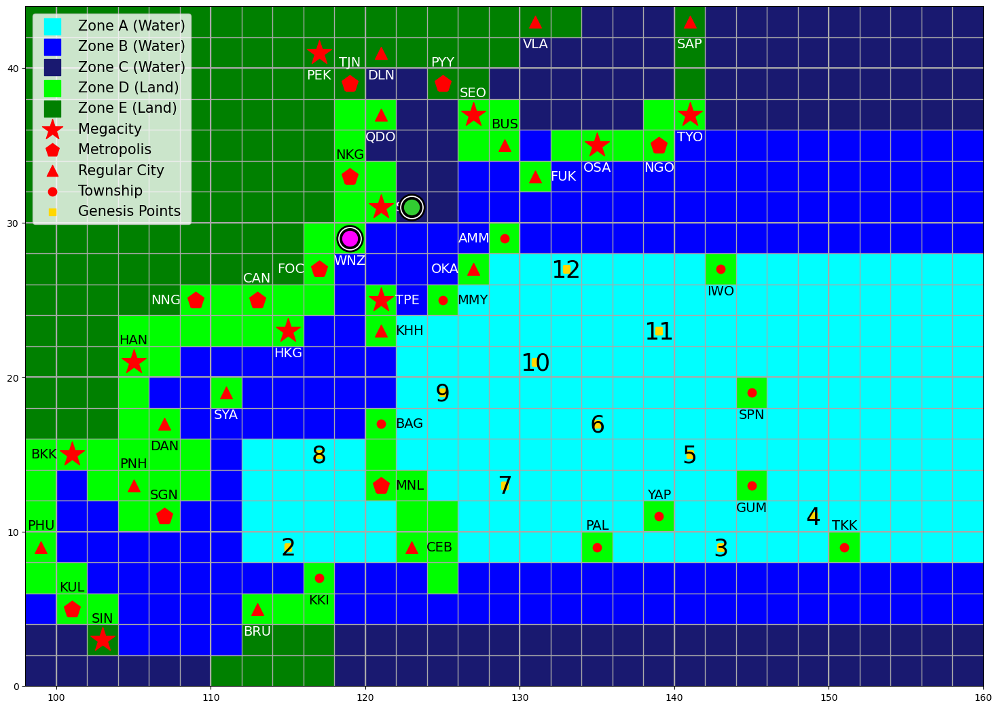

Demi has made landfall at WNZ (Wenzhou) and gains $260M!
Remaining budget of WNZ (Wenzhou): $140M.

--- Round 7: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: W 1
1: Instant Teleportation
2: N 2
Enter 'p' to pass.


Choose a card by index to play:  2


Demi played: N 2



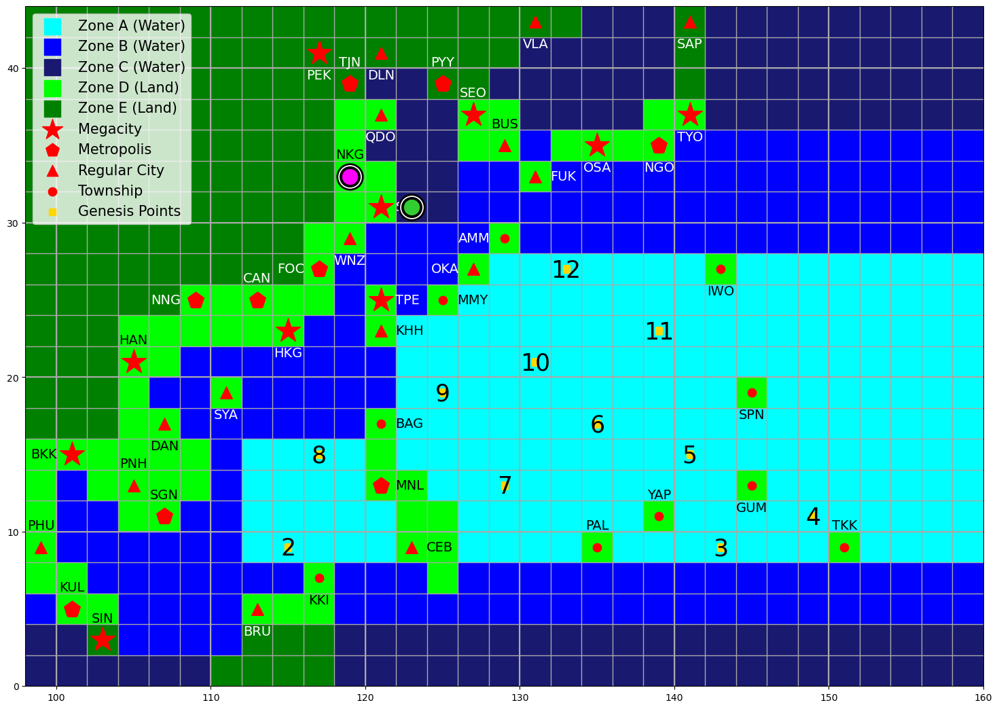

Demi has made landfall at NKG (Nanjing) and gains $390M!
Remaining budget of NKG (Nanjing): $360M.

--- Round 7: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: W 1
1: Instant Teleportation
Enter 'p' to pass.


Choose a card by index to play:  p


Demi passes.

--- End of Demi's turn ---
Demi's current intensity: 130 knots. Demi has gained 70 kJ.
Demi's Accumulated Cyclone Energy: 430 kJ.
Demi's total landfall costs: $920M.
The ocean has 790 kJ of energy remaining.


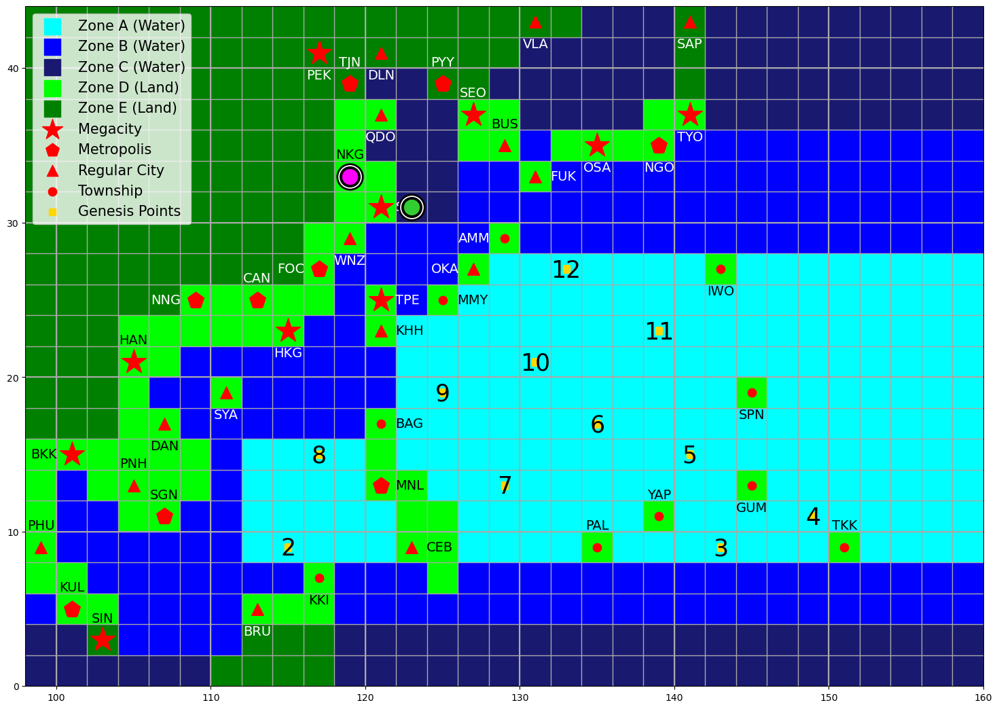

In [72]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 8: Kinen's turn ---


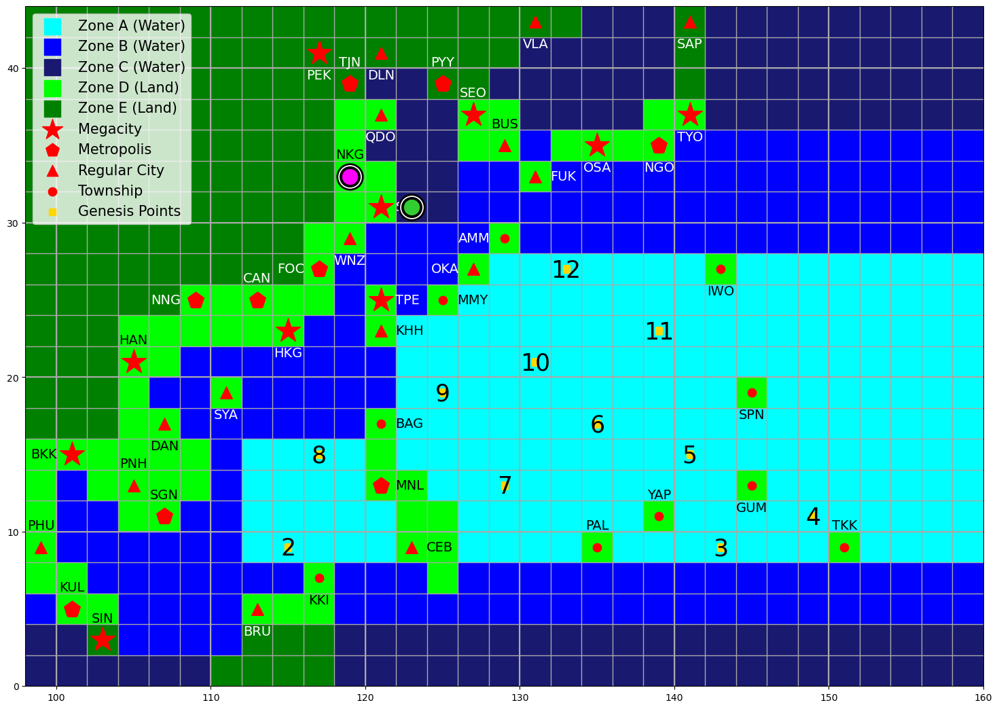

Intensity: 110 knots
Accumulated Cyclone Energy: 280 kJ
Landfall Costs: $805 M
Landfall Cities: ['KHH', 'TPE']
Hand:
E 1 S 1

--- Round 8: Kinen's draw phase ---
0: Movement Deck (78 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (42 cards left)


Choose a deck by index: 0


Kinen drew: W 2 N 1 from Movement Deck.

0: Movement Deck (77 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (42 cards left)


Choose a deck by index: 0


Kinen drew: E 1 from Movement Deck.


--- Round 8: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E 1 S 1
1: W 2 N 1
2: E 1
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  1


Kinen played: W 2 N 1



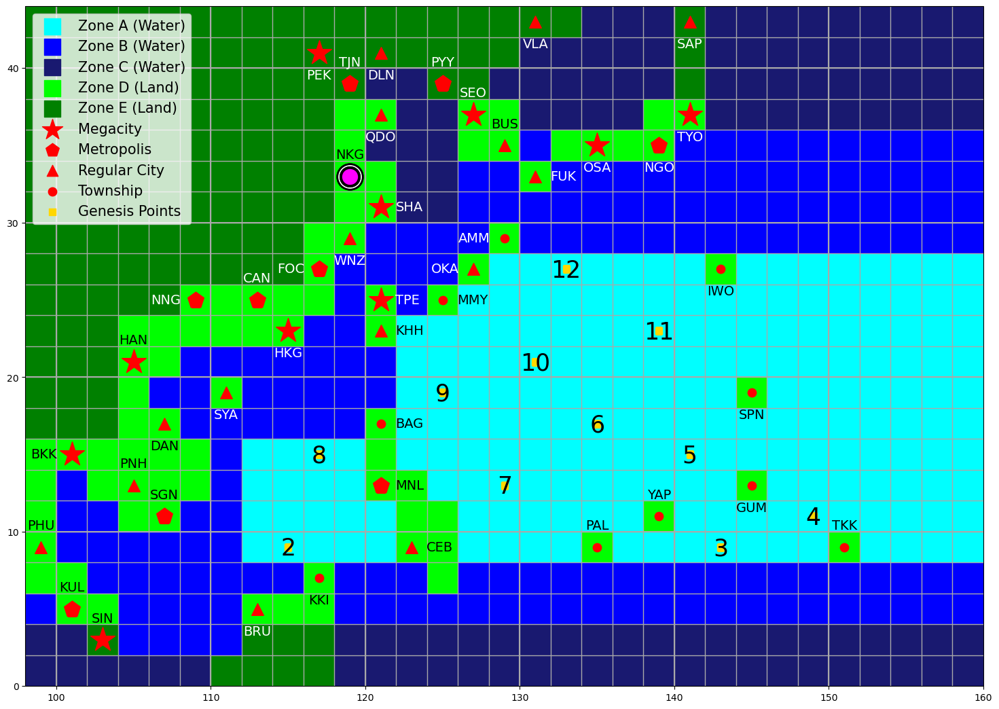

Kinen has made landfall at NKG (Nanjing) and gains $330M!
Remaining budget of NKG (Nanjing): $30M.

--- Round 8: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E 1 S 1
1: E 1
Enter 'p' to pass.


Choose a card by index to play:  0


Kinen played: E 1 S 1



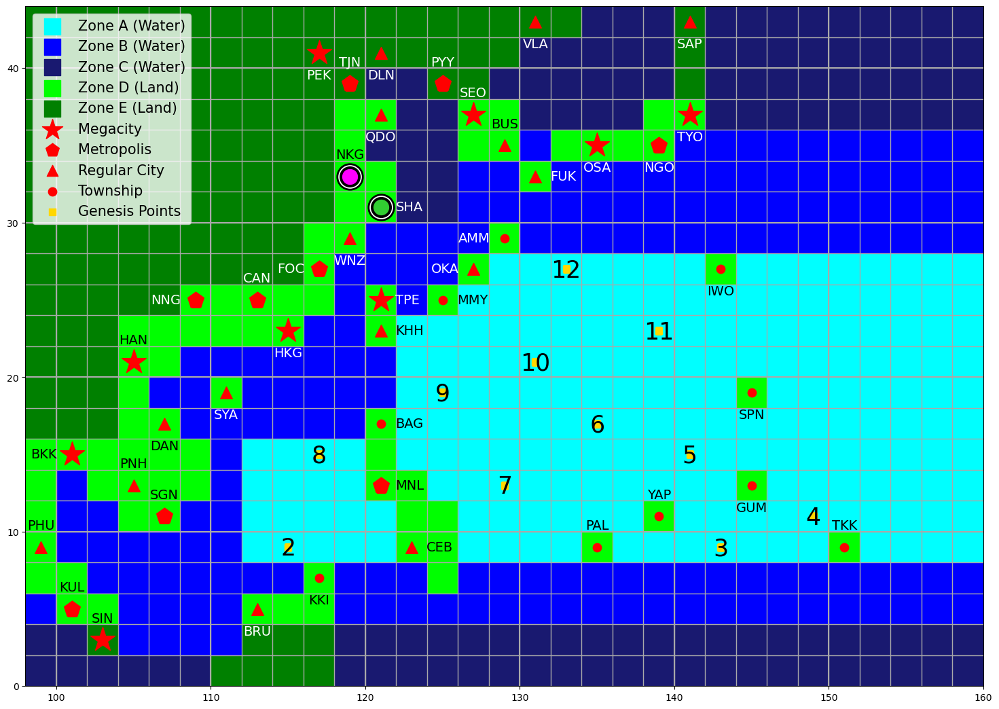

Kinen has made landfall at SHA (Shanghai) and gains $550M!
Remaining budget of SHA (Shanghai): $950M.

--- Round 8: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E 1
Enter 'p' to pass.


Choose a card by index to play:  0


Kinen played: E 1



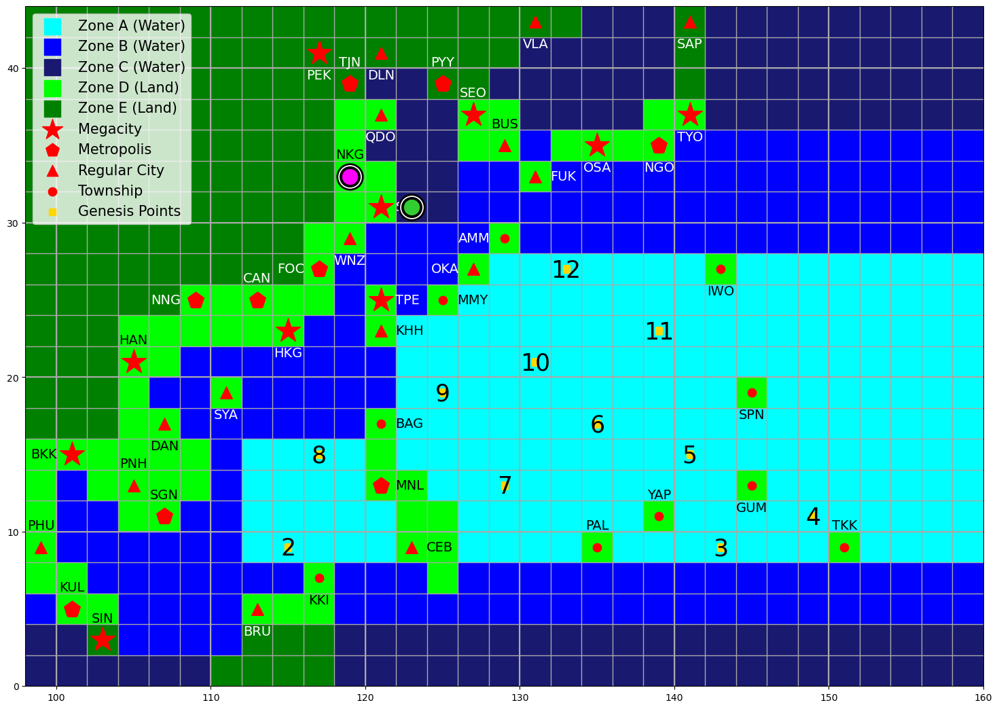


--- End of Kinen's turn ---
Kinen's current intensity: 110 knots. Kinen has gained 50 kJ.
Kinen's Accumulated Cyclone Energy: 330 kJ.
Kinen's total landfall costs: $1685M.
The ocean has 740 kJ of energy remaining.
Kinen has weakened to 105 knots.


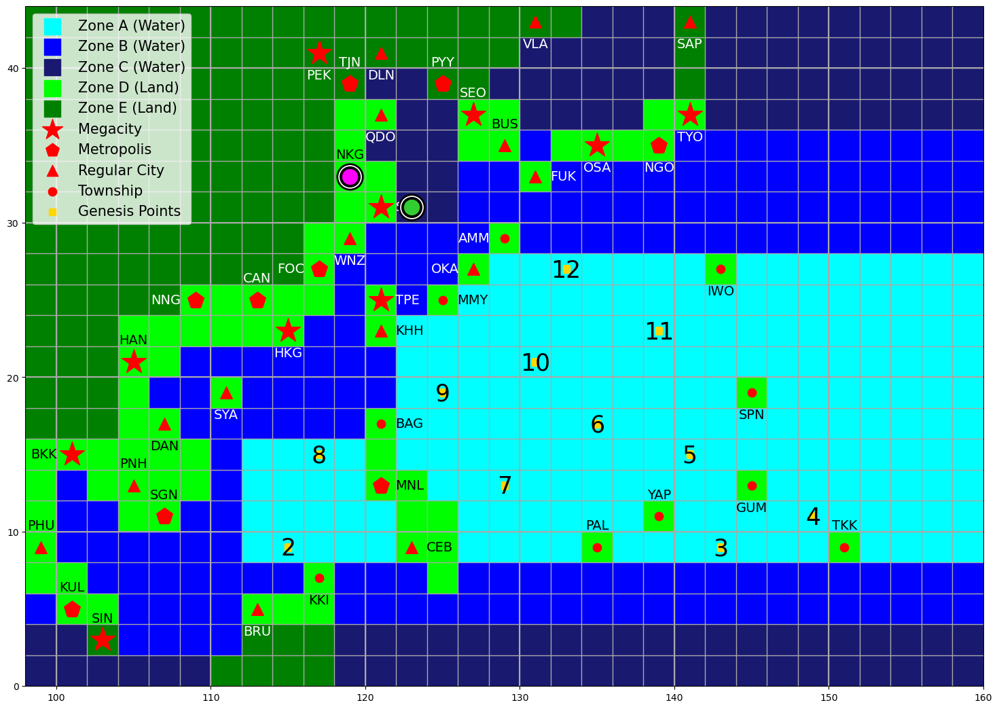

In [73]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 8: Demi's turn ---


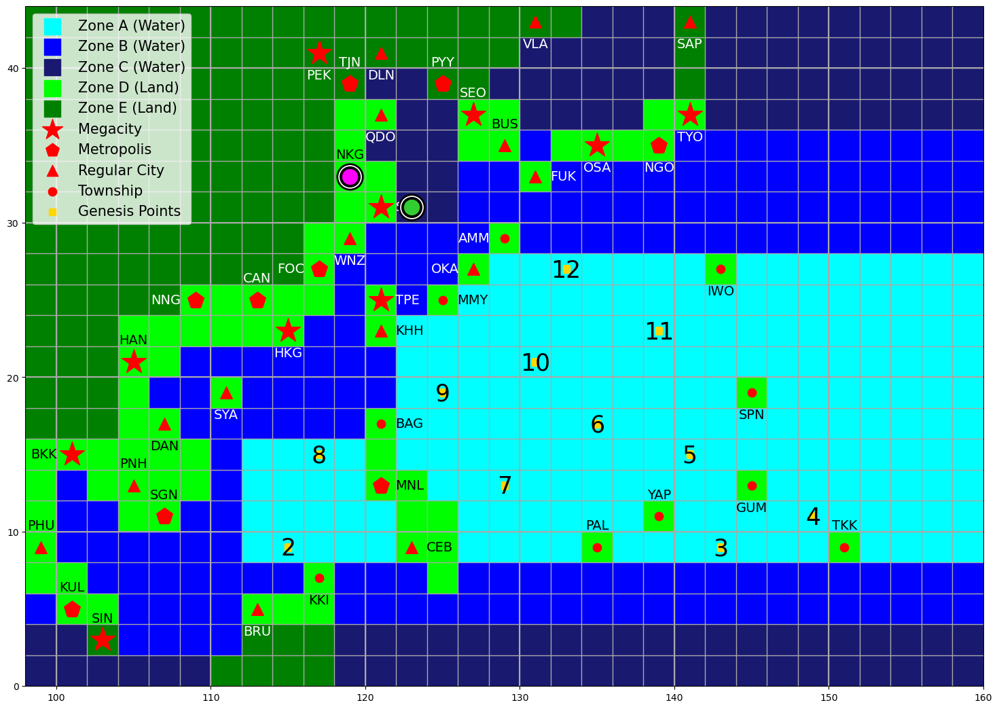

Intensity: 130 knots
Accumulated Cyclone Energy: 430 kJ
Landfall Costs: $920 M
Landfall Cities: ['KHH', 'BAG', 'WNZ', 'NKG']
Hand:
W 1
Instant Teleportation

--- Round 8: Demi's draw phase ---
0: Movement Deck (76 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (42 cards left)


Choose a deck by index: 0


Demi drew: W 2 S 1 from Movement Deck.

0: Movement Deck (75 cards left)
1: Intensity Deck (86 cards left)
2: Action Deck (42 cards left)


Choose a deck by index: 0


Demi drew: W 1 S 1 from Movement Deck.


--- Round 8: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: W 1
1: Instant Teleportation
2: W 2 S 1
3: W 1 S 1
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  1


Demi played: Instant Teleportation



Select a genesis point between 2 and 12: 12


Demi has teleported to genesis point 12.


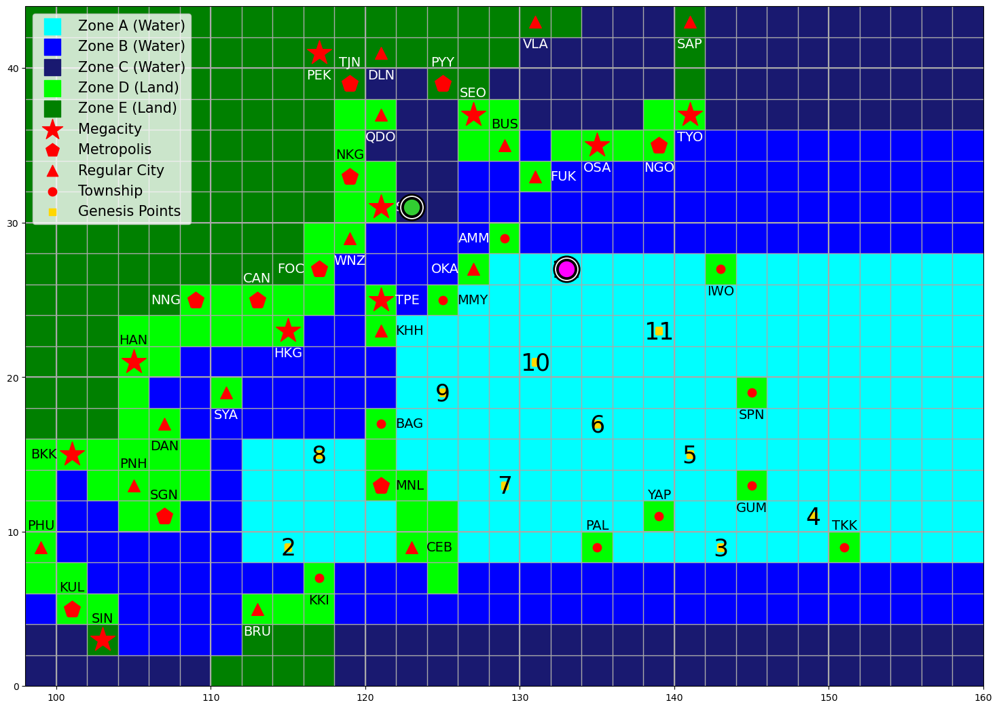


--- Round 8: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: W 1
1: W 2 S 1
2: W 1 S 1
Enter 'p' to pass.


Choose a card by index to play:  0


Demi played: W 1



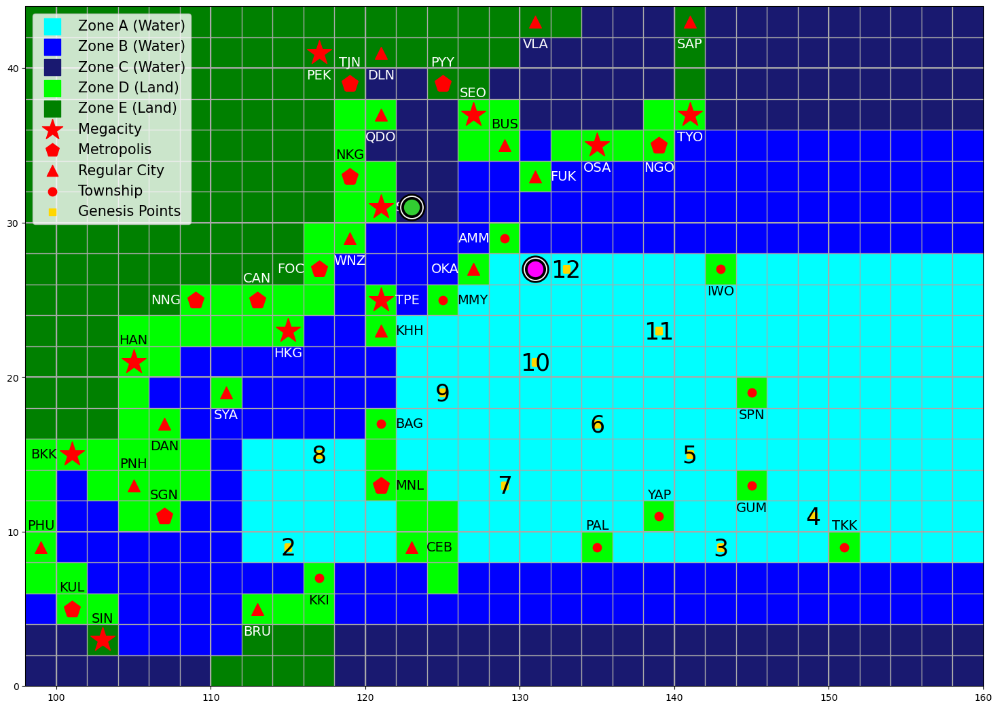


--- Round 8: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: W 2 S 1
1: W 1 S 1
Enter 'p' to pass.


Choose a card by index to play:  0


Demi played: W 2 S 1



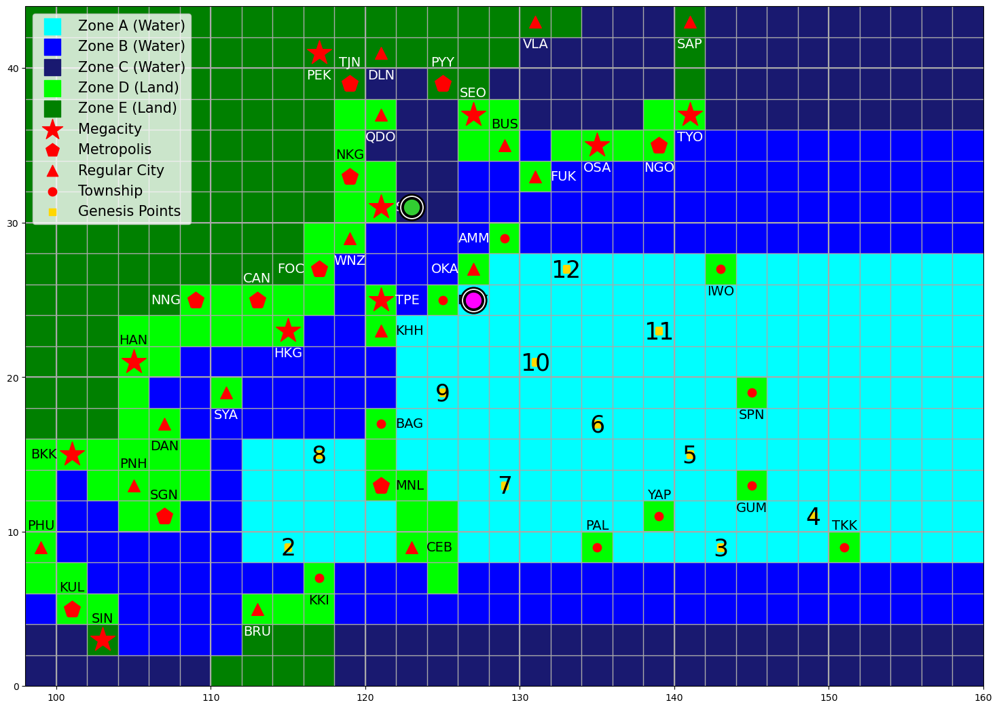


--- End of Demi's turn ---
Demi's current intensity: 130 knots. Demi has gained 70 kJ.
Demi's Accumulated Cyclone Energy: 500 kJ.
Demi's total landfall costs: $920M.
The ocean has 670 kJ of energy remaining.


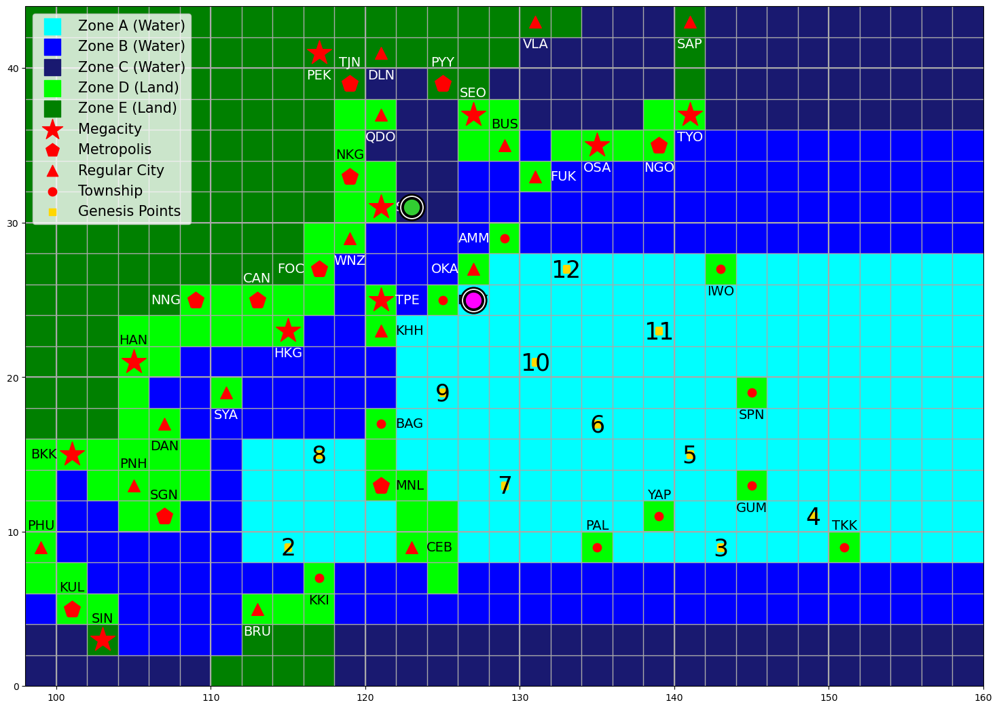

In [74]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 9: Kinen's turn ---


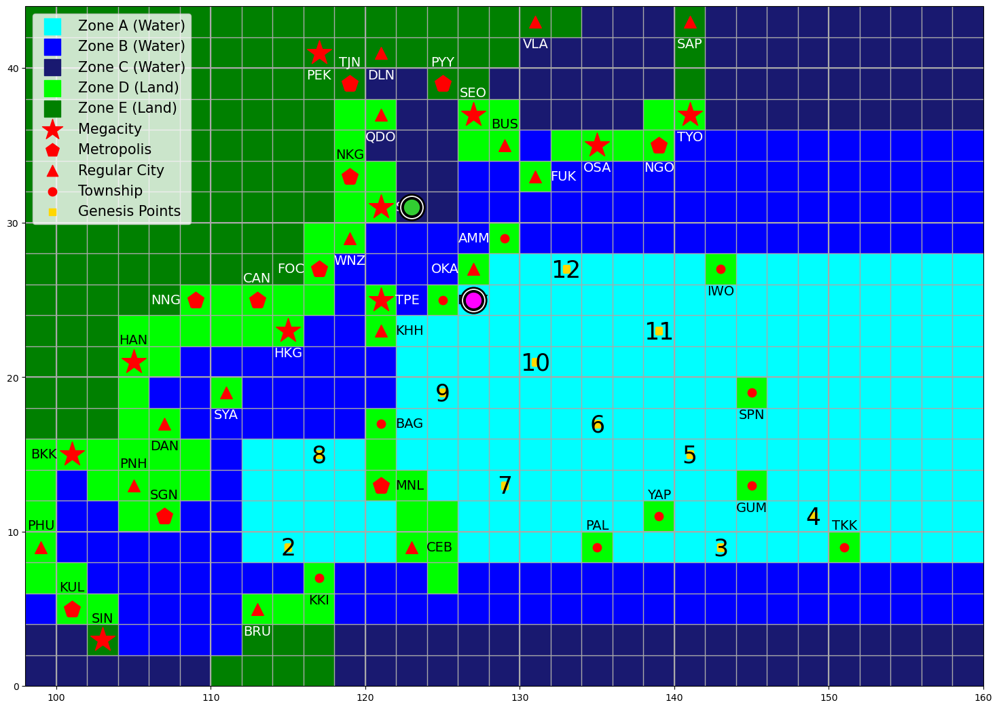

Intensity: 105 knots
Accumulated Cyclone Energy: 330 kJ
Landfall Costs: $1685 M
Landfall Cities: ['KHH', 'TPE', 'NKG', 'SHA']
Hand:

--- Round 9: Kinen's draw phase ---
Kinen has no cards left and draws a new 10 card hand.
Kinen drew: E 1 N 1 from Movement Deck.
Kinen drew: W 2 from Movement Deck.
Kinen drew: W 4 from Movement Deck.
Kinen drew: N 2 from Movement Deck.
Kinen drew: +5 W/m^2 from Intensity Deck.
Kinen drew: + ? W/m^2 from Intensity Deck.
Kinen drew: +15 W/m^2 from Intensity Deck.
Kinen drew: +15 W/m^2 from Intensity Deck.
Kinen drew: Factory Reset from Action Deck.
Kinen drew: Instant Teleportation from Action Deck.

--- Round 9: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E 1 N 1
1: W 2
2: W 4
3: N 2
4: +5 W/m^2
5: + ? W/m^2
6: +15 W/m^2
7: +15 W/m^2
8: Factory Reset
9: Instant Teleportation
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  9


Kinen played: Instant Teleportation



Select a genesis point between 2 and 12: 9


Kinen has teleported to genesis point 9.


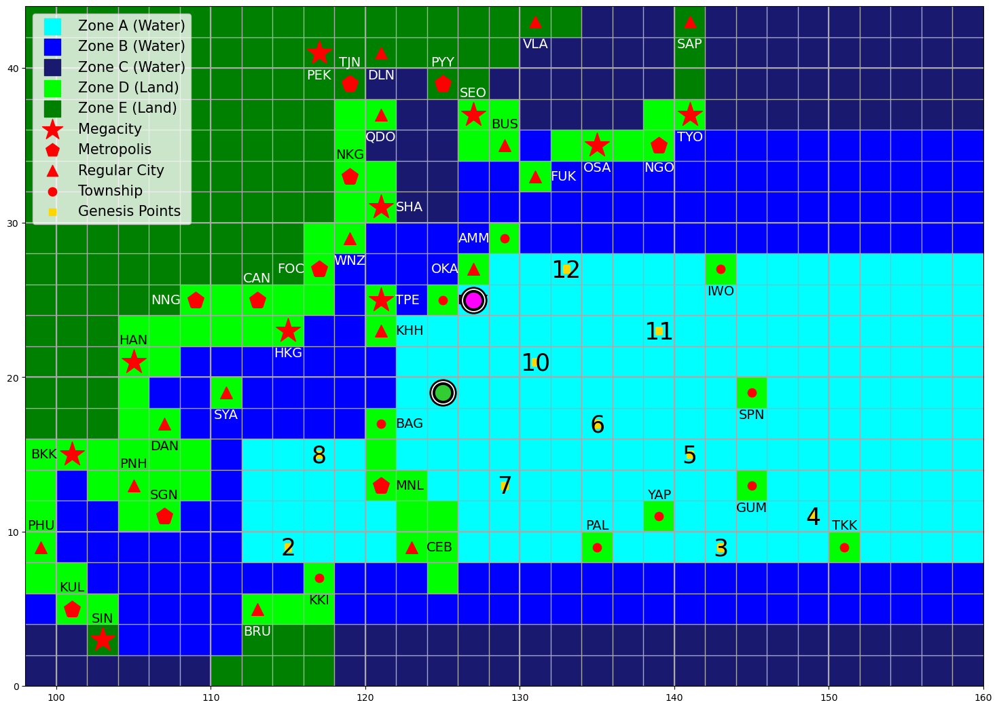


--- Round 9: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E 1 N 1
1: W 2
2: W 4
3: N 2
4: +5 W/m^2
5: + ? W/m^2
6: +15 W/m^2
7: +15 W/m^2
8: Factory Reset
Enter 'p' to pass.


Choose a card by index to play:  5


Kinen played: + ? W/m^2

Kinen rolled 2: + 10 W/m^2
Kinen has intensified to 110 knots!

--- Round 9: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E 1 N 1
1: W 2
2: W 4
3: N 2
4: +5 W/m^2
5: +15 W/m^2
6: +15 W/m^2
7: Factory Reset
Enter 'p' to pass.


Choose a card by index to play:  5


Kinen played: +15 W/m^2

Kinen has intensified to 115 knots!

--- End of Kinen's turn ---
Kinen's current intensity: 115 knots. Kinen has gained 50 kJ.
Kinen's Accumulated Cyclone Energy: 380 kJ.
Kinen's total landfall costs: $1685M.
The ocean has 620 kJ of energy remaining.


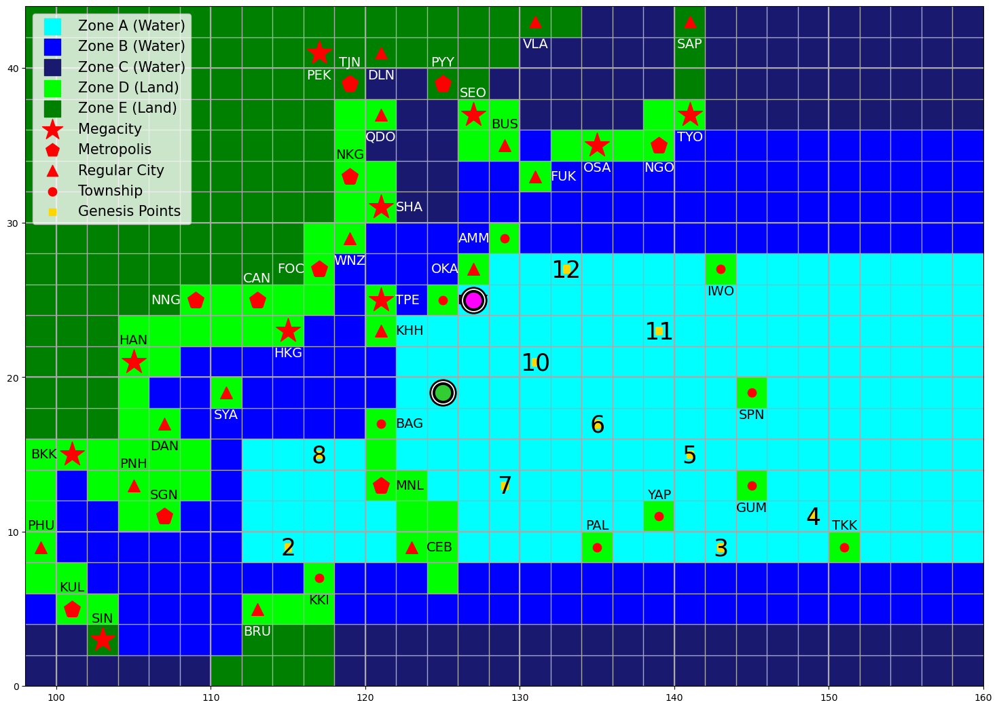

In [75]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 9: Demi's turn ---


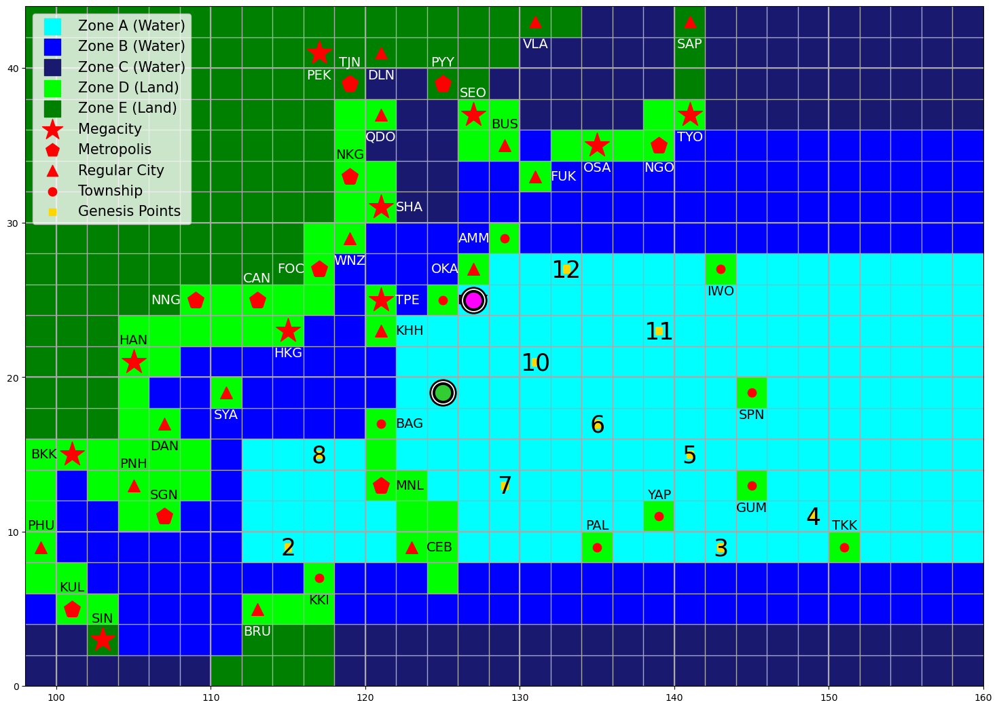

Intensity: 130 knots
Accumulated Cyclone Energy: 500 kJ
Landfall Costs: $920 M
Landfall Cities: ['KHH', 'BAG', 'WNZ', 'NKG']
Hand:
W 1 S 1

--- Round 9: Demi's draw phase ---
0: Movement Deck (70 cards left)
1: Intensity Deck (82 cards left)
2: Action Deck (40 cards left)


Choose a deck by index: 0


Demi drew: E 2 S 1 from Movement Deck.

0: Movement Deck (69 cards left)
1: Intensity Deck (82 cards left)
2: Action Deck (40 cards left)


Choose a deck by index: 0


Demi drew: W 1 from Movement Deck.


--- Round 9: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: W 1 S 1
1: E 2 S 1
2: W 1
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  2


Demi played: W 1



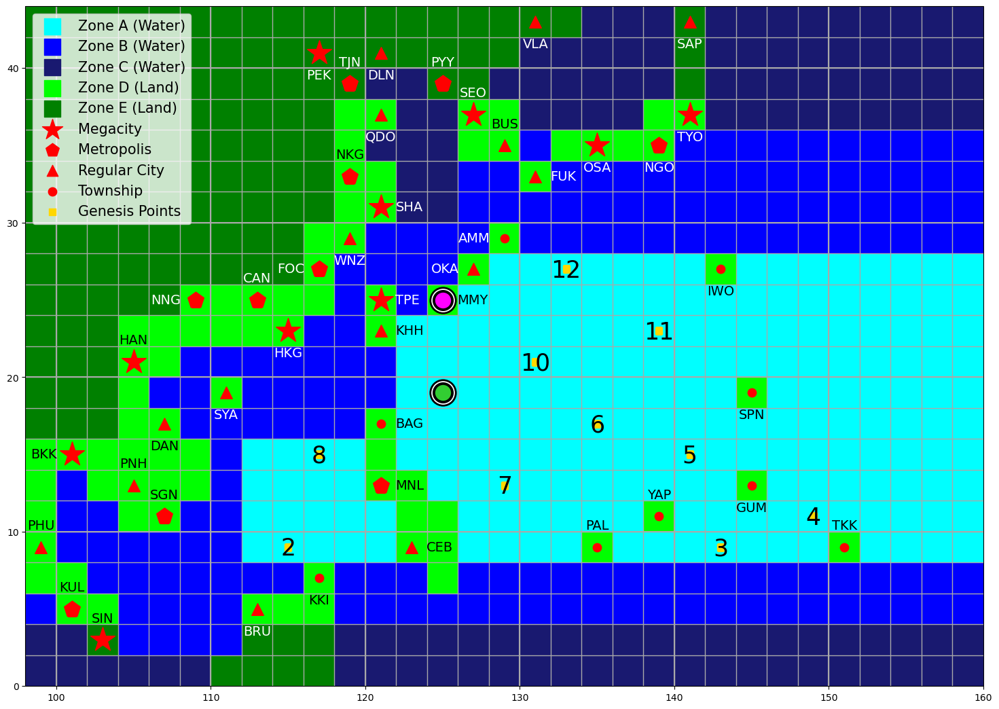

Demi has made landfall at MMY (Miyakojima) and gains $100M!
Remaining budget of MMY (Miyakojima): $0M.

--- Round 9: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: W 1 S 1
1: E 2 S 1
Enter 'p' to pass.


Choose a card by index to play:  0


Demi played: W 1 S 1



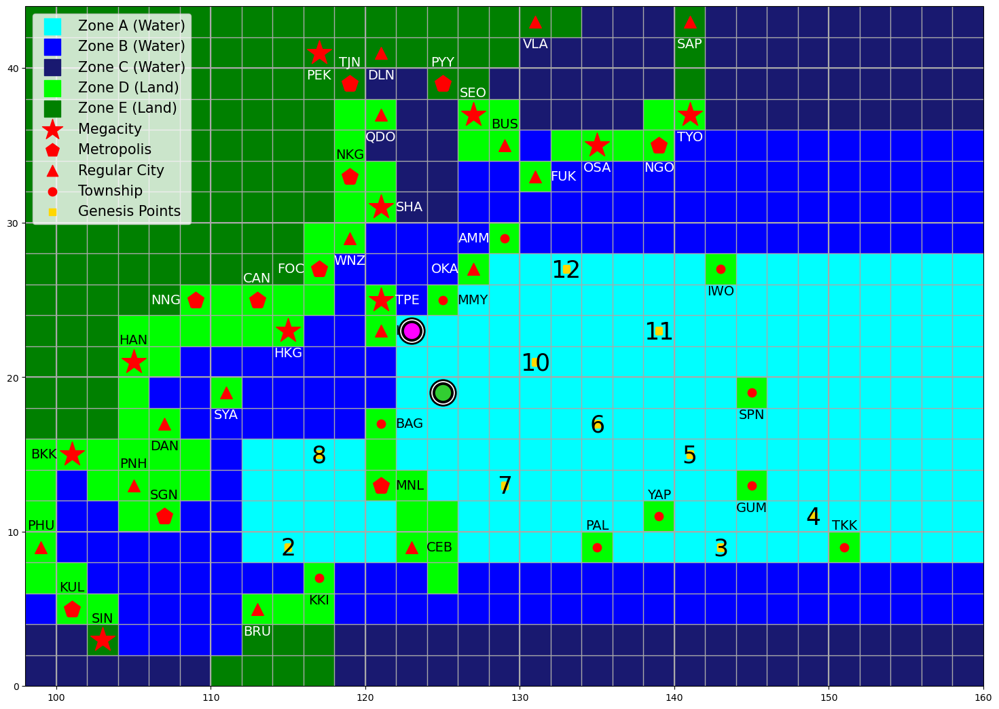


--- Round 9: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E 2 S 1
Enter 'p' to pass.


Choose a card by index to play:  0


Demi played: E 2 S 1



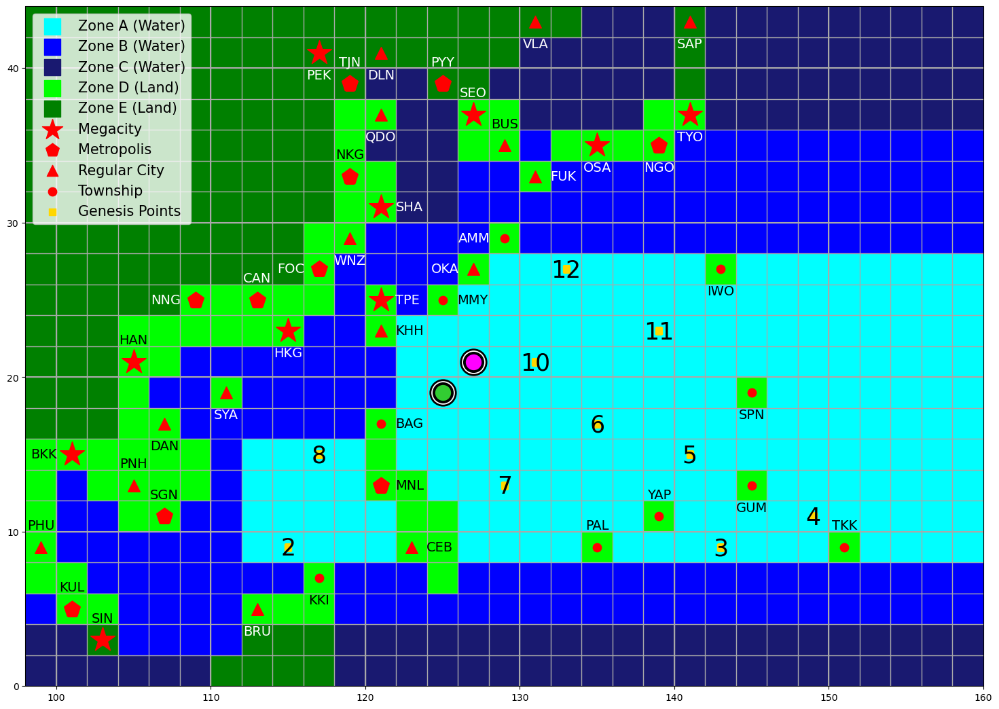


--- End of Demi's turn ---
Demi's current intensity: 130 knots. Demi has gained 70 kJ.
Demi's Accumulated Cyclone Energy: 570 kJ.
Demi's total landfall costs: $1020M.
The ocean has 550 kJ of energy remaining.


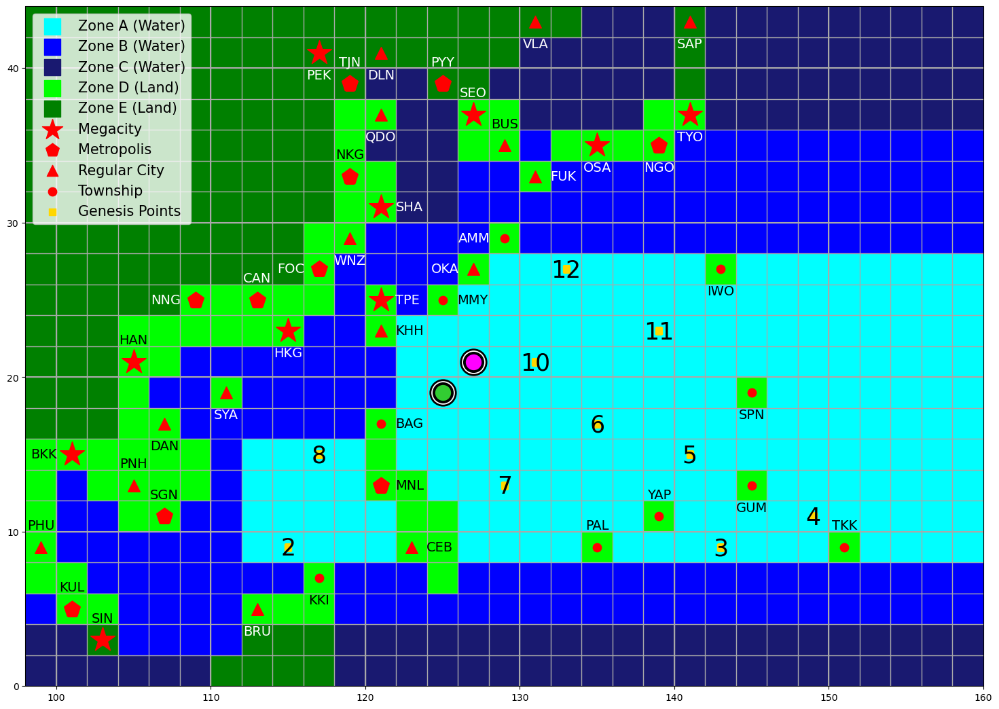

In [76]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 10: Kinen's turn ---


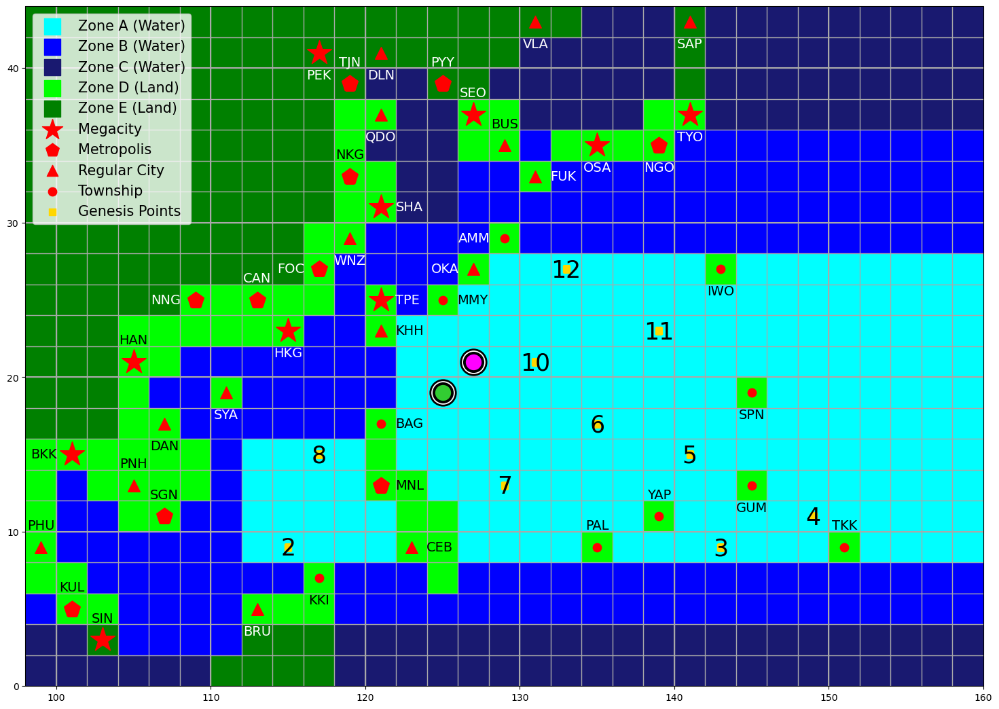

Intensity: 115 knots
Accumulated Cyclone Energy: 380 kJ
Landfall Costs: $1685 M
Landfall Cities: ['KHH', 'TPE', 'NKG', 'SHA']
Hand:
E 1 N 1
W 2
W 4
N 2
+5 W/m^2
+15 W/m^2
Factory Reset

--- Round 10: Kinen's draw phase ---
0: Movement Deck (68 cards left)
1: Intensity Deck (82 cards left)
2: Action Deck (40 cards left)


Choose a deck by index: 1


Kinen drew: +5 W/m^2 from Intensity Deck.

0: Movement Deck (68 cards left)
1: Intensity Deck (81 cards left)
2: Action Deck (40 cards left)


Choose a deck by index: 0


Kinen drew: W/E/N/S 1 from Movement Deck.


--- Round 10: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E 1 N 1
1: W 2
2: W 4
3: N 2
4: +5 W/m^2
5: +15 W/m^2
6: Factory Reset
7: +5 W/m^2
8: W/E/N/S 1
Enter 'd' to discard a card and get a replacement from the same deck.


...

Kinen played: +15 W/m^2

Kinen has intensified to 120 knots!

--- Round 10: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E 1 N 1
1: W 2
2: W 4
3: N 2
4: +5 W/m^2
5: Factory Reset
6: +5 W/m^2
7: W/E/N/S 1
Enter 'p' to pass.


Choose a card by index to play:  4


Kinen played: +5 W/m^2

Kinen has intensified to 125 knots!

--- Round 10: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E 1 N 1
1: W 2
2: W 4
3: N 2
4: Factory Reset
5: +5 W/m^2
6: W/E/N/S 1
Enter 'p' to pass.


Choose a card by index to play:  2


Kinen played: W 4



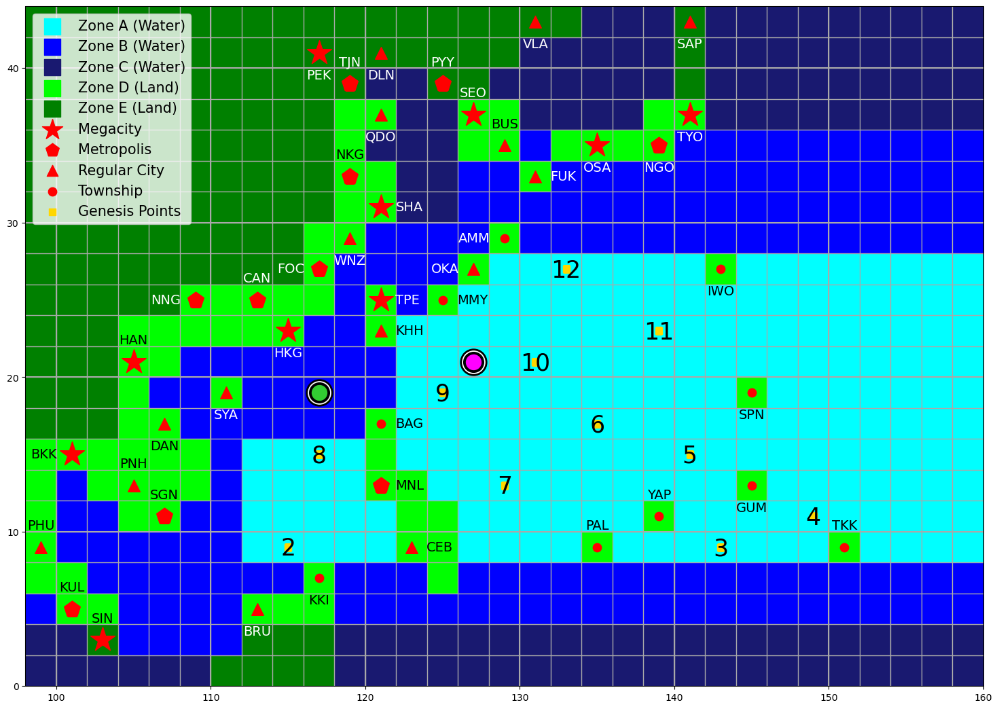


--- End of Kinen's turn ---
Kinen's current intensity: 125 knots. Kinen has gained 70 kJ.
Kinen's Accumulated Cyclone Energy: 450 kJ.
Kinen's total landfall costs: $1685M.
The ocean has 480 kJ of energy remaining.


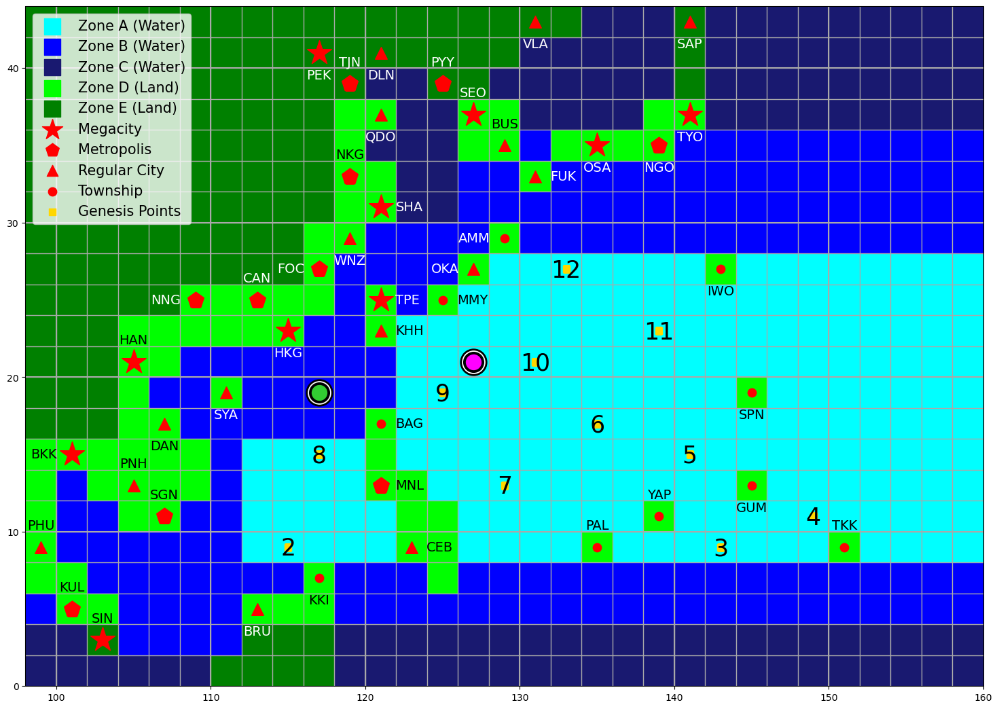

In [77]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 10: Demi's turn ---


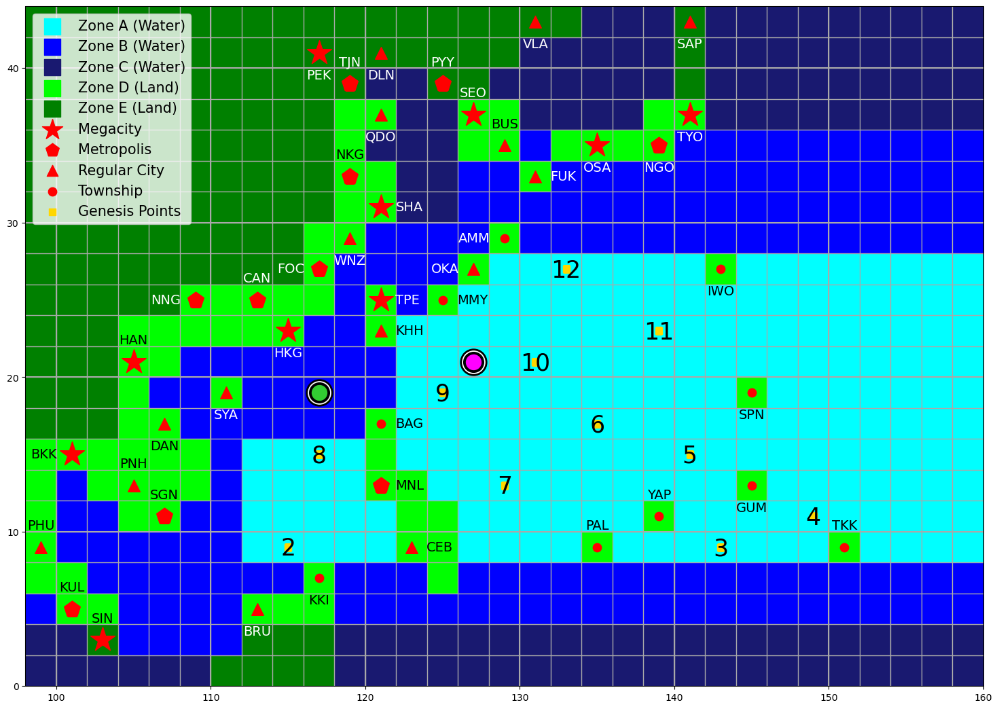

Intensity: 130 knots
Accumulated Cyclone Energy: 570 kJ
Landfall Costs: $1020 M
Landfall Cities: ['KHH', 'BAG', 'WNZ', 'NKG', 'MMY']
Hand:

--- Round 10: Demi's draw phase ---
Demi has no cards left and draws a new 10 card hand.
Demi drew: E 2 from Movement Deck.
Demi drew: E 1 from Movement Deck.
Demi drew: W 1 from Movement Deck.
Demi drew: S 1 from Movement Deck.
Demi drew: +20 W/m^2 from Intensity Deck.
Demi drew: +15 W/m^2 from Intensity Deck.
Demi drew: +5 W/m^2 from Intensity Deck.
Demi drew: +10 W/m^2 from Intensity Deck.
Demi drew: Vertical Wind Shear from Action Deck.
Demi drew: Factory Reset from Action Deck.

--- Round 10: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E 2
1: E 1
2: W 1
3: S 1
4: +20 W/m^2
5: +15 W/m^2
6: +5 W/m^2
7: +10 W/m^2
8: Vertical Wind Shear
9: Factory Reset
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  4


Demi played: +20 W/m^2

Demi has intensified to 140 knots!

--- Round 10: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E 2
1: E 1
2: W 1
3: S 1
4: +15 W/m^2
5: +5 W/m^2
6: +10 W/m^2
7: Vertical Wind Shear
8: Factory Reset
Enter 'p' to pass.


Choose a card by index to play:  7


Demi played: Vertical Wind Shear

Kinen has weakened to 115 knots.

--- Round 10: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E 2
1: E 1
2: W 1
3: S 1
4: +15 W/m^2
5: +5 W/m^2
6: +10 W/m^2
7: Factory Reset
Enter 'p' to pass.


Choose a card by index to play:  2


Demi played: W 1



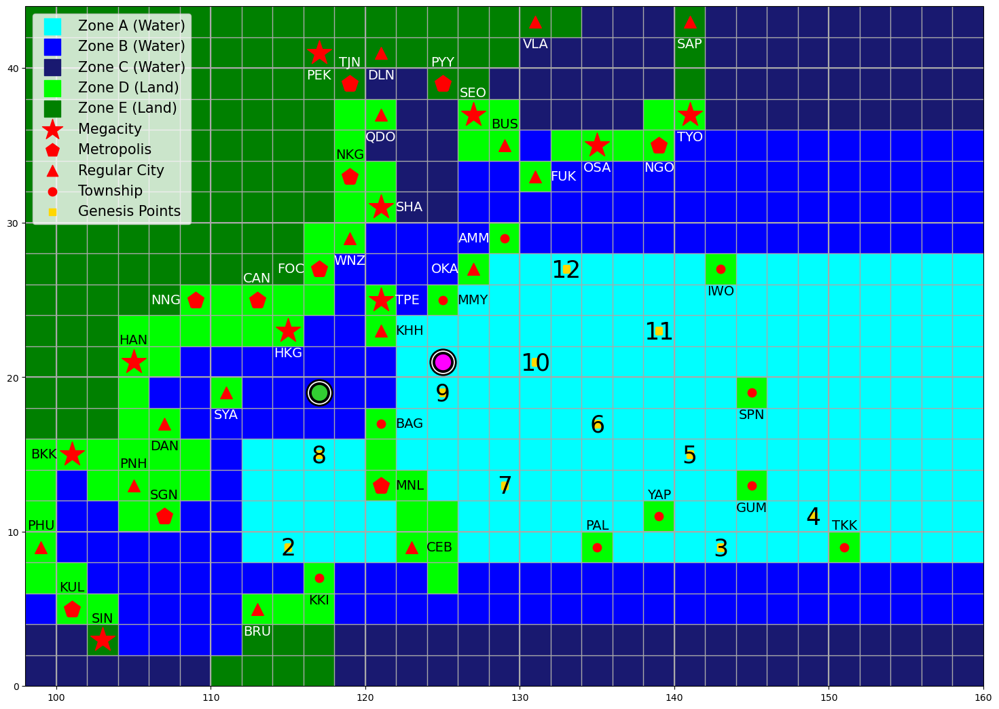


--- End of Demi's turn ---
Demi's current intensity: 140 knots. Demi has gained 100 kJ.
Demi's Accumulated Cyclone Energy: 670 kJ.
Demi's total landfall costs: $1020M.
The ocean has 380 kJ of energy remaining.


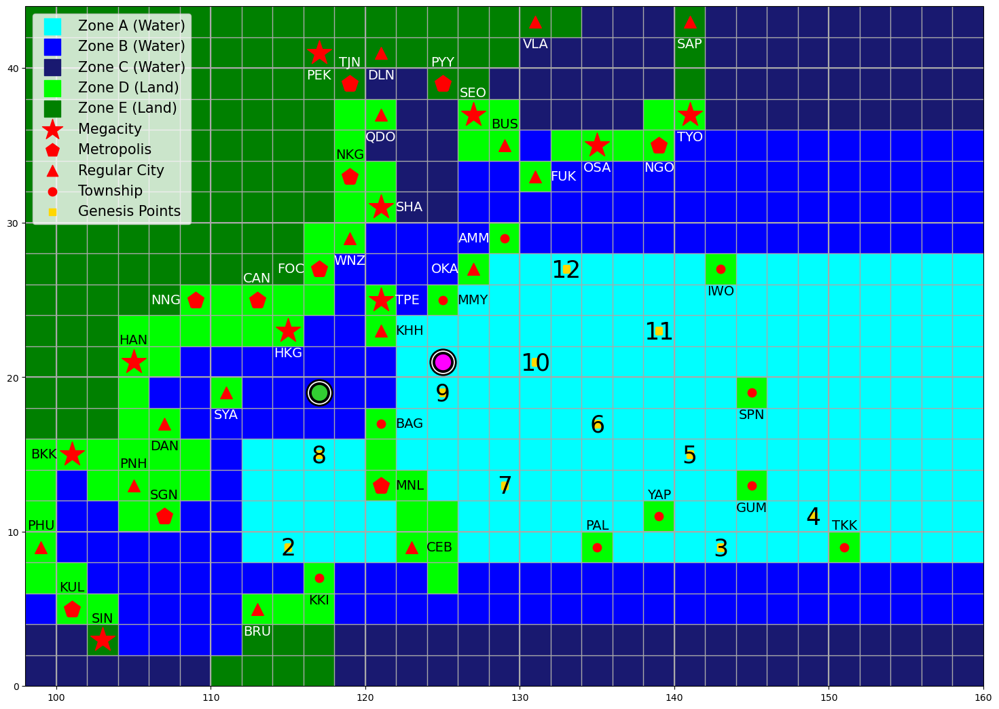

In [78]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 11: Kinen's turn ---


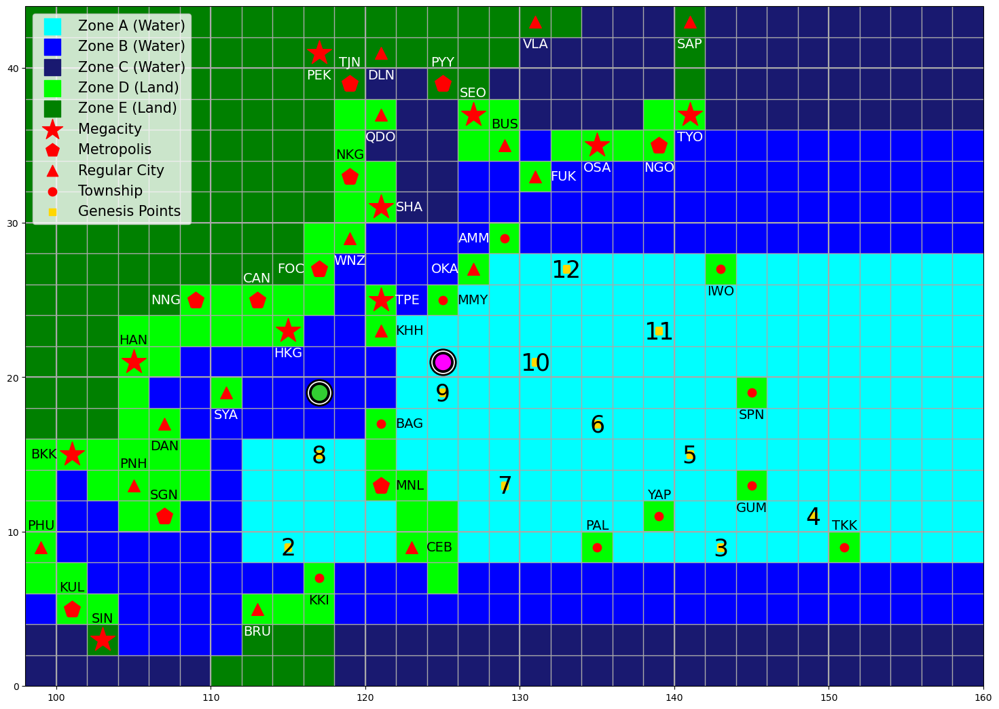

Intensity: 115 knots
Accumulated Cyclone Energy: 450 kJ
Landfall Costs: $1685 M
Landfall Cities: ['KHH', 'TPE', 'NKG', 'SHA']
Hand:
E 1 N 1
W 2
N 2
Factory Reset
+5 W/m^2
W/E/N/S 1

--- Round 11: Kinen's draw phase ---
0: Movement Deck (63 cards left)
1: Intensity Deck (77 cards left)
2: Action Deck (38 cards left)


Choose a deck by index: 2


Kinen drew: Cyclone Express from Action Deck.

0: Movement Deck (63 cards left)
1: Intensity Deck (77 cards left)


Choose a deck by index: 0


Kinen drew: W 2 N 1 from Movement Deck.


--- Round 11: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E 1 N 1
1: W 2
2: N 2
3: Factory Reset
4: +5 W/m^2
5: W/E/N/S 1
6: Cyclone Express (cannot play)
7: W 2 N 1
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  2


Kinen played: N 2



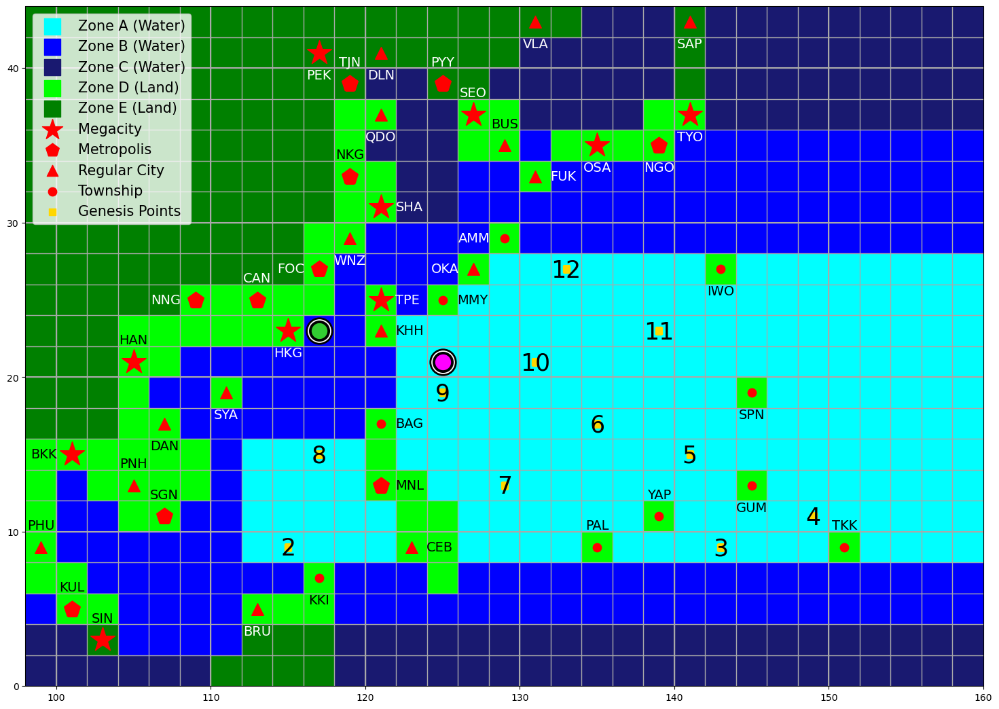


--- Round 11: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E 1 N 1
1: W 2
2: Factory Reset
3: +5 W/m^2
4: W/E/N/S 1
5: Cyclone Express
6: W 2 N 1
Enter 'p' to pass.


Choose a card by index to play:  4


Kinen played: W/E/N/S 1



Choose W, E, N or S:  W


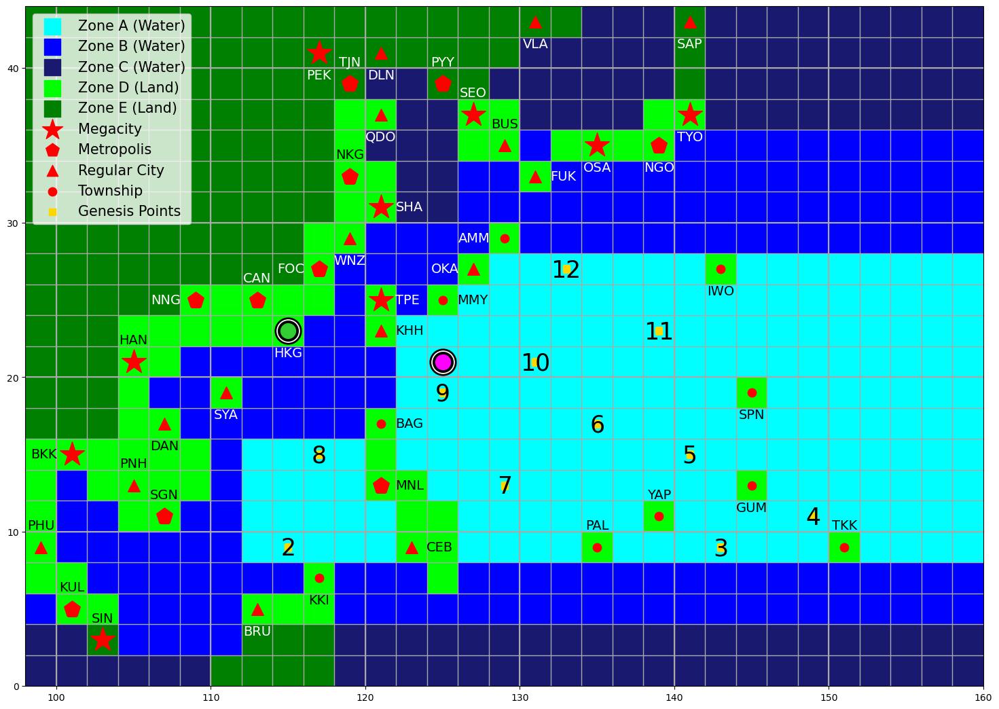

Kinen has made landfall at HKG (Hong Kong) and gains $575M!
Remaining budget of HKG (Hong Kong): $925M.

--- Round 11: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E 1 N 1
1: W 2
2: Factory Reset
3: +5 W/m^2 (cannot play)
4: Cyclone Express
5: W 2 N 1
Enter 'p' to pass.


Choose a card by index to play:  0


Kinen played: E 1 N 1



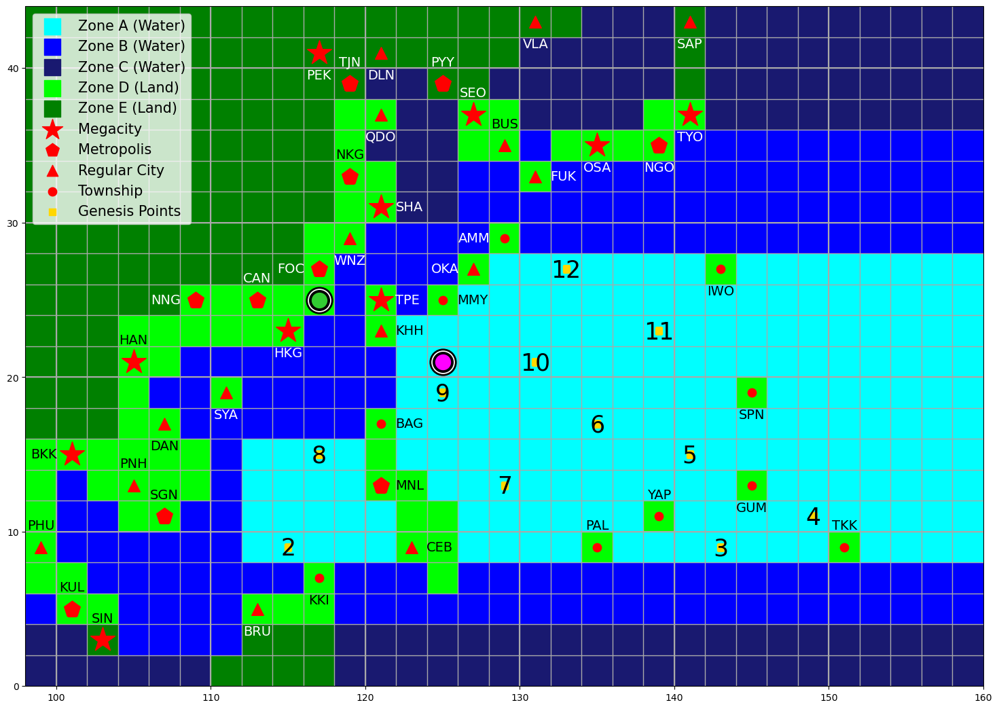


--- End of Kinen's turn ---
Kinen's current intensity: 115 knots. Kinen has gained 50 kJ.
Kinen's Accumulated Cyclone Energy: 500 kJ.
Kinen's total landfall costs: $2260M.
The ocean has 330 kJ of energy remaining.
Kinen has weakened to 110 knots.


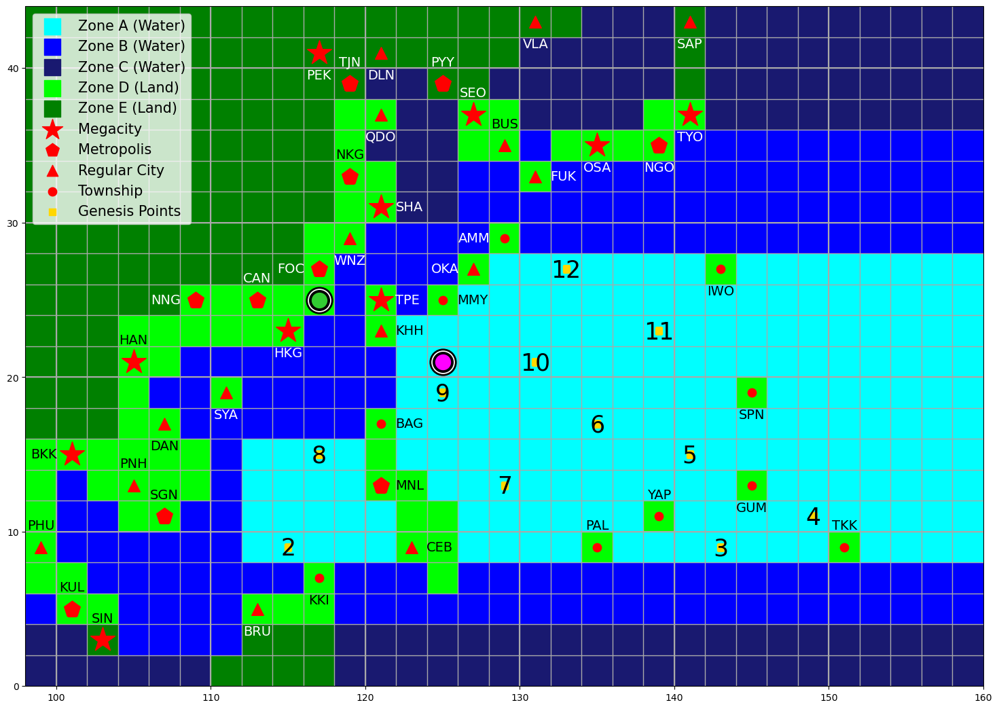

In [79]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 11: Demi's turn ---


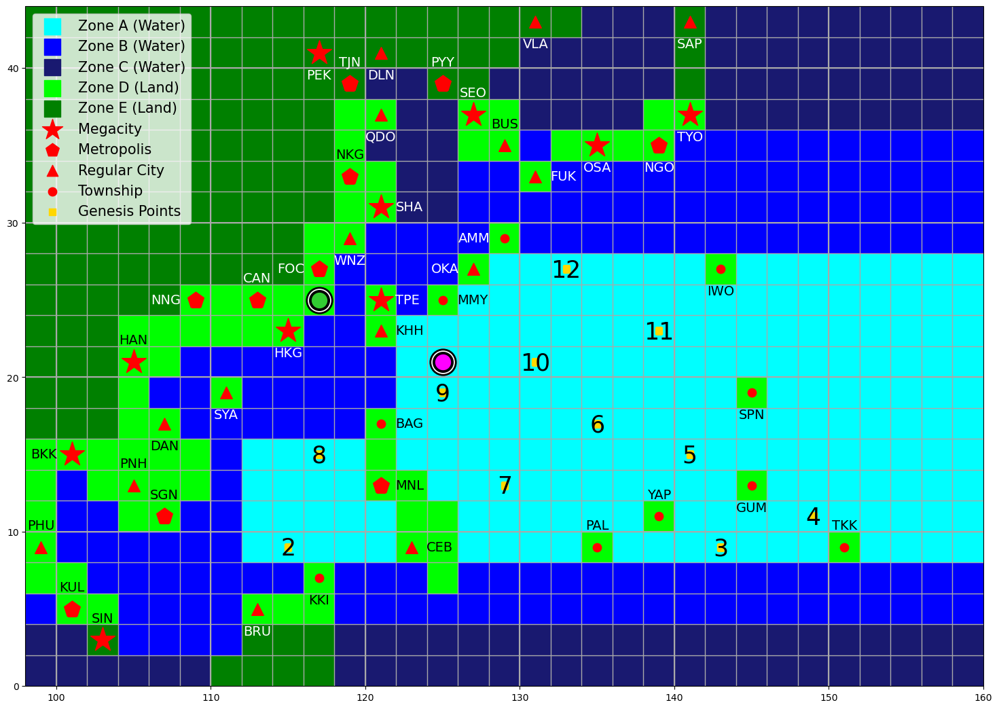

Intensity: 140 knots
Accumulated Cyclone Energy: 670 kJ
Landfall Costs: $1020 M
Landfall Cities: ['KHH', 'BAG', 'WNZ', 'NKG', 'MMY']
Hand:
E 2
E 1
S 1
+15 W/m^2
+5 W/m^2
+10 W/m^2
Factory Reset

--- Round 11: Demi's draw phase ---
0: Movement Deck (62 cards left)
1: Intensity Deck (77 cards left)
2: Action Deck (37 cards left)


Choose a deck by index: 0


Demi drew: W/E 1 from Movement Deck.

0: Movement Deck (61 cards left)
1: Intensity Deck (77 cards left)
2: Action Deck (37 cards left)


Choose a deck by index: 0


Demi drew: N ? from Movement Deck.


--- Round 11: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E 2
1: E 1
2: S 1
3: +15 W/m^2
4: +5 W/m^2
5: +10 W/m^2
6: Factory Reset
7: W/E 1
8: N ?
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  8


Demi played: N ?

Demi rolled 2: N 2


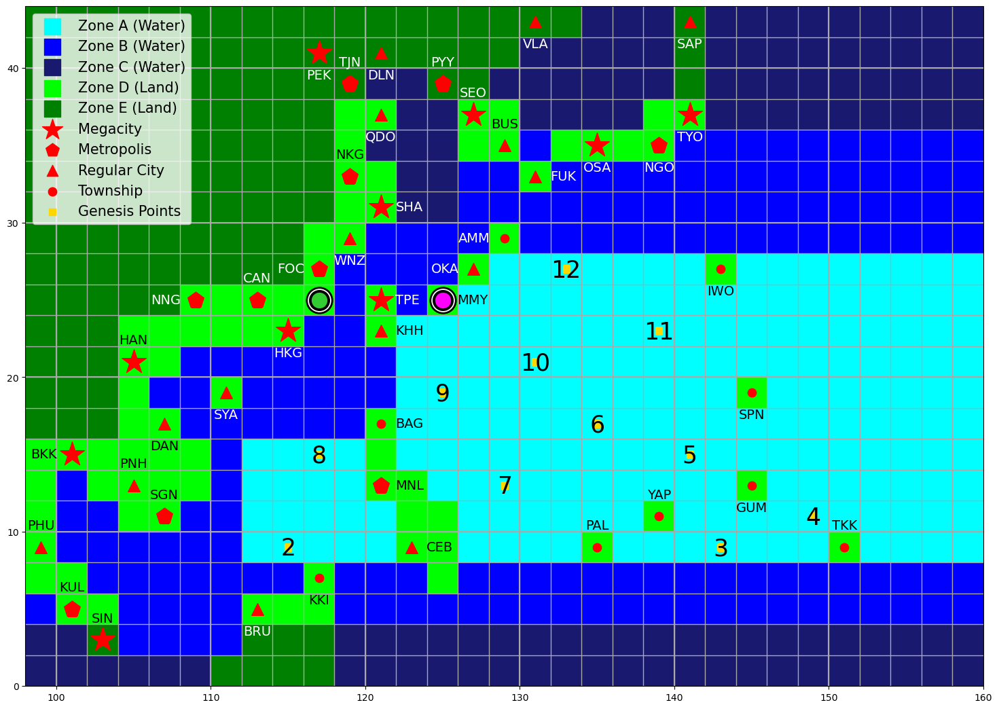

Demi has already made landfall at MMY (Miyakojima) previously. $0M gained.

--- Round 11: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: E 2
1: E 1
2: S 1
3: +15 W/m^2 (cannot play)
4: +5 W/m^2 (cannot play)
5: +10 W/m^2 (cannot play)
6: Factory Reset
7: W/E 1
Enter 'p' to pass.


Choose a card by index to play:  1


Demi played: E 1



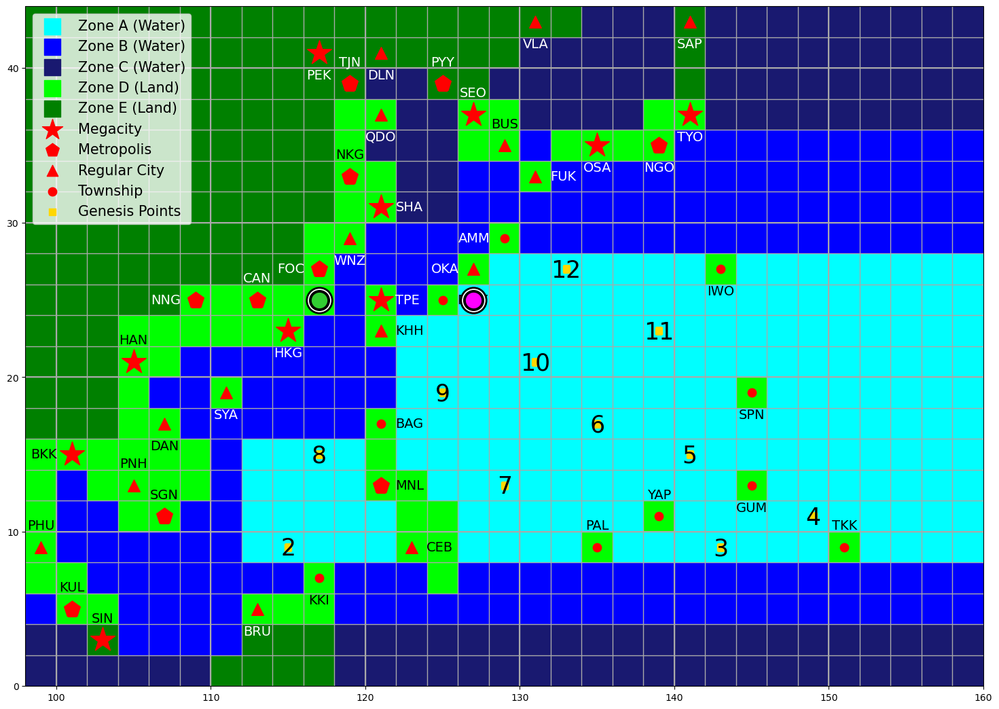


--- Round 11: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: E 2
1: S 1
2: +15 W/m^2
3: +5 W/m^2
4: +10 W/m^2
5: Factory Reset
6: W/E 1
Enter 'p' to pass.


Choose a card by index to play:  2


Demi played: +15 W/m^2

Demi has intensified to 145 knots!

--- End of Demi's turn ---
Demi's current intensity: 145 knots. Demi has gained 100 kJ.
Demi's Accumulated Cyclone Energy: 770 kJ.
Demi's total landfall costs: $1020M.
The ocean has 230 kJ of energy remaining.


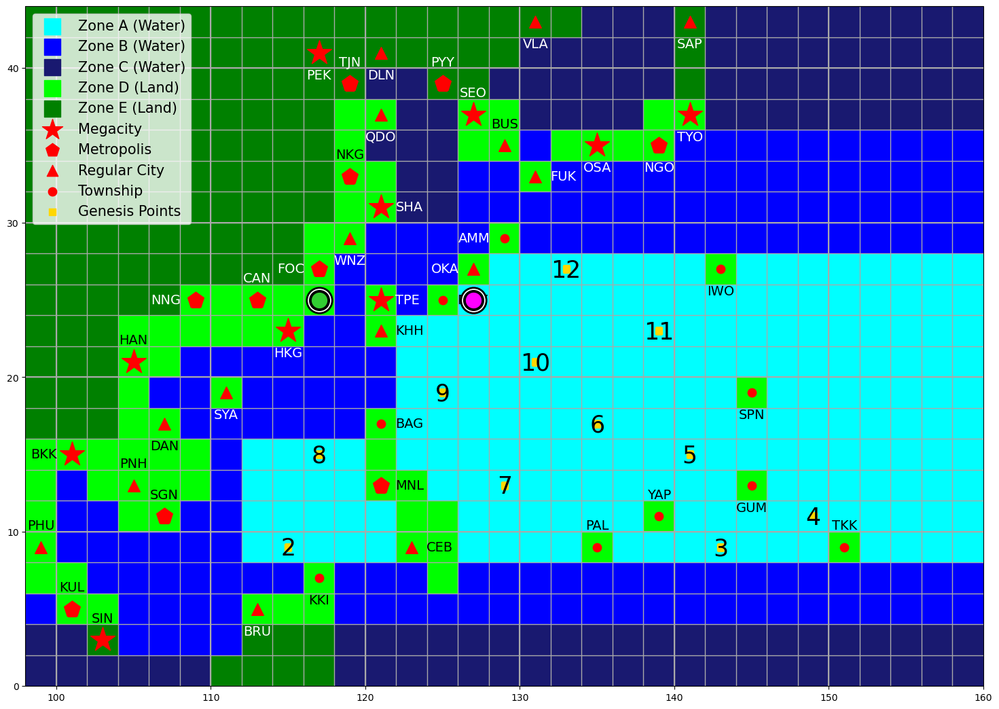

In [80]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 12: Kinen's turn ---


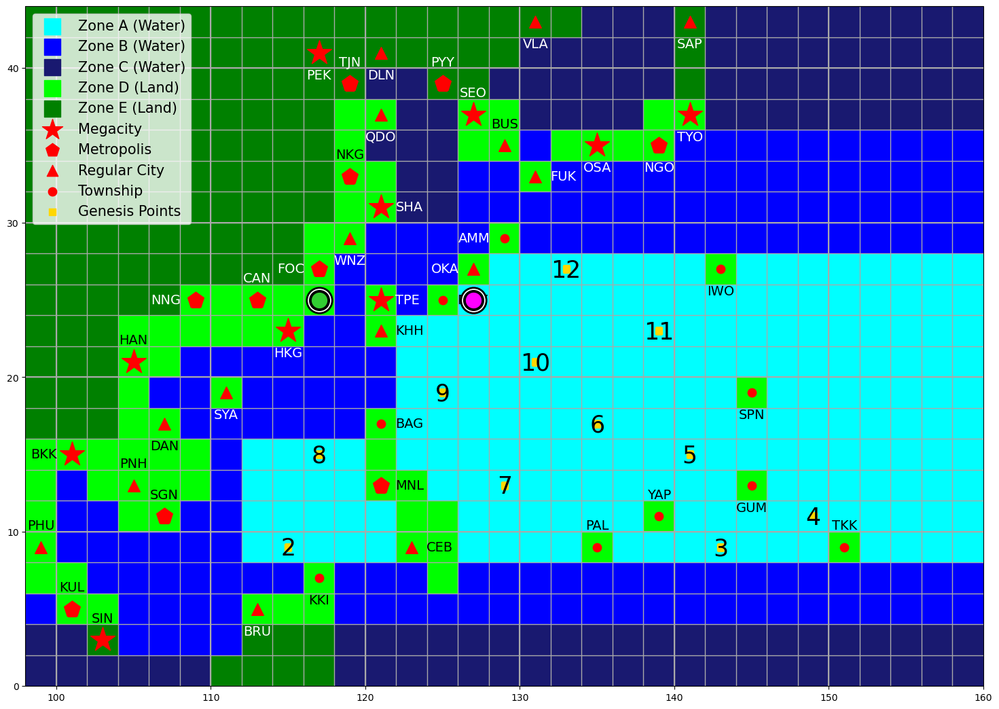

Intensity: 110 knots
Accumulated Cyclone Energy: 500 kJ
Landfall Costs: $2260 M
Landfall Cities: ['KHH', 'TPE', 'NKG', 'SHA', 'HKG']
Hand:
W 2
Factory Reset
+5 W/m^2
Cyclone Express
W 2 N 1

--- Round 12: Kinen's draw phase ---
0: Movement Deck (60 cards left)
1: Intensity Deck (77 cards left)
2: Action Deck (37 cards left)


Choose a deck by index: 0


Kinen drew: W 5 from Movement Deck.

0: Movement Deck (59 cards left)
1: Intensity Deck (77 cards left)
2: Action Deck (37 cards left)


Choose a deck by index: 2


Kinen drew: Cyclone Express from Action Deck.


--- Round 12: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: W 2
1: Factory Reset
2: +5 W/m^2 (cannot play)
3: Cyclone Express (cannot play)
4: W 2 N 1
5: W 5
6: Cyclone Express (cannot play)
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  0


Kinen played: W 2



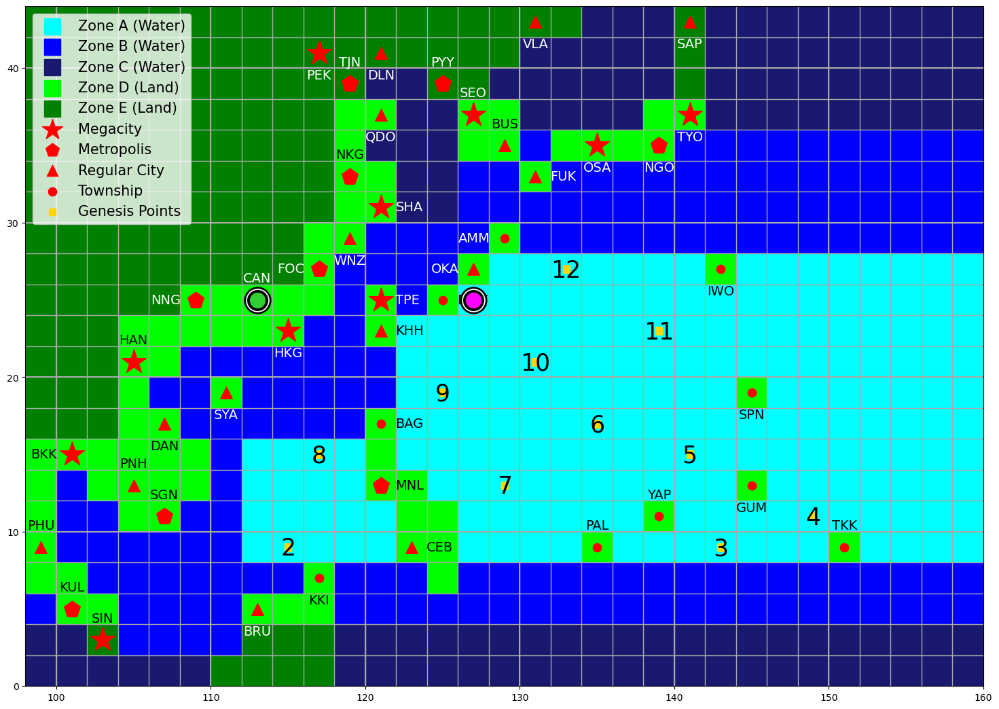

Kinen has made landfall at CAN (Guangzhou) and gains $330M!
Remaining budget of CAN (Guangzhou): $420M.

--- Round 12: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: Factory Reset
1: +5 W/m^2 (cannot play)
2: Cyclone Express
3: W 2 N 1
4: W 5
5: Cyclone Express
Enter 'p' to pass.


Choose a card by index to play:  2


Kinen played: Cyclone Express



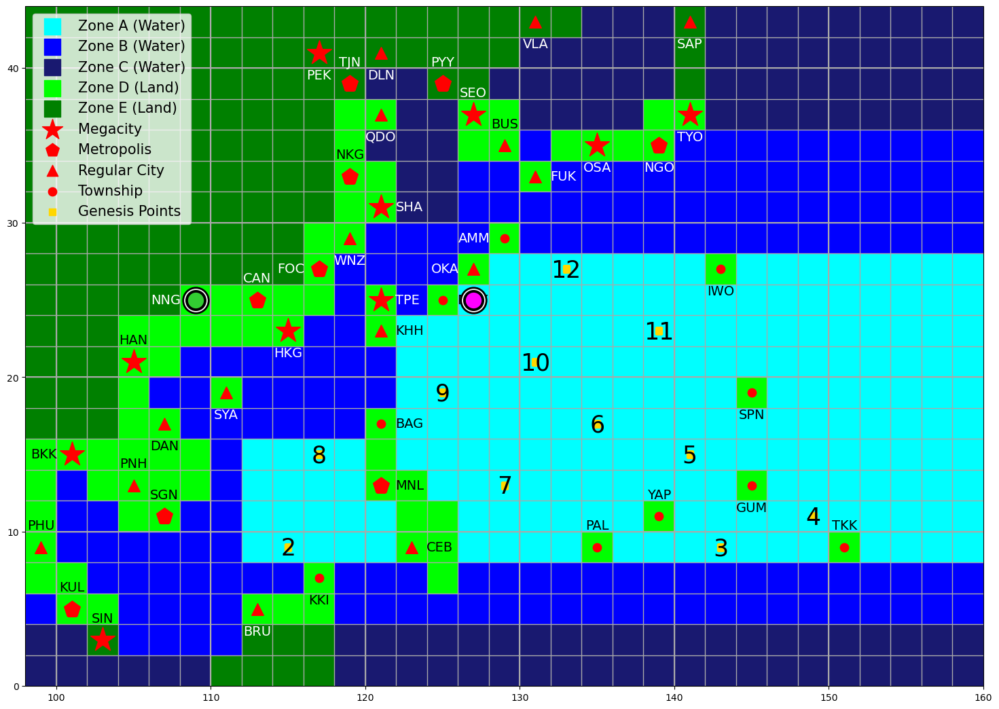

Kinen has made landfall at NNG (Nanning) and gains $330M!
Remaining budget of NNG (Nanning): $420M.

--- Round 12: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: Factory Reset
1: +5 W/m^2 (cannot play)
2: W 2 N 1
3: W 5
4: Cyclone Express (cannot play)
Enter 'p' to pass.


Choose a card by index to play:  0


Kinen played: Factory Reset

Kinen drew: N 1 from Movement Deck.
Kinen drew: S 1 from Movement Deck.
Kinen drew: S 2 from Movement Deck.
Kinen drew: W 2 from Movement Deck.
Kinen drew: +15 W/m^2 from Intensity Deck.
Kinen drew: + ? W/m^2 from Intensity Deck.
Kinen drew: +25 W/m^2 from Intensity Deck.
Kinen drew: +15 W/m^2 from Intensity Deck.
Kinen drew: Rapid Intensification from Action Deck.
Kinen drew: Breaking Free from Action Deck.
Kinen has discarded all current cards and received a new hand.

--- End of Kinen's turn ---
Kinen's current intensity: 110 knots. Kinen has gained 50 kJ.
Kinen's Accumulated Cyclone Energy: 550 kJ.
Kinen's total landfall costs: $2920M.
The ocean has 180 kJ of energy remaining.
Kinen has weakened to 105 knots.


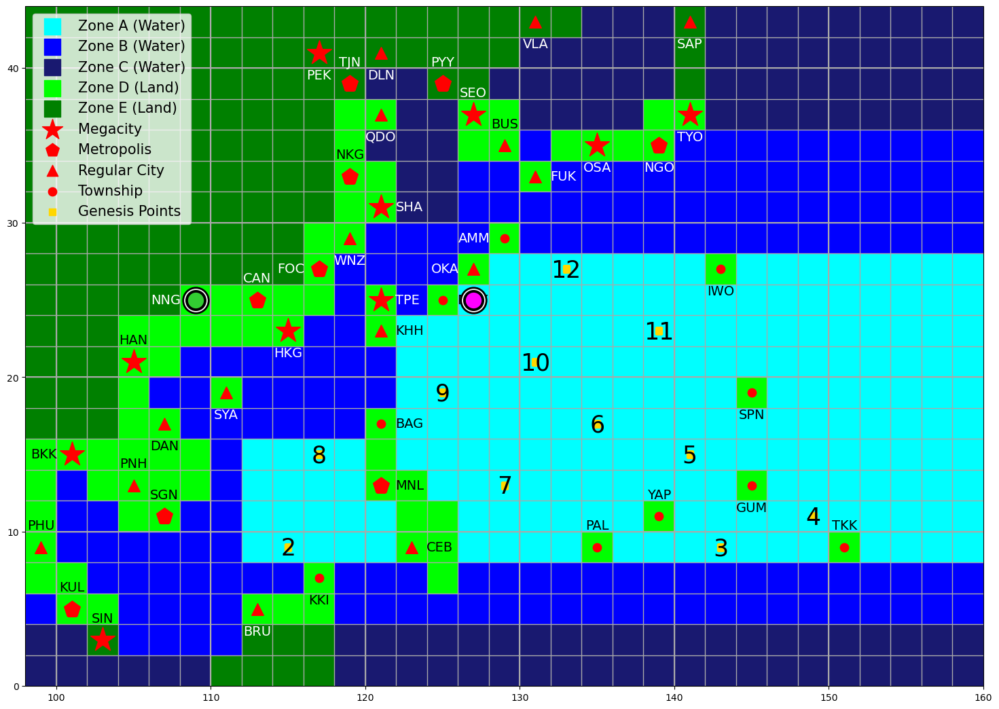

In [81]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 12: Demi's turn ---


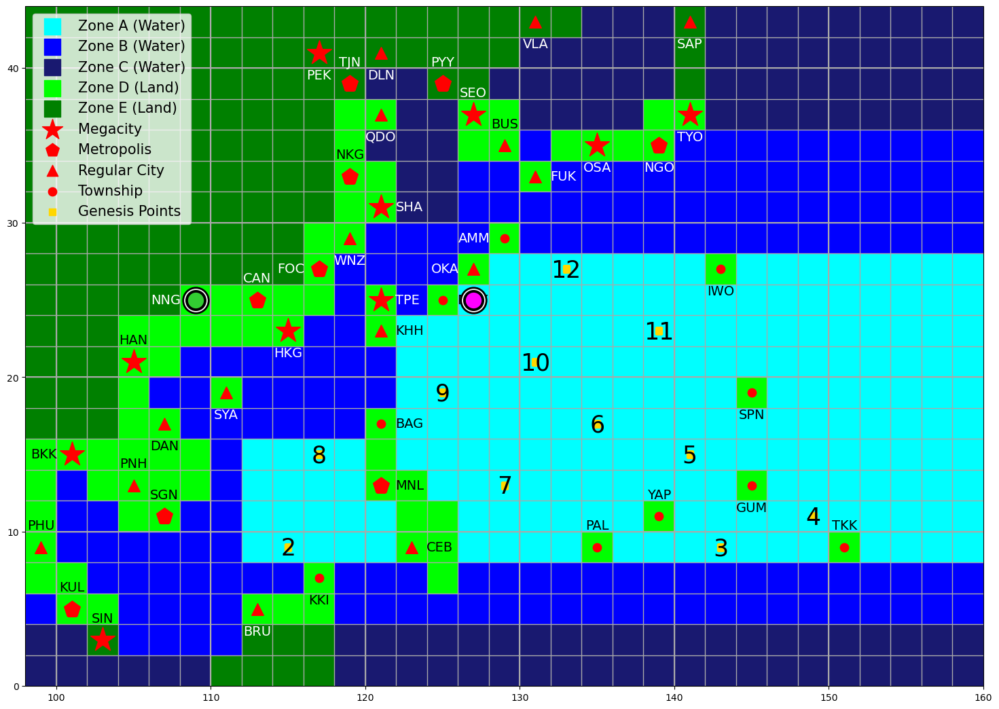

Intensity: 145 knots
Accumulated Cyclone Energy: 770 kJ
Landfall Costs: $1020 M
Landfall Cities: ['KHH', 'BAG', 'WNZ', 'NKG', 'MMY']
Hand:
E 2
S 1
+5 W/m^2
+10 W/m^2
Factory Reset
W/E 1

--- Round 12: Demi's draw phase ---
0: Movement Deck (55 cards left)
1: Intensity Deck (73 cards left)
2: Action Deck (34 cards left)


Choose a deck by index: 0


Demi drew: E 1 from Movement Deck.

0: Movement Deck (54 cards left)
1: Intensity Deck (73 cards left)
2: Action Deck (34 cards left)


Choose a deck by index: 0


Demi drew: W 2 N 1 from Movement Deck.


--- Round 12: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: E 2
1: S 1
2: +5 W/m^2
3: +10 W/m^2
4: Factory Reset
5: W/E 1
6: E 1
7: W 2 N 1
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  4


Demi played: Factory Reset

Demi drew: N 3 from Movement Deck.
Demi drew: S 2 from Movement Deck.
Demi drew: W 1 S 1 from Movement Deck.
Demi drew: N 5 from Movement Deck.
Demi drew: +5 W/m^2 from Intensity Deck.
Demi drew: +5 W/m^2 from Intensity Deck.
Demi drew: +15 W/m^2 from Intensity Deck.
Demi drew: +5 W/m^2 from Intensity Deck.
Demi drew: Rapid Intensification from Action Deck.
Demi drew: Rapid Intensification from Action Deck.
Demi has discarded all current cards and received a new hand.

--- Round 12: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: N 3
1: S 2
2: W 1 S 1
3: N 5
4: +5 W/m^2
5: +5 W/m^2
6: +15 W/m^2
7: +5 W/m^2
8: Rapid Intensification (cannot play)
9: Rapid Intensification (cannot play)
Enter 'p' to pass.


Choose a card by index to play:  0


Demi played: N 3



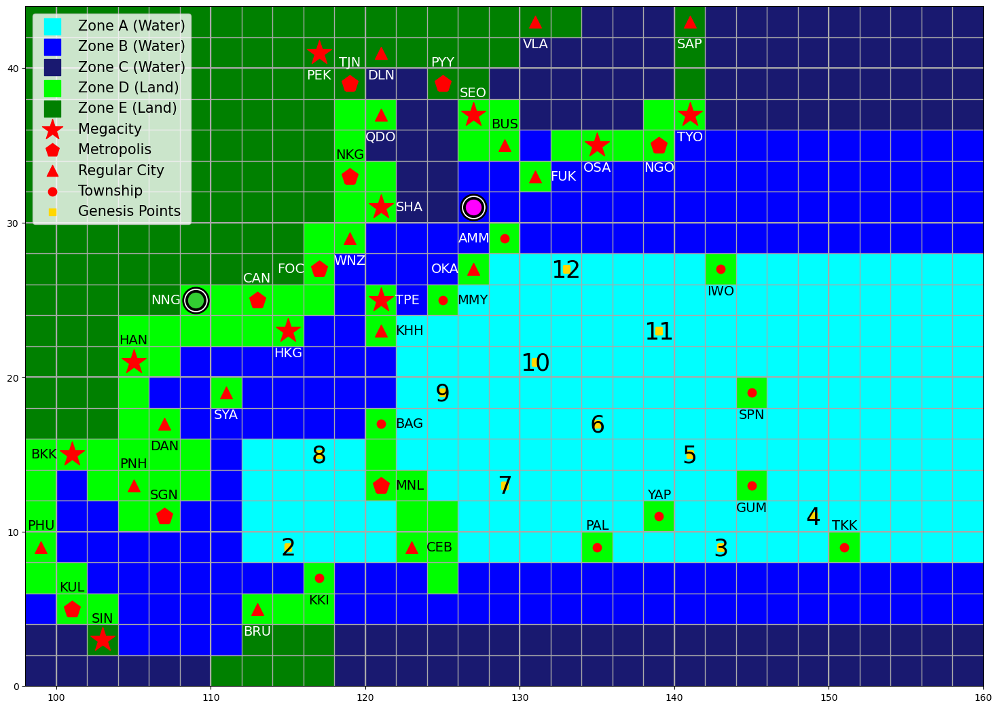


--- Round 12: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: S 2
1: W 1 S 1
2: N 5
3: +5 W/m^2
4: +5 W/m^2
5: +15 W/m^2
6: +5 W/m^2
7: Rapid Intensification (cannot play)
8: Rapid Intensification (cannot play)
Enter 'p' to pass.


Choose a card by index to play:  0


Demi played: S 2



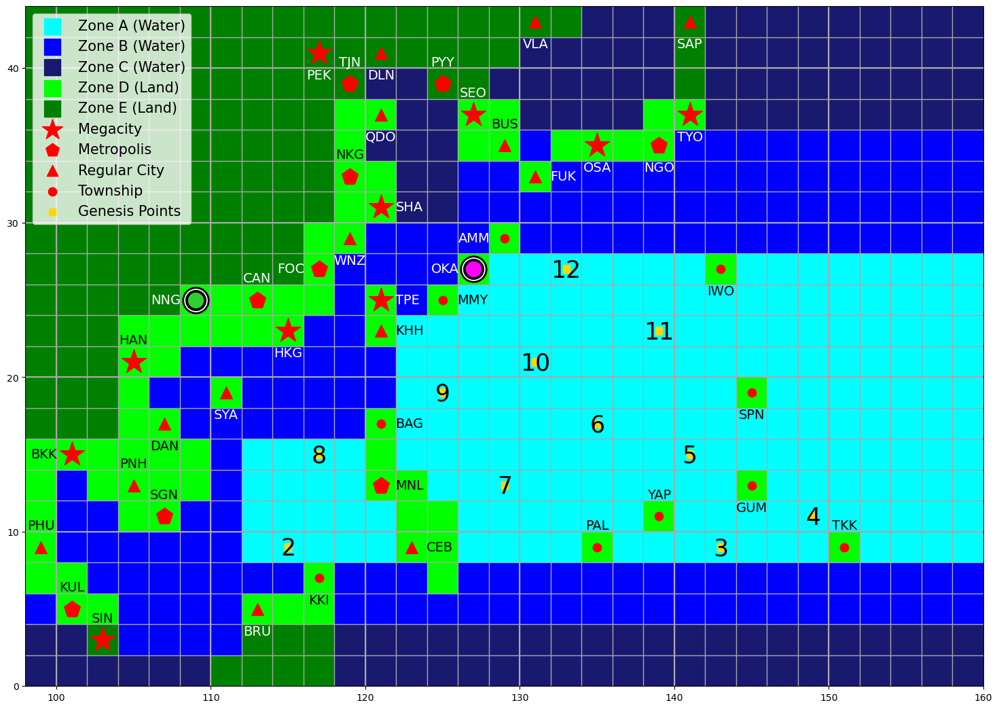

Demi has made landfall at OKA (Okinawa) and gains $290M!
Remaining budget of OKA (Okinawa): $110M.

--- End of Demi's turn ---
Demi's current intensity: 145 knots. Demi has gained 100 kJ.
Demi's Accumulated Cyclone Energy: 870 kJ.
Demi's total landfall costs: $1310M.
The ocean has 80 kJ of energy remaining.
Demi has weakened to 140 knots.


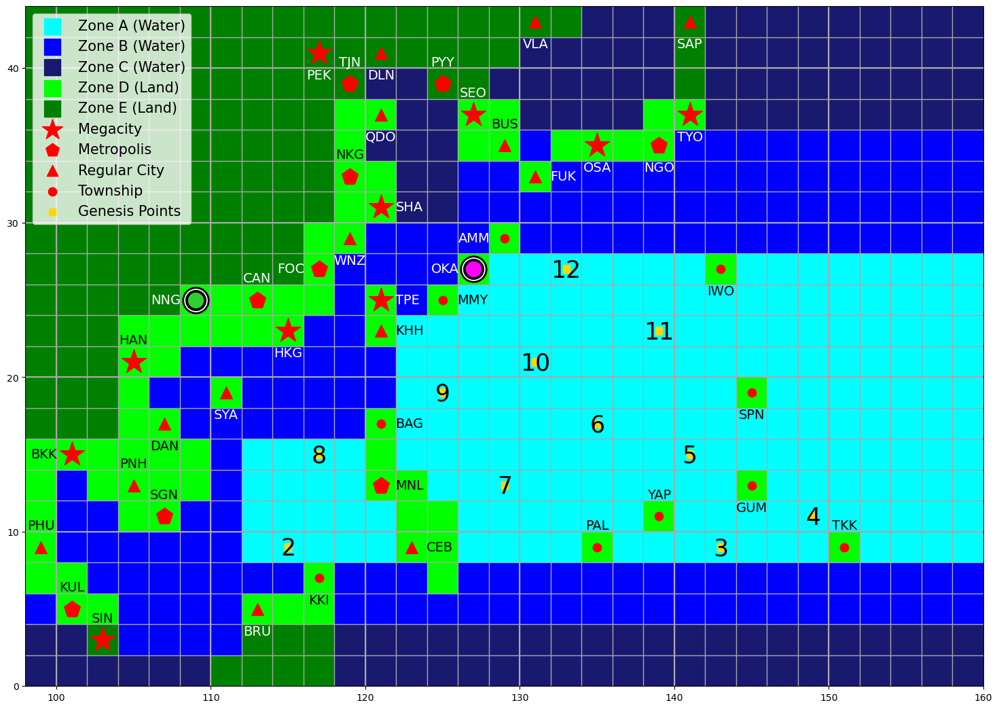

In [94]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 13: Kinen's turn ---


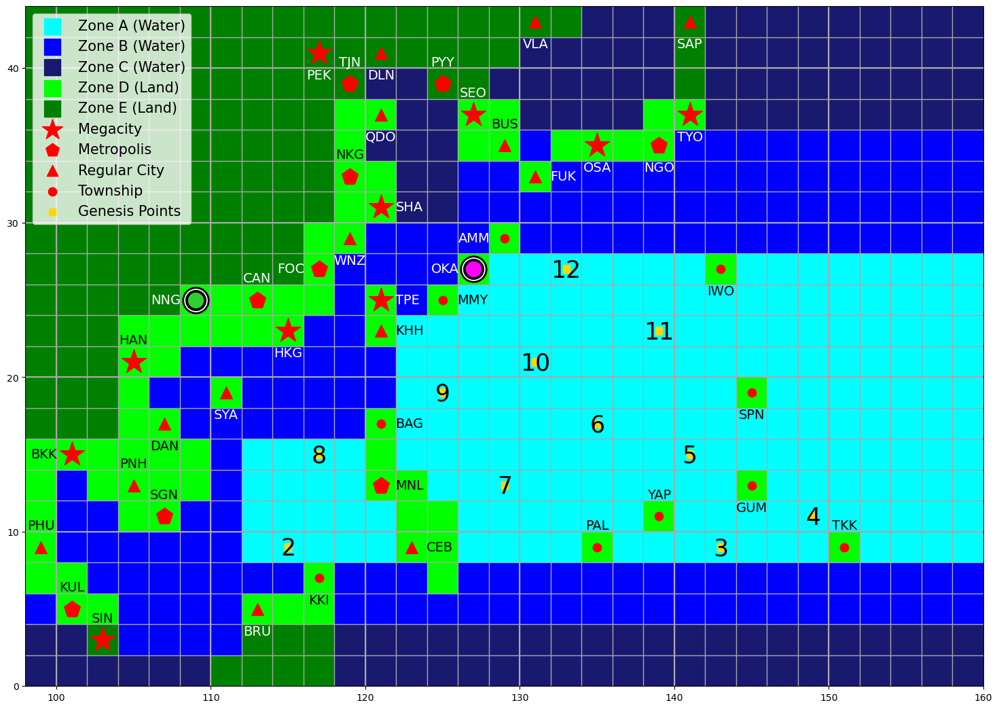

Intensity: 105 knots
Accumulated Cyclone Energy: 550 kJ
Landfall Costs: $2920 M
Landfall Cities: ['KHH', 'TPE', 'NKG', 'SHA', 'HKG', 'CAN', 'NNG']
Hand:
N 1
S 1
S 2
W 2
+15 W/m^2
+ ? W/m^2
+25 W/m^2
+15 W/m^2
Rapid Intensification
Breaking Free

--- Round 13: Kinen's draw phase ---
0: Movement Deck (49 cards left)
1: Intensity Deck (69 cards left)
2: Action Deck (32 cards left)


Choose a deck by index: 0


Kinen drew: S ? from Movement Deck.

0: Movement Deck (48 cards left)
1: Intensity Deck (69 cards left)
2: Action Deck (32 cards left)


Choose a deck by index: 0


Kinen drew: N 1 from Movement Deck.


--- Round 13: Kinen's playing phase ---
Cards played this round: 0 / 3
Hand:
0: N 1
1: S 1
2: S 2
3: W 2
4: +15 W/m^2 (cannot play)
5: + ? W/m^2 (cannot play)
6: +25 W/m^2 (cannot play)
7: +15 W/m^2 (cannot play)
8: Rapid Intensification (cannot play)
9: Breaking Free
10: S ?
11: N 1
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  2


Kinen played: S 2



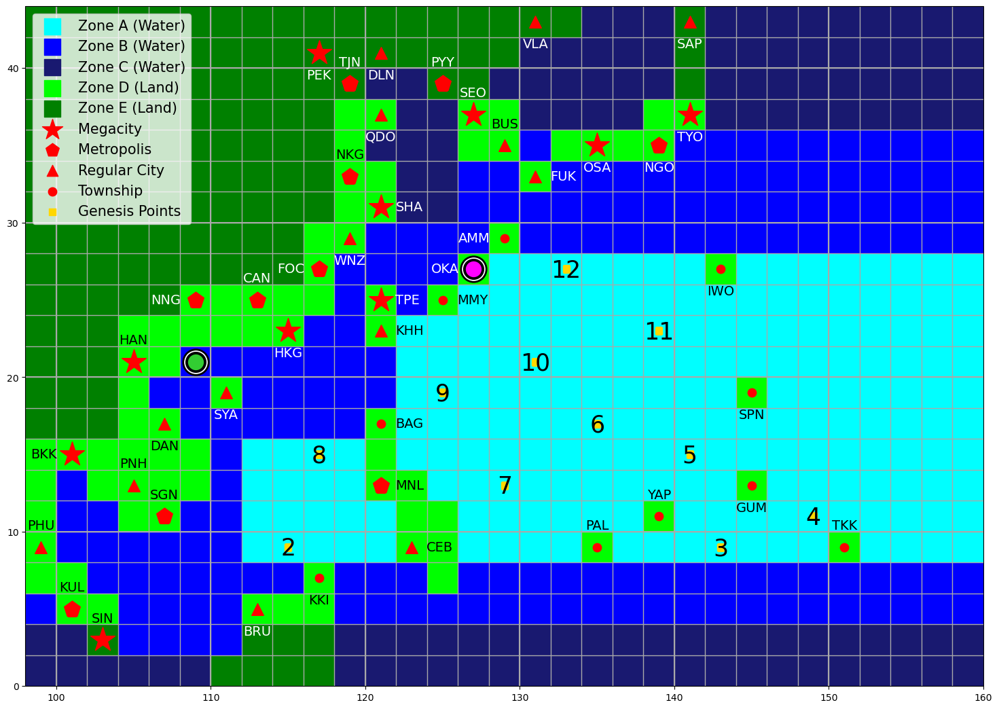


--- Round 13: Kinen's playing phase ---
Cards played this round: 1 / 3
Hand:
0: N 1
1: S 1
2: W 2
3: +15 W/m^2
4: + ? W/m^2
5: +25 W/m^2
6: +15 W/m^2
7: Rapid Intensification (cannot play)
8: Breaking Free
9: S ?
10: N 1
Enter 'p' to pass.


Choose a card by index to play:  2


Kinen played: W 2



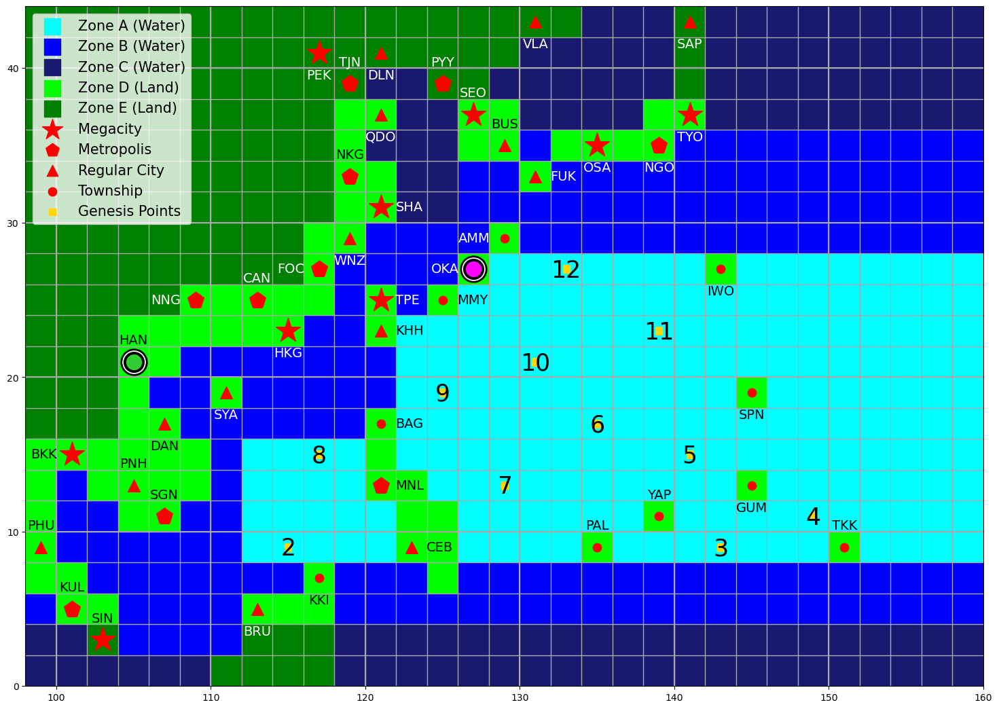

Kinen has made landfall at HAN (Hanoi) and gains $525M!
Remaining budget of HAN (Hanoi): $975M.

--- Round 13: Kinen's playing phase ---
Cards played this round: 2 / 3
Hand:
0: N 1
1: S 1
2: +15 W/m^2 (cannot play)
3: + ? W/m^2 (cannot play)
4: +25 W/m^2 (cannot play)
5: +15 W/m^2 (cannot play)
6: Rapid Intensification (cannot play)
7: Breaking Free
8: S ?
9: N 1
Enter 'p' to pass.


Choose a card by index to play:  8


Kinen played: S ?

Kinen rolled 3: S 3


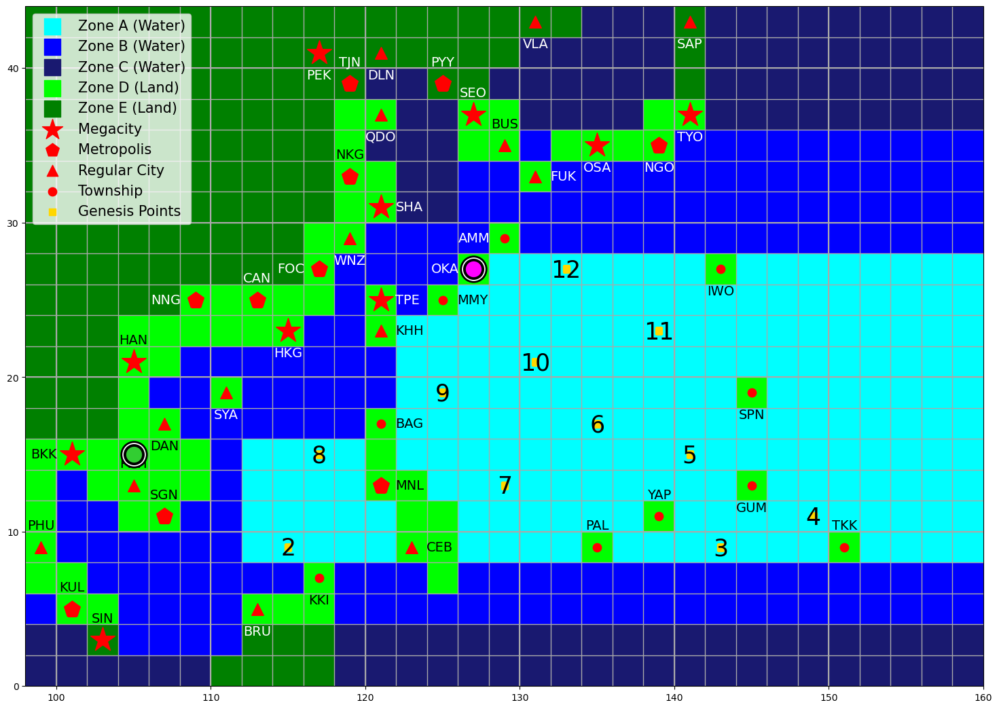


--- End of Kinen's turn ---
Kinen's current intensity: 105 knots. Kinen has gained 50 kJ.
Kinen's Accumulated Cyclone Energy: 600 kJ.
Kinen's total landfall costs: $3445M.
The ocean has 30 kJ of energy remaining.
Kinen has weakened to 100 knots.


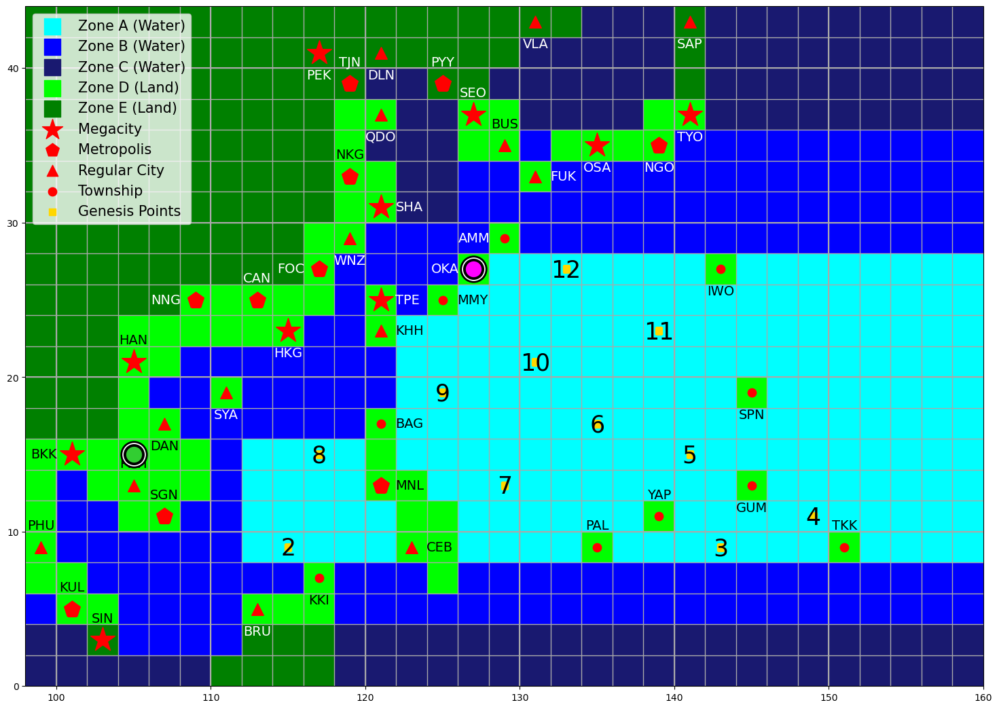

In [95]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)


--- Round 13: Demi's turn ---


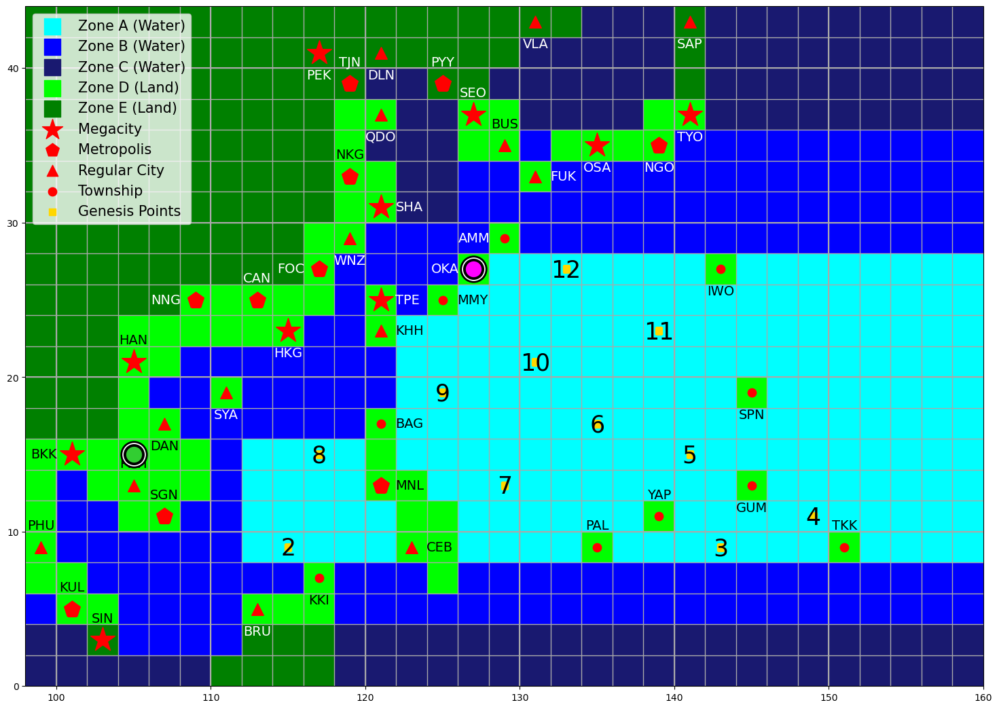

Intensity: 140 knots
Accumulated Cyclone Energy: 870 kJ
Landfall Costs: $1310 M
Landfall Cities: ['KHH', 'BAG', 'WNZ', 'NKG', 'MMY', 'OKA']
Hand:
W 1 S 1
N 5
+5 W/m^2
+5 W/m^2
+15 W/m^2
+5 W/m^2
Rapid Intensification
Rapid Intensification

--- Round 13: Demi's draw phase ---
0: Movement Deck (47 cards left)
1: Intensity Deck (69 cards left)
2: Action Deck (32 cards left)


Choose a deck by index: 0


Demi drew: N/S 1 from Movement Deck.

0: Movement Deck (46 cards left)
1: Intensity Deck (69 cards left)
2: Action Deck (32 cards left)


Choose a deck by index: 0


Demi drew: N 3 from Movement Deck.


--- Round 13: Demi's playing phase ---
Cards played this round: 0 / 3
Hand:
0: W 1 S 1
1: N 5
2: +5 W/m^2 (cannot play)
3: +5 W/m^2 (cannot play)
4: +15 W/m^2 (cannot play)
5: +5 W/m^2 (cannot play)
6: Rapid Intensification (cannot play)
7: Rapid Intensification (cannot play)
8: N/S 1
9: N 3
Enter 'd' to discard a card and get a replacement from the same deck.


Choose a card by index to play:  1


Demi played: N 5



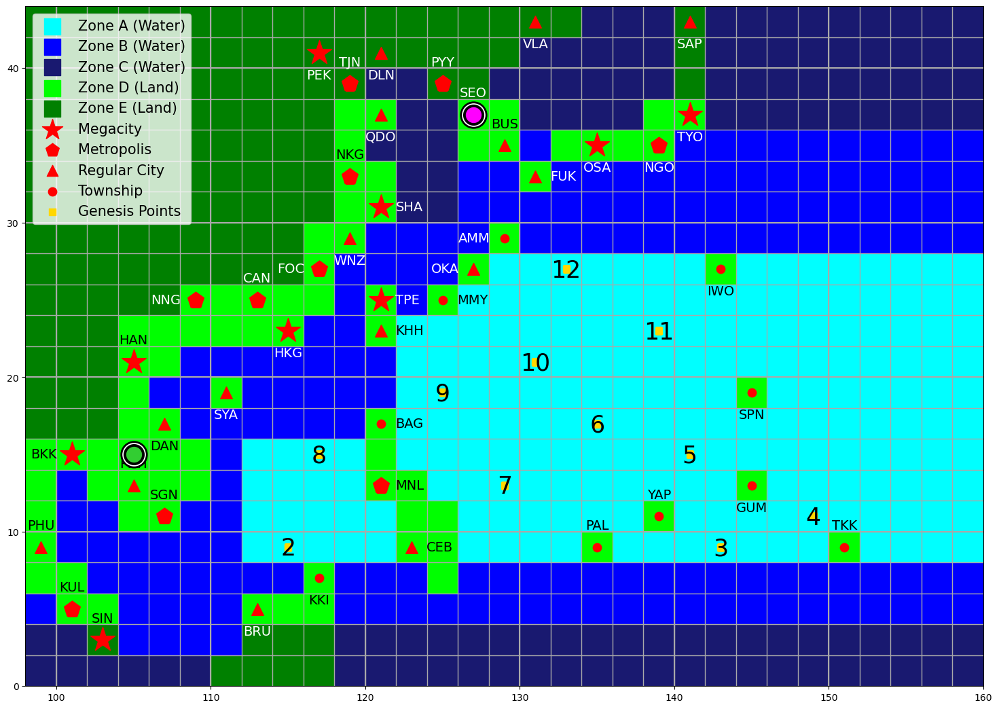

Demi has made landfall at SEO (Seoul) and gains $700M!
Remaining budget of SEO (Seoul): $800M.

--- Round 13: Demi's playing phase ---
Cards played this round: 1 / 3
Hand:
0: W 1 S 1
1: +5 W/m^2 (cannot play)
2: +5 W/m^2 (cannot play)
3: +15 W/m^2 (cannot play)
4: +5 W/m^2 (cannot play)
5: Rapid Intensification (cannot play)
6: Rapid Intensification (cannot play)
7: N/S 1
8: N 3
Enter 'p' to pass.


Choose a card by index to play:  7


Demi played: N/S 1



Choose N or S:  N


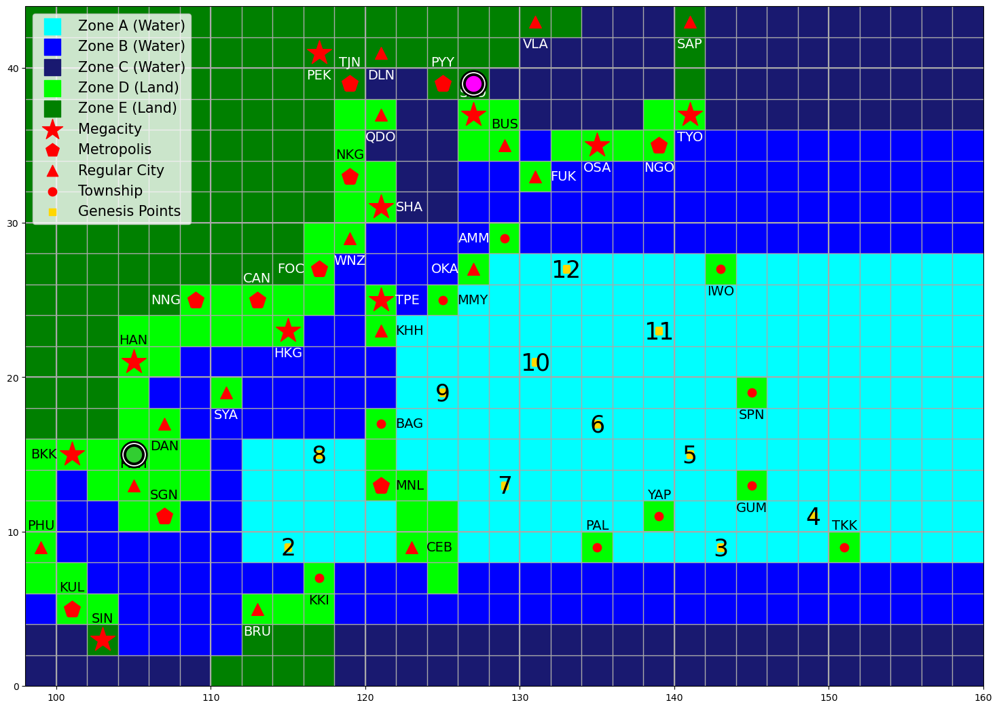


--- Round 13: Demi's playing phase ---
Cards played this round: 2 / 3
Hand:
0: W 1 S 1
1: +5 W/m^2 (cannot play)
2: +5 W/m^2 (cannot play)
3: +15 W/m^2 (cannot play)
4: +5 W/m^2 (cannot play)
5: Rapid Intensification (cannot play)
6: Rapid Intensification (cannot play)
7: N 3
Enter 'p' to pass.


Choose a card by index to play:  0


Demi played: W 1 S 1



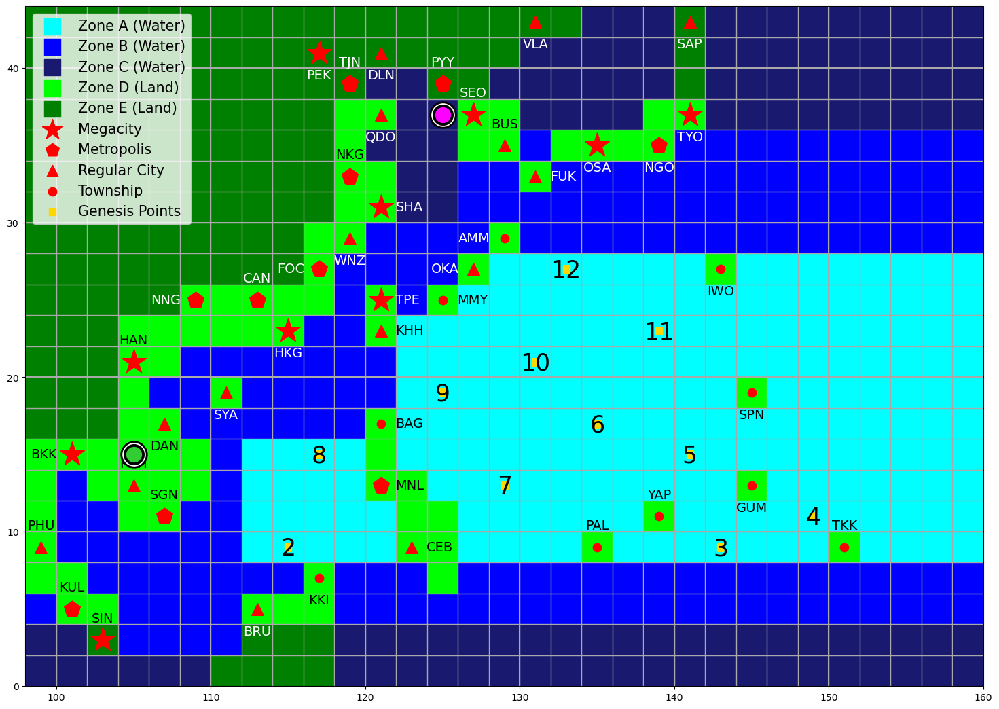


--- End of Demi's turn ---
Demi's current intensity: 140 knots. Demi has gained 100 kJ.
Demi's Accumulated Cyclone Energy: 970 kJ.
Demi's total landfall costs: $2010M.
The ocean has 0 kJ of energy remaining.

Ocean ACE has been depleted!
All remaining players will complete their turns this round.
Demi has weakened to 135 knots.


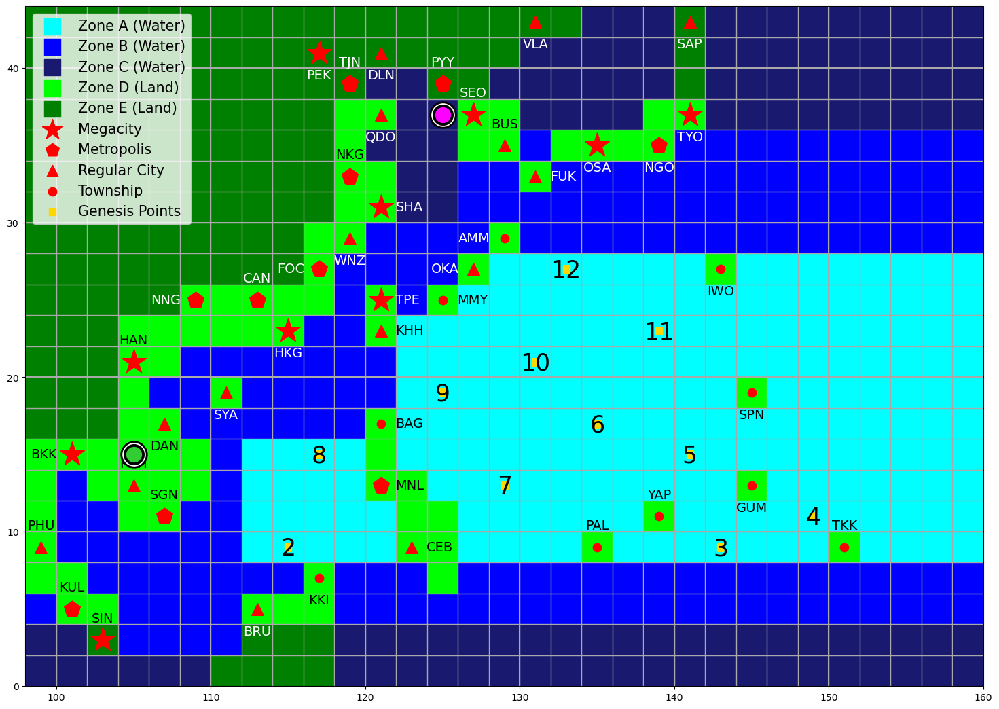

In [96]:
Run_Turn(n_Players, Player_Data, Game_State, Player_Data_History, Game_State_History)

## Final Results

In [100]:
End_Game(Player_Data, Game_State)


========== FINAL RESULTS ==========

1. Kinen
Accumulated Cyclone Energy: 600 kJ
Landfall Costs: $3445M
Landfall Cities: ['KHH', 'TPE', 'NKG', 'SHA', 'HKG', 'CAN', 'NNG', 'HAN']
Landfall Cities Count: 8 (Rank 1, +250 points)
Peak Intensity: 125 kt (Rank 2, + 100 points)
Final Score: 4395

2. Demi
Accumulated Cyclone Energy: 970 kJ
Landfall Costs: $2010M
Landfall Cities: ['KHH', 'BAG', 'WNZ', 'NKG', 'MMY', 'OKA', 'SEO']
Landfall Cities Count: 7 (Rank 2, +100 points)
Peak Intensity: 145 kt (Rank 1, + 250 points)
Final Score: 3330
